# How much astronomical information can we destroy? Results notebook

One notebook for every run of the GZD5 augmentation study: loading, inventory, per-modality views, strength (dose-response), cross-modality comparison, training dynamics, statistics, conclusions with a claim check, and export.

**How to use it**

1. Edit the **config cell** below and nothing else. `MODALITY` switches sections C–D between `rrc` (RandomResizedCrop), `rc` (fixed-size random crop), `wt` (policy after Walmsley transforms) and `all`.
2. Run all cells. Sections B, E, F and H always use every modality.
3. Figures go to `FIG_DIR/<MODALITY>/` (PNG + PDF) and tables to `TABLE_DIR/` (CSV + LaTeX).

**Precision.** With `SOURCE = "log"` and `LOG_PRECISION = "high"`, metrics come from the `optastra.eval ... eval at iter N/M` line of `log.log`. That line carries `val_total_loss` to **4 decimals**. The `Final eval metrics` line used by the old `results.py` rounds it to 2 decimals. The notebook falls back to the 2-decimal line only for evals that have no 4-decimal line, and it warns if that happens. The existing `logs/metrics.jsonl` files contain only `val_step_*` records, so `SOURCE = "jsonl"` currently finds nothing.

**Metric of record (`EVAL_SPLIT`):** each run's best checkpoint is selected by the lowest logged validation loss, the checkpoint early stopping keeps. With `EVAL_SPLIT = "test"` (the default), every number, table and figure in sections A–J uses that checkpoint's metrics on the **test split** (`TEST.json`, written by `evaluate.py`), so the column names are `test_*`. With `"val"`, they use the logged validation metrics (`val_*`). Training curves and best epochs (section F) always come from the validation logs. `total_loss` is the unweighted **sum** of the 10 per-question losses, so the notebook always shows per-task results next to it.

In [1]:
import os
# ============================ CONFIG (the only cell to edit) ============================
from pathlib import Path

RUNS_ROOT       = Path("/zfsstore/user/s4861264/projects/astro_augment/runs")
SOURCE          = "log"          # "log" -> <run>/log.log ; "jsonl" -> <run>/logs/metrics.jsonl
LOG_PRECISION   = "high"         # "high": 'optastra.eval' line (4 d.p. total loss) ; "final": 'Final eval metrics' line (2 d.p.)
EVAL_SPLIT      = "test"         # "test": metrics of the best (val-selected) checkpoint on the test split (<run>/TEST.json,
                                 #         from evaluate.py) ; "val": the logged validation metrics of that checkpoint
EXPECTED_SEEDS  = ["42", "123", "456", "789", "101112"]
STRICT_SEEDS    = True           # drop seeds not in EXPECTED_SEEDS, with a warning listing them
MODALITY        = "rc"           # "rrc" | "rc" | "wt" | "all"
REFERENCE       = "walmsley_transforms"
ITERS_PER_EPOCH = 1559
MAX_ITER        = 155_900
PATIENCE_EPOCHS = 10
FIG_DIR         = Path("results/figures")
TABLE_DIR       = Path("results/tables")

# Planned runs: listed in the inventory as MISSING until they exist (names go through parse_experiment).
PLANNED_EXPERIMENTS = ["baseline_rc", "rand_augment_wt", "auto_augment_photometric_wt",
                       "trivial_augment_photometric_wt", "flip_rc", "rotation_rc"]

CURVE_FAMILIES  = None           # val-loss curves: None = every family in the view, or e.g. ["augmix", "anchor"]
N_BOOT          = 10_000         # bootstrap resamples for the CIs of a difference in means
ALPHA           = 0.05           # significance level after Holm correction
PAIRED_BY_SEED  = False          # add a paired-by-seed t-test (see the assumption in section G)
STD_FLAG_SCOPE  = "modality"     # instability flag: std > 3x median std of the experiment's "modality", or "global"

# ---- section H (bits destroyed): needs the images the first time; results are cached per experiment
DATA_DIR        = Path(os.environ.get("GZD5_DATA_DIR", Path.home() / "project_data" / "aa_gz_decals"))
INFO_N_IMAGES   = 32             # validation images per experiment
INFO_N_DRAWS    = 2              # augmentation draws per image
INFO_BATCH      = 8              # batch size seen by CutMix / MixUp
INFO_RECOMPUTE  = False          # True: ignore the cache and recompute every experiment
RRC_SCALE       = (0.08, 1.0)    # RandomResizedCrop of the rrc runs -- NOT the current registration, see section H
RRC_RATIO       = (3 / 4, 4 / 3)
INFO_PLOT_MODALITIES = ["rc", "wt"]   # section H figure only; baselines (deterministic) and rrc runs are left out

# ---- section K (training-set-size sweep): runs are discovered automatically under SWEEP_ROOT
SWEEP_ROOT      = RUNS_ROOT / "sweep"
SWEEP_FULL_DATA = True           # add a 100% point from the old runs' TEST.json (old protocol: 100-epoch cosine schedule)
# Transforms counted as destroying 0 bits: removed before measuring (policy ops become no-ops that keep their
# random draws), so only what is left -- photometric ops, grayscale, CutMix pastes, MixUp blends -- is measured.
INFO_EXCLUDE    = ["crop", "random_crop", "random_resized_crop", "resize", "hflip", "vflip", "rotation",
                   "walmsley_transforms", "Rotate", "ShearX", "ShearY", "TranslateX", "TranslateY"]

In [2]:
import json
import math
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.lines import Line2D
from IPython.display import Markdown, display

assert MODALITY in ("rrc", "rc", "wt", "all"), MODALITY
assert SOURCE in ("log", "jsonl"), SOURCE
assert LOG_PRECISION in ("high", "final"), LOG_PRECISION
warnings.simplefilter("always", UserWarning)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 200)

TASKS = ["smooth_or_featured", "disk_edge_on", "has_spiral_arms", "bar", "bulge_size",
         "how_rounded", "edge_on_bulge", "spiral_winding", "spiral_arm_count", "merging"]
MODALITIES = ["rrc", "rc", "wt"]
MODALITY_LABEL = {"rrc": "RandomResizedCrop (rrc)", "rc": "random crop (rc)",
                  "wt": "Walmsley transforms (wt)", "deterministic": "deterministic"}
STRENGTHS = ["weak", "moderate", "strong"]
POLICY_FAMILIES = ["randaugment", "autoaugment", "trivialaugment", "augmix", "cutmix", "mixup"]
PHOTO_FAMILIES = ["randaugment_photo", "autoaugment_photo", "trivialaugment_photo"]
FAMILY_LABEL = {"randaugment": "RandAugment", "autoaugment": "AutoAugment", "trivialaugment": "TrivialAugment",
                "augmix": "AugMix", "cutmix": "CutMix", "mixup": "MixUp",
                "randaugment_photo": "RandAugment (photo)", "autoaugment_photo": "AutoAugment (photo)",
                "trivialaugment_photo": "TrivialAugment (photo)"}
# Default strength = the preset without a strength suffix. rand_augment_all_ops (N=2, M=9) is the strong point.
DEFAULT_STRENGTH = {f: "moderate" for f in POLICY_FAMILIES + PHOTO_FAMILIES} | {"randaugment": "strong",
                                                                                "randaugment_photo": "strong"}

FIG_VIEW_DIR = FIG_DIR / MODALITY
FIG_VIEW_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

# ---- plot conventions: one fixed colour per family (categorical slots in fixed order), marker/linestyle per modality
FAMILY_COLORS = {
    "randaugment": "#2a78d6", "autoaugment": "#eb6834", "trivialaugment": "#1baf7a",
    "augmix": "#eda100", "cutmix": "#e87ba4", "mixup": "#008300",
    "walmsley": "#4a3aa7", "walmsley_gray": "#9085e9",
    "randaugment_photo": "#2a78d6", "autoaugment_photo": "#eb6834", "trivialaugment_photo": "#1baf7a",
    "flip_only": "#e34948", "rotation_only": "#a52c2b",
    "baseline_resize": "#a3a19b", "baseline_centercrop": "#52514e",
    "anchor_rrc": "#7a7873", "anchor_rc": "#2f2f2d", "unknown": "#000000",
}
MOD_MARKER = {"rrc": "s", "rc": "o", "wt": "^", "deterministic": "D", "unknown": "X"}
MOD_LINESTYLE = {"rrc": ":", "rc": "--", "wt": "-", "deterministic": "-.", "unknown": "-"}
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
REF_COLOR = FAMILY_COLORS["walmsley"]
# Diverging: red <- grey midpoint -> blue. Blue always means "better than the reference".
DIVERGING = LinearSegmentedColormap.from_list("red_grey_blue",
                                              ["#a52c2b", "#e34948", "#f0efec", "#2a78d6", "#1c5cab"])
mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10, "axes.titlesize": 11,
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2, "legend.frameon": False,
})

SAVED_FIGURES = []


def save(fig, name):
    """Save a figure as PNG + PDF under FIG_DIR/<MODALITY>/."""
    for ext in ("png", "pdf"):
        fig.savefig(FIG_VIEW_DIR / f"{name}.{ext}", bbox_inches="tight")
    SAVED_FIGURES.append(name)

In [3]:
# ---- statistics helpers. scipy is used when the kernel can import it; otherwise the Student-t tail is
# computed from the regularized incomplete beta function (checked against known critical values below).
try:
    from scipy import stats as _scipy_stats
except ImportError:
    _scipy_stats = None


def _betacf(a, b, x, itmax=500, eps=3e-15):
    tiny = 1e-300
    qab, qap, qam = a + b, a + 1.0, a - 1.0
    c, d = 1.0, 1.0 - qab * x / qap
    d = 1.0 / (d if abs(d) > tiny else tiny)
    h = d
    for m in range(1, itmax + 1):
        m2 = 2 * m
        for aa in (m * (b - m) * x / ((qam + m2) * (a + m2)), -(a + m) * (qab + m) * x / ((a + m2) * (qap + m2))):
            d = 1.0 + aa * d
            d = 1.0 / (d if abs(d) > tiny else tiny)
            c = 1.0 + aa / c
            c = c if abs(c) > tiny else tiny
            h *= d * c
        if abs(d * c - 1.0) < eps:
            break
    return h


def _betainc_reg(a, b, x):
    if x <= 0:
        return 0.0
    if x >= 1:
        return 1.0
    bt = math.exp(math.lgamma(a + b) - math.lgamma(a) - math.lgamma(b) + a * math.log(x) + b * math.log1p(-x))
    if x < (a + 1) / (a + b + 2):
        return bt * _betacf(a, b, x) / a
    return 1.0 - bt * _betacf(b, a, 1.0 - x) / b


def t_two_sided_p(t, df):
    """Two-sided p-value of Student's t with df degrees of freedom."""
    if not np.isfinite(t) or not np.isfinite(df):
        return np.nan
    if _scipy_stats is not None:
        return float(2 * _scipy_stats.t.sf(abs(t), df))
    return _betainc_reg(df / 2, 0.5, df / (df + t * t))


for _t, _df in [(2.776445, 4), (2.228139, 10), (1.959964, 1e7)]:     # two-sided 5% critical values
    assert abs(_betainc_reg(_df / 2, 0.5, _df / (_df + _t * _t)) - 0.05) < 1e-4
    assert abs(t_two_sided_p(_t, _df) - 0.05) < 1e-4
print(f"t-distribution: {'scipy.stats' if _scipy_stats else 'built-in incomplete beta (scipy not importable)'}")


def welch(a, b):
    """Welch t-test of mean(a) - mean(b). Returns dict(d, se, t, df, p)."""
    a, b = np.asarray(a, float), np.asarray(b, float)
    na, nb = len(a), len(b)
    d = a.mean() - b.mean() if na and nb else np.nan
    if na < 2 or nb < 2:
        return dict(d=d, se=np.nan, t=np.nan, df=np.nan, p=np.nan)
    va, vb = a.var(ddof=1) / na, b.var(ddof=1) / nb
    se = math.sqrt(va + vb)
    if se == 0:
        return dict(d=d, se=0.0, t=np.nan, df=np.nan, p=np.nan)
    df = (va + vb) ** 2 / (va ** 2 / (na - 1) + vb ** 2 / (nb - 1))
    t = d / se
    return dict(d=d, se=se, t=t, df=df, p=t_two_sided_p(t, df))


def paired_t(a, b):
    """Paired t-test of a - b (aligned arrays). Returns (t, p)."""
    d = np.asarray(a, float) - np.asarray(b, float)
    if len(d) < 2 or d.std(ddof=1) == 0:
        return np.nan, np.nan
    t = d.mean() / (d.std(ddof=1) / math.sqrt(len(d)))
    return t, t_two_sided_p(t, len(d) - 1)


def bootstrap_ci(a, b, n=N_BOOT, seed=0, level=0.95):
    """Percentile bootstrap CI of mean(a) - mean(b), resampling seeds within each group."""
    a, b = np.asarray(a, float), np.asarray(b, float)
    if len(a) < 2 or len(b) < 2:
        return (np.nan, np.nan)
    rng = np.random.default_rng(seed)
    diff = rng.choice(a, (n, len(a))).mean(1) - rng.choice(b, (n, len(b))).mean(1)
    return tuple(np.quantile(diff, [(1 - level) / 2, (1 + level) / 2]))


def holm(pvals):
    """Holm step-down adjusted p-values; NaNs stay NaN and are not counted."""
    p = np.asarray(pvals, float)
    out = np.full_like(p, np.nan)
    ok = np.where(~np.isnan(p))[0]
    order = ok[np.argsort(p[ok])]
    running = 0.0
    for rank, idx in enumerate(order):
        running = max(running, (len(order) - rank) * p[idx])
        out[idx] = min(1.0, running)
    return out


def effect_row(a_exp, b_exp):
    """Effect of going from b_exp to a_exp (a - b; negative = a has lower loss)."""
    a, b = vals(a_exp), vals(b_exp)
    w = welch(a, b)
    lo, hi = bootstrap_ci(a, b)
    return {"from": b_exp, "to": a_exp, "delta": w["d"], "se": w["se"], "welch_t": w["t"], "welch_df": w["df"],
            "p": w["p"], "ci95_lo": lo, "ci95_hi": hi}

t-distribution: built-in incomplete beta (scipy not importable)


## Experiment-name parser

`parse_experiment(name) -> dict(family, strength, modality, is_anchor)`. The steps:

1. Look for an exact match among the special names (baselines, Walmsley).
2. Strip a modality suffix (`_rc`, `_wt`, and `_wc` as an alias of `_wt`). No suffix means `rrc`.
3. Strip a strength suffix (`_weak`, `_moderate`, `_strong`). No suffix means the family's default strength.
4. Look up the remaining base name in an explicit alias table.

Unknown names produce a warning and family `"unknown"`, not a crash. Photometric-only variants (`rand_augment_wt`, `trivial_augment_photometric_wt`, …) map to their own `*_photo` families, so they are never merged with the all-ops runs.

**Presets as found in the code** (`optastra/transforms/*.py`, `astro_augment/transforms/randaugment.py`). Two points differ from handoff §5.4:
- `randaugment_weak` is **N=2, M=2**, not N=1, M=2. It only overrides the magnitude, and `RandAugmentConfig.num_ops` defaults to 2. `EXPERIMENTS.md` also says n=2, m=2.
- The bare `rand_augment` preset is photometric-only with N=2, M=9. That's the same magnitude as `rand_augment_all_ops`, so its default strength is set to "strong" too.

In [4]:
SPECIAL = {
    "baseline_A":               dict(family="baseline_resize",     strength=None, modality="deterministic", is_anchor=False),
    "baseline_B":               dict(family="baseline_centercrop", strength=None, modality="deterministic", is_anchor=False),
    "baseline_C":               dict(family="anchor",              strength=None, modality="rrc",           is_anchor=True),
    "baseline_rc":              dict(family="anchor",              strength=None, modality="rc",            is_anchor=True),
    "walmsley_transforms":      dict(family="anchor",              strength=None, modality="wt",            is_anchor=True),
    "walmsley_transforms_gray": dict(family="walmsley_gray",       strength=None, modality="wt",            is_anchor=False),
}
# base name (modality and strength suffixes removed) -> family
POLICY_ALIASES = {
    "rand_augment_all_ops": "randaugment", "randaugment_all_ops": "randaugment", "randaugment": "randaugment",
    "rand_augment": "randaugment_photo", "rand_augment_photometric": "randaugment_photo",
    "randaugment_photo": "randaugment_photo", "randaugment_photometric": "randaugment_photo",
    "auto_augment": "autoaugment", "autoaugment": "autoaugment",
    "auto_augment_photometric": "autoaugment_photo", "auto_augment_photo": "autoaugment_photo",
    "autoaugment_photo": "autoaugment_photo",
    "trivial_augment": "trivialaugment", "trivialaugment": "trivialaugment",
    "trivial_augment_photometric": "trivialaugment_photo", "trivial_augment_photo": "trivialaugment_photo",
    "trivialaugment_photo": "trivialaugment_photo",
    "augmix": "augmix", "cutmix": "cutmix", "mixup": "mixup",
    # Walmsley decompositions (planned): crop + flips only, crop + rotation only
    "flip": "flip_only", "flips": "flip_only", "hflip_vflip": "flip_only",
    "rotation": "rotation_only", "rotate": "rotation_only",
}
# "randaugment" without a strength suffix has no registered preset; treat it like rand_augment_all_ops
BASE_DEFAULT_STRENGTH = {"rand_augment_all_ops": "strong", "randaugment_all_ops": "strong", "randaugment": "strong"}
MODALITY_SUFFIX = {"_rc": "rc", "_wt": "wt", "_wc": "wt"}
_WARNED = set()


def parse_experiment(name):
    if name in SPECIAL:
        return dict(SPECIAL[name])
    base, modality = name, None
    for suffix, mod in MODALITY_SUFFIX.items():
        if base.endswith(suffix):
            base, modality = base[: -len(suffix)], mod
            break
    strength = None
    m = re.fullmatch(r"(.+)_(weak|moderate|strong)", base)
    if m:
        base, strength = m.groups()
    if base not in POLICY_ALIASES:
        if name not in _WARNED:
            warnings.warn(f"parse_experiment: unknown experiment name {name!r}; add it to POLICY_ALIASES")
            _WARNED.add(name)
        return dict(family="unknown", strength=strength, modality=modality or "unknown", is_anchor=False)
    family = POLICY_ALIASES[base]
    default = BASE_DEFAULT_STRENGTH.get(base, DEFAULT_STRENGTH.get(family))
    return dict(family=family, strength=strength or default, modality=modality or "rrc", is_anchor=False)


# canonical run name for a (family, strength, modality) key, used to name experiments that are missing
BASE_NAME = {"randaugment": "rand_augment_all_ops", "autoaugment": "auto_augment", "trivialaugment": "trivial_augment",
             "augmix": "augmix", "cutmix": "cutmix", "mixup": "mixup", "randaugment_photo": "rand_augment",
             "autoaugment_photo": "auto_augment_photometric", "trivialaugment_photo": "trivial_augment_photometric",
             "flip_only": "flip", "rotation_only": "rotation"}


def canonical_name(family, strength, modality):
    for name, meta in SPECIAL.items():
        if (meta["family"], meta["strength"], meta["modality"]) == (family, strength, modality):
            return name
    base = BASE_NAME[family]
    if family == "randaugment" and strength != "strong":
        base = f"randaugment_{strength}"        # the names actually used for the weak/moderate RandAugment runs
    elif strength is not None and strength != DEFAULT_STRENGTH.get(family):
        base = f"{base}_{strength}"
    return base + {"rrc": "", "rc": "_rc", "wt": "_wt"}[modality]


def key_of(meta):
    return (meta["family"], meta["strength"], meta["modality"])


def color_key(meta):
    if meta["family"] == "anchor":
        return "walmsley" if meta["modality"] == "wt" else f"anchor_{meta['modality']}"
    return meta["family"]

In [5]:
# ---- parser unit tests
PARSER_CASES = {
    "baseline_A":               ("baseline_resize", None, "deterministic", False),
    "baseline_B":               ("baseline_centercrop", None, "deterministic", False),
    "baseline_C":               ("anchor", None, "rrc", True),
    "baseline_rc":              ("anchor", None, "rc", True),
    "walmsley_transforms":      ("anchor", None, "wt", True),
    "walmsley_transforms_gray": ("walmsley_gray", None, "wt", False),
    "rand_augment_all_ops":     ("randaugment", "strong", "rrc", False),
    "rand_augment_all_ops_rc":  ("randaugment", "strong", "rc", False),
    "randaugment_weak_rc":      ("randaugment", "weak", "rc", False),
    "randaugment_moderate_rc":  ("randaugment", "moderate", "rc", False),
    "rand_augment_all_ops_wt":  ("randaugment", "strong", "wt", False),
    "rand_augment_all_ops_wc":  ("randaugment", "strong", "wt", False),
    "rand_augment_all_ops_weak_rc": ("randaugment", "weak", "rc", False),
    "rand_augment_wt":          ("randaugment_photo", "strong", "wt", False),
    "trivial_augment_photometric_wt": ("trivialaugment_photo", "moderate", "wt", False),
    "auto_augment_photometric_wt":    ("autoaugment_photo", "moderate", "wt", False),
    "flip_rc":                  ("flip_only", None, "rc", False),
}
for fam, base in [("augmix", "augmix"), ("autoaugment", "auto_augment"), ("trivialaugment", "trivial_augment"),
                  ("cutmix", "cutmix"), ("mixup", "mixup")]:
    PARSER_CASES |= {base: (fam, "moderate", "rrc", False), f"{base}_rc": (fam, "moderate", "rc", False),
                     f"{base}_weak_rc": (fam, "weak", "rc", False), f"{base}_strong_rc": (fam, "strong", "rc", False),
                     f"{base}_wt": (fam, "moderate", "wt", False), f"{base}_wc": (fam, "moderate", "wt", False)}

failures = []
for name, expected in PARSER_CASES.items():
    got = parse_experiment(name)
    if (got["family"], got["strength"], got["modality"], got["is_anchor"]) != expected:
        failures.append((name, expected, got))
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    unknown = parse_experiment("totally_new_policy_rc")
assert unknown["family"] == "unknown" and unknown["modality"] == "rc", unknown
assert any("unknown experiment name" in str(w.message) for w in caught), "unknown names must warn"
_WARNED.discard("totally_new_policy_rc")
# canonical_name must round-trip through the parser for every expected grid point
for fam in POLICY_FAMILIES:
    for mod in MODALITIES:
        for s in STRENGTHS:
            n = canonical_name(fam, s, mod)
            if key_of(parse_experiment(n)) != (fam, s, mod):
                failures.append((n, (fam, s, mod), parse_experiment(n)))
assert not failures, "parser test failures:\n" + "\n".join(map(str, failures))
print(f"parser: {len(PARSER_CASES)} name cases + unknown-name warning + canonical round-trip: all passed")

parser: 47 name cases + unknown-name warning + canonical round-trip: all passed


## A. Load and inventory

Every `<RUNS_ROOT>/<experiment>_<seed>[_tag]` directory is discovered. A trailing tag such as `_mig` (as in `mixup_wt_42_mig`) is ignored. Filtering is done through the config, not with hard-coded substrings.

- **Best checkpoint:** the eval with the lowest `val_total_loss`, which is the checkpoint early stopping keeps.
- **Finished:** the log contains `Early stopping triggered`, *or* the last eval is at least `PATIENCE_EPOCHS` after the best one, *or* the last eval reached `MAX_ITER`.

In [6]:
RUN_DIR_RE = re.compile(r"^(?P<experiment>.+)_(?P<seed>\d+)(?P<tag>_[A-Za-z]+)?$")
HIGH_RE = re.compile(r"optastra\.eval INFO\]: eval at iter (?P<iter>\d+)/\d+\s+(?P<metrics>.*)")
FINAL_RE = re.compile(r"\[eval @ iter (?P<iter>\d+)\] Final eval metrics: (?P<metrics>.*)")
_NUM = r"[-+]?(?:\d+(?:\.\d*)?|\.\d+)(?:[eE][-+]?\d+)?"
EQ_RE = re.compile(rf"(?P<name>val_[A-Za-z0-9_]+)=(?P<value>{_NUM})")
COLON_RE = re.compile(rf"(?P<name>val_[A-Za-z0-9_]+): (?P<value>{_NUM})")
EARLY_STOP_MARK = "Early stopping triggered"


def _parse_metrics(text, pattern):
    """Aggregated val_* metrics only (val_step_* is the last eval batch and is ignored)."""
    row, decimals = {}, None
    for m in pattern.finditer(text):
        name = m.group("name")
        if name.startswith("val_step_"):
            continue
        row[name] = float(m.group("value"))
        if name == "val_total_loss":
            value = m.group("value")
            decimals = len(value.split(".")[1]) if "." in value else 0
    return row, decimals


def parse_log(path):
    """One row per aggregated eval of log.log; returns (df, early_stopped)."""
    high, final, early = {}, {}, False
    with open(path, encoding="utf-8", errors="replace") as f:
        for line in f:
            if EARLY_STOP_MARK in line:
                early = True
                continue
            m = HIGH_RE.search(line)
            if m:
                if LOG_PRECISION == "high":
                    row, dec = _parse_metrics(m.group("metrics"), EQ_RE)
                    if "val_total_loss" in row:
                        high[int(m.group("iter"))] = row | {"loss_decimals": dec}
                continue
            m = FINAL_RE.search(line)
            if m:
                row, dec = _parse_metrics(m.group("metrics"), COLON_RE)
                if "val_total_loss" in row:
                    final[int(m.group("iter"))] = row | {"loss_decimals": dec}
    rows = final | high            # a resumed run repeats iters: the last occurrence wins; 4-d.p. beats 2-d.p.
    if not rows:
        return pd.DataFrame(), early
    df = pd.DataFrame([{"iter": it, **r} for it, r in rows.items()]).sort_values("iter").reset_index(drop=True)
    return df, early


def parse_jsonl(path):
    """Aggregated eval records of logs/metrics.jsonl (only records carrying val_total_loss)."""
    rows = {}
    with open(path) as f:
        for line in f:
            try:
                rec = json.loads(line)
            except json.JSONDecodeError:
                continue
            if rec.get("phase") != "eval":
                continue
            agg = {k: v for k, v in rec.get("metrics", {}).items()
                   if k.startswith("val_") and not k.startswith("val_step_")}
            if "val_total_loss" in agg:
                rows[rec["iter"]] = agg | {"loss_decimals": np.nan}
    if not rows:
        return pd.DataFrame(), None
    return pd.DataFrame([{"iter": it, **r} for it, r in rows.items()]).sort_values("iter").reset_index(drop=True), None


def discover_runs(root):
    """Yield (experiment, seed, run_dir, metrics_path). The path depends on SOURCE."""
    for run_dir in sorted(p for p in root.iterdir() if p.is_dir()):
        m = RUN_DIR_RE.match(run_dir.name)
        if not m:
            yield None, None, run_dir, None
            continue
        path = run_dir / "log.log" if SOURCE == "log" else run_dir / "logs" / "metrics.jsonl"
        yield m.group("experiment"), m.group("seed"), run_dir, path


run_rows, curves, skipped = [], {}, []
for exp, seed, run_dir, path in discover_runs(RUNS_ROOT):
    if exp is None:
        skipped.append((run_dir.name, "name does not match <experiment>_<seed>[_tag]"))
        continue
    if not path.exists():
        skipped.append((run_dir.name, f"no {path.relative_to(run_dir)}"))
        continue
    df, early = parse_log(path) if SOURCE == "log" else parse_jsonl(path)
    if df.empty:
        skipped.append((run_dir.name, f"no aggregated eval records in {path.relative_to(run_dir)}"))
        continue
    best = df.loc[df["val_total_loss"].idxmin()]
    best_iter, last_iter = int(best["iter"]), int(df["iter"].max())
    finished = bool(early) or last_iter >= MAX_ITER - 1 or last_iter >= best_iter + PATIENCE_EPOCHS * ITERS_PER_EPOCH
    if (exp, seed) in curves:
        prev = next(r for r in run_rows if (r["experiment"], r["seed"]) == (exp, seed))
        warnings.warn(f"{exp} seed {seed}: two run dirs ({prev['run_dir']}, {run_dir.name}); keeping the longer one")
        if prev["n_evals"] >= len(df):
            continue
        run_rows.remove(prev)
    curves[(exp, seed)] = df
    run_rows.append({"experiment": exp, "seed": seed, "run_dir": run_dir.name, "n_evals": len(df),
                     "best_iter": best_iter, "best_epoch": round(best_iter / ITERS_PER_EPOCH),
                     "last_iter": last_iter, "last_epoch": round(last_iter / ITERS_PER_EPOCH),
                     "early_stopped": early, "finished": finished,
                     **{c: best[c] for c in df.columns if c.startswith("val_")},
                     "loss_decimals": best["loss_decimals"]})

if skipped:
    print(f"skipped {len(skipped)} directories:")
    for name, why in skipped:
        print(f"  [skip] {name}: {why}")
if not run_rows:
    raise RuntimeError(f"No aggregated eval records under {RUNS_ROOT} with SOURCE={SOURCE!r}. "
                       "The metrics.jsonl files only carry val_step_* records; use SOURCE='log'.")
all_runs_df = pd.DataFrame(run_rows)
print(f"loaded {len(all_runs_df)} runs of {all_runs_df['experiment'].nunique()} experiments from {RUNS_ROOT}")

skipped 2 directories:
  [skip] _smoke3: name does not match <experiment>_<seed>[_tag]
  [skip] sweep: name does not match <experiment>_<seed>[_tag]
loaded 175 runs of 35 experiments from /zfsstore/user/s4861264/projects/astro_augment/runs


In [7]:
# ---- seeds, metadata, per-run and aggregated tables
META = {e: parse_experiment(e) for e in sorted(all_runs_df["experiment"].unique())}

extra = all_runs_df[~all_runs_df["seed"].isin(EXPECTED_SEEDS)]
EXTRA_SEEDS = extra.groupby("experiment")["seed"].apply(lambda s: sorted(s, key=int)).to_dict()
if EXTRA_SEEDS:
    msg = "; ".join(f"{e}: {', '.join(s)}" for e, s in EXTRA_SEEDS.items())
    if STRICT_SEEDS:
        warnings.warn(f"STRICT_SEEDS: dropping seeds not in EXPECTED_SEEDS -> {msg}")
    else:
        warnings.warn(f"averaging in seeds not in EXPECTED_SEEDS -> {msg}")
per_run_df = (all_runs_df[all_runs_df["seed"].isin(EXPECTED_SEEDS)] if STRICT_SEEDS else all_runs_df).copy()

# ---- metrics of record: the logged val metrics, or the test metrics of the same (val-selected) checkpoint
assert EVAL_SPLIT in ("val", "test"), EVAL_SPLIT
LOSS = f"{EVAL_SPLIT}_total_loss"
if EVAL_SPLIT == "test":
    test_cols, missing = [], []
    for run_dir in per_run_df["run_dir"]:
        f = RUNS_ROOT / run_dir / "TEST.json"
        rec = json.loads(f.read_text()) if f.exists() else {}
        if "test" not in rec:
            missing.append(run_dir)
        test_cols.append({**{f"test_{k}": v for k, v in rec.get("test", {}).items()},
                          "test_ckpt_iter": rec.get("iter"), "test_ckpt_is_overall_best": rec.get("is_overall_best"),
                          "test_val_matches_log": rec.get("val_matches_log")})
    per_run_df = pd.concat([per_run_df.reset_index(drop=True), pd.DataFrame(test_cols)], axis=1)
    if missing:
        warnings.warn(f"EVAL_SPLIT='test': {len(missing)} runs have no TEST.json (run evaluate.py) and are left out: {missing}")
        per_run_df = per_run_df[~per_run_df["run_dir"].isin(missing)].reset_index(drop=True)
    n_not_best = int((per_run_df["test_ckpt_is_overall_best"] == False).sum())  # noqa: E712
    print(f"EVAL_SPLIT='test': test metrics for {len(per_run_df)} runs; {n_not_best} use the best eval *with a checkpoint* "
          f"(their overall-best eval was the final one, which had no checkpoint); "
          f"val reproduced for {int(per_run_df['test_val_matches_log'].sum())}/{len(per_run_df)}")
for col in ("family", "strength", "modality", "is_anchor"):
    per_run_df[col] = per_run_df["experiment"].map(lambda e: META[e][col])

ACC_COLS = [f"{EVAL_SPLIT}_{t}_accuracy" for t in TASKS if f"{EVAL_SPLIT}_{t}_accuracy" in per_run_df]
RMSE_COLS = [f"{EVAL_SPLIT}_{t}_rmse" for t in TASKS if f"{EVAL_SPLIT}_{t}_rmse" in per_run_df]
per_run_df["mean_task_accuracy"] = per_run_df[ACC_COLS].mean(axis=1)
METRIC_COLS = [LOSS, "mean_task_accuracy"] + ACC_COLS + RMSE_COLS

g = per_run_df.groupby("experiment")
agg_df = g[METRIC_COLS].agg(["mean", "std"])
agg_df.columns = [f"{m}_{s}" for m, s in agg_df.columns]
agg_df["n_seeds"] = g["seed"].nunique()
agg_df["best_epoch_mean"] = g["best_epoch"].mean()
agg_df["all_finished"] = g["finished"].all()
agg_df["provisional"] = (agg_df["n_seeds"] < len(EXPECTED_SEEDS)) | ~agg_df["all_finished"]
agg_df = pd.DataFrame([META[e] for e in agg_df.index], index=agg_df.index).join(agg_df)
agg_df.index.name = "experiment"


def has(exp):
    return exp is not None and exp in agg_df.index


def mean(exp, col=None):
    col = col or LOSS
    return agg_df.at[exp, f"{col}_mean"] if has(exp) else np.nan


def std(exp, col=None):
    col = col or LOSS
    return agg_df.at[exp, f"{col}_std"] if has(exp) else np.nan


def vals(exp, col=None):
    col = col or LOSS
    return per_run_df.loc[per_run_df["experiment"] == exp, col].to_numpy(dtype=float)


def find(family, strength, modality):
    """Experiment name with this (family, strength, modality) key, or None."""
    hits = [e for e in agg_df.index if key_of(META[e]) == (family, strength, modality)]
    if len(hits) > 1:
        warnings.warn(f"several experiments map to {(family, strength, modality)}: {hits}; using the one with most seeds")
        hits.sort(key=lambda e: -agg_df.at[e, "n_seeds"])
    return hits[0] if hits else None


def anchor_of(modality):
    return find("baseline_centercrop", None, "deterministic") if modality == "deterministic" else find("anchor", None, modality)


def color_of(exp):
    return FAMILY_COLORS.get(color_key(META[exp]), "#000000")


def label_of(exp):
    return exp + (" *" if agg_df.at[exp, "provisional"] else "")


def mod_order(exp):
    return (["deterministic"] + MODALITIES + ["unknown"]).index(META[exp]["modality"])


def fam_order(exp):
    order = ["baseline_resize", "baseline_centercrop", "anchor", "walmsley_gray", *POLICY_FAMILIES, *PHOTO_FAMILIES,
             "flip_only", "rotation_only", "unknown"]
    f = META[exp]["family"]
    return order.index(f) if f in order else len(order)


def strength_order(exp):
    s = META[exp]["strength"]
    return STRENGTHS.index(s) if s in STRENGTHS else -1


# ---- precision check
if SOURCE == "log":
    low = per_run_df[per_run_df["loss_decimals"] < 3]
    if len(low):
        warnings.warn(f"{len(low)} runs have val_total_loss rounded to <=2 decimals (from the 'Final eval metrics' "
                      f"line). Seed std is ~0.01-0.02, so these values are too coarse for significance tests: "
                      f"{sorted(low['experiment'].unique())}")
    else:
        print("precision: every best-checkpoint val_total_loss has 4 decimals (optastra.eval line)")
print(f"{len(per_run_df)} runs kept, {len(agg_df)} experiments; "
      f"provisional (seeds missing or unfinished): {sorted(agg_df.index[agg_df['provisional']])}")

EVAL_SPLIT='test': test metrics for 175 runs; 5 use the best eval *with a checkpoint* (their overall-best eval was the final one, which had no checkpoint); val reproduced for 175/175
precision: every best-checkpoint val_total_loss has 4 decimals (optastra.eval line)
175 runs kept, 35 experiments; provisional (seeds missing or unfinished): []


In [8]:
# ---- inventory: expected x found
EXPECTED_KEYS = [key_of(SPECIAL[n]) for n in SPECIAL]
EXPECTED_KEYS += [(f, DEFAULT_STRENGTH[f], "rrc") for f in POLICY_FAMILIES]
EXPECTED_KEYS += [(f, s, "rc") for f in POLICY_FAMILIES for s in STRENGTHS]
EXPECTED_KEYS += [(f, DEFAULT_STRENGTH[f], "wt") for f in POLICY_FAMILIES]
PLANNED_KEYS = {key_of(parse_experiment(n)): n for n in PLANNED_EXPERIMENTS}
EXPECTED_KEYS += [k for k in PLANNED_KEYS if k not in EXPECTED_KEYS]

inv_rows = []
found_keys = {key_of(META[e]): e for e in agg_df.index}
for key in EXPECTED_KEYS + [k for k in found_keys if k not in EXPECTED_KEYS]:
    family, strength, modality = key
    exp = find(*key)
    if exp is None:
        name = PLANNED_KEYS.get(key) or canonical_name(*key)
        inv_rows.append({"experiment": name, "family": family, "strength": strength, "modality": modality,
                         "status": "MISSING", "n_seeds": 0, "missing_seeds": ", ".join(EXPECTED_SEEDS),
                         "extra_seeds": "", "best_epoch_per_seed": "", "finished": ""})
        continue
    runs = all_runs_df[all_runs_df["experiment"] == exp].set_index("seed")
    kept = per_run_df[per_run_df["experiment"] == exp]
    missing = [s for s in EXPECTED_SEEDS if s not in runs.index]
    unfinished = kept.loc[~kept["finished"], "seed"].tolist()
    inv_rows.append({
        "experiment": exp, "family": family, "strength": strength, "modality": modality,
        "status": "provisional" if agg_df.at[exp, "provisional"] else "ok",
        "n_seeds": int(agg_df.at[exp, "n_seeds"]), "missing_seeds": ", ".join(missing),
        "extra_seeds": ", ".join(EXTRA_SEEDS.get(exp, [])) + (" (dropped)" if STRICT_SEEDS and exp in EXTRA_SEEDS else ""),
        "best_epoch_per_seed": ", ".join(f"{s}:{runs.at[s, 'best_epoch']}" for s in sorted(runs.index, key=int)),
        "finished": "yes" if not unfinished else f"no ({', '.join(unfinished)})",
    })
inventory_df = pd.DataFrame(inv_rows)
inventory_df["_m"] = inventory_df["modality"].map({"deterministic": 0, "rrc": 1, "rc": 2, "wt": 3}).fillna(9)
inventory_df = inventory_df.sort_values(["_m", "family", "strength"], na_position="first").drop(columns="_m")
n_missing = (inventory_df["status"] == "MISSING").sum()
print(f"{len(inventory_df)} experiments in inventory: "
      f"{(inventory_df['status'] == 'ok').sum()} ok, {(inventory_df['status'] == 'provisional').sum()} provisional, "
      f"{n_missing} missing")
display(inventory_df.reset_index(drop=True))

41 experiments in inventory: 35 ok, 0 provisional, 6 missing


,experiment,family,strength,modality,status,n_seeds,missing_seeds,extra_seeds,best_epoch_per_seed,finished
0,baseline_B,baseline_centercrop,NaN,deterministic,ok,5,,,"42:22, 123:14, 456:16, 789:14, 101112:9",yes
1,baseline_A,baseline_resize,NaN,deterministic,ok,5,,,"42:13, 123:14, 456:15, 789:15, 101112:12",yes
2,baseline_C,anchor,NaN,rrc,ok,5,,,"42:18, 123:33, 456:30, 789:29, 101112:35",yes
3,augmix,augmix,moderate,rrc,ok,5,,,"42:36, 123:38, 456:27, 789:41, 101112:43",yes
4,auto_augment,autoaugment,moderate,rrc,ok,5,,,"42:32, 123:45, 456:30, 789:49, 101112:25",yes
5,cutmix,cutmix,moderate,rrc,ok,5,,,"42:49, 123:34, 456:39, 789:44, 101112:48",yes
6,mixup,mixup,moderate,rrc,ok,5,,,"42:57, 123:38, 456:45, 789:33, 101112:9",yes
7,rand_augment_all_ops,randaugment,strong,rrc,ok,5,,,"42:45, 123:21, 456:42, 789:24, 101112:29",yes
8,trivial_augment,trivialaugment,moderate,rrc,ok,5,,,"42:36, 123:36, 456:51, 789:49, 101112:26",yes
9,baseline_rc,anchor,NaN,rc,MISSING,0,"42, 123, 456, 789, 101112",,,


## B. Baselines and references

In all dot-and-interval plots, the marker shows the mean over seeds, the bar ±1 std, and the faint dots individual seeds. Marker shape encodes modality. `*` marks a provisional experiment (seeds missing or runs unfinished).

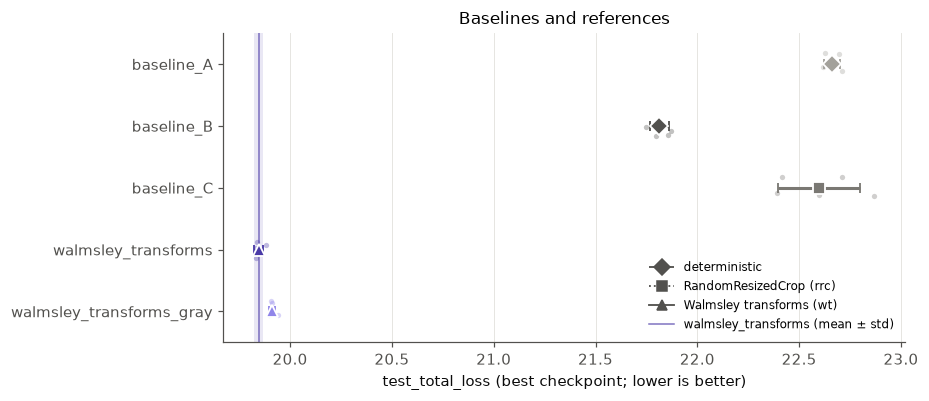

,modality,n_seeds,test_total_loss_mean,test_total_loss_std,mean_task_accuracy_mean,best_epoch_mean
experiment,,,,,,
baseline_A,deterministic,5,22.6612,0.0409,0.7520,13.8
baseline_B,deterministic,5,21.8136,0.0483,0.7606,15.0
baseline_C,rrc,5,22.5971,0.2016,0.7514,29.0
walmsley_transforms,wt,5,19.8463,0.0216,0.7807,88.2
walmsley_transforms_gray,wt,5,19.9115,0.0166,0.7806,93.6


In [9]:
MOD_HANDLES = {m: Line2D([], [], marker=MOD_MARKER[m], ls=MOD_LINESTYLE[m], color=INK2, mfc=INK2, ms=7, lw=1.2,
                         label=MODALITY_LABEL[m]) for m in ["deterministic"] + MODALITIES}


def dot_interval(ax, exps, *, col=None, ref=REFERENCE, anchors=(), xlabel=None):
    """Horizontal dot-and-interval: mean +- std per experiment, seeds as faint points."""
    col = col or LOSS
    exps = [e for e in exps if has(e)]
    rng = np.random.default_rng(0)
    if ref and has(ref):
        m, s = mean(ref, col), std(ref, col)
        ax.axvspan(m - s, m + s, color=REF_COLOR, alpha=0.12, lw=0)
        ax.axvline(m, color=REF_COLOR, lw=1, alpha=0.7, label=f"{ref} (mean ± std)")
    for a in anchors:
        if has(a) and a != ref:
            ax.axvline(mean(a, col), color=color_of(a), lw=1.2, ls="--", label=f"anchor: {a}")
    for i, e in enumerate(exps):
        v, c, mod = vals(e, col), color_of(e), META[e]["modality"]
        ax.scatter(v, i + rng.uniform(-0.18, 0.18, len(v)), s=12, color=c, alpha=0.35, lw=0, zorder=2)
        hollow = META[e]["family"].endswith("_photo")
        ax.errorbar(mean(e, col), i, xerr=std(e, col), fmt=MOD_MARKER.get(mod, "X"), color=c, ms=8, capsize=3,
                    mfc="white" if hollow else c, mec=c if hollow else "white", mew=1.2, elinewidth=2, zorder=3)
    ax.set_yticks(range(len(exps)), [label_of(e) for e in exps])
    ax.set_ylim(len(exps) - 0.5, -0.5)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel(xlabel or f"{col} (best checkpoint; lower is better)")
    return exps


ref_exps = [e for e in ["baseline_A", "baseline_B", "baseline_C", "baseline_rc",
                        "walmsley_transforms", "walmsley_transforms_gray"] if has(e)]
fig, ax = plt.subplots(figsize=(8, 0.45 * len(ref_exps) + 1.4))
dot_interval(ax, ref_exps)
mods = sorted({META[e]["modality"] for e in ref_exps}, key=(["deterministic"] + MODALITIES).index)
ax.legend(handles=[MOD_HANDLES[m] for m in mods] + ax.get_legend_handles_labels()[0][:1],
          loc="lower right", fontsize=8)
ax.set_title("Baselines and references")
save(fig, "B_baselines")
plt.show()
display(agg_df.loc[ref_exps, ["modality", "n_seeds", f"{LOSS}_mean", f"{LOSS}_std",
                              "mean_task_accuracy_mean", "best_epoch_mean"]].round(4))

**Deterministic crop vs resize.** `baseline_B` (center crop) beats `baseline_A` (resize to 224). Resizing downsamples the whole frame, while center crop keeps the native pixel scale, so fine structure (arms, bars, bulge profile) survives. The border it throws away is mostly sky.

**Crop-only anchor for `rrc`.** `baseline_C` (RandomResizedCrop, no policy) is the isolation control for the crop confound: it measures what RRC at scale 0.08–1 costs on its own (claim C9 below).

**Grayscale cost.** `walmsley_transforms_gray` is slightly worse than colour `walmsley_transforms`, so colour carries some task-relevant information here. Walmsley et al. grayscaled to avoid colour-driven shortcuts, not for accuracy (claim C6).

## C. Single-modality view (driven by `MODALITY`)

**View `rc`**: 18 experiments. Reference: `walmsley_transforms`. Modality anchor(s): none found yet.

note: the rc anchor `baseline_rc` (to_float -> random_crop, no policy) has not been run yet


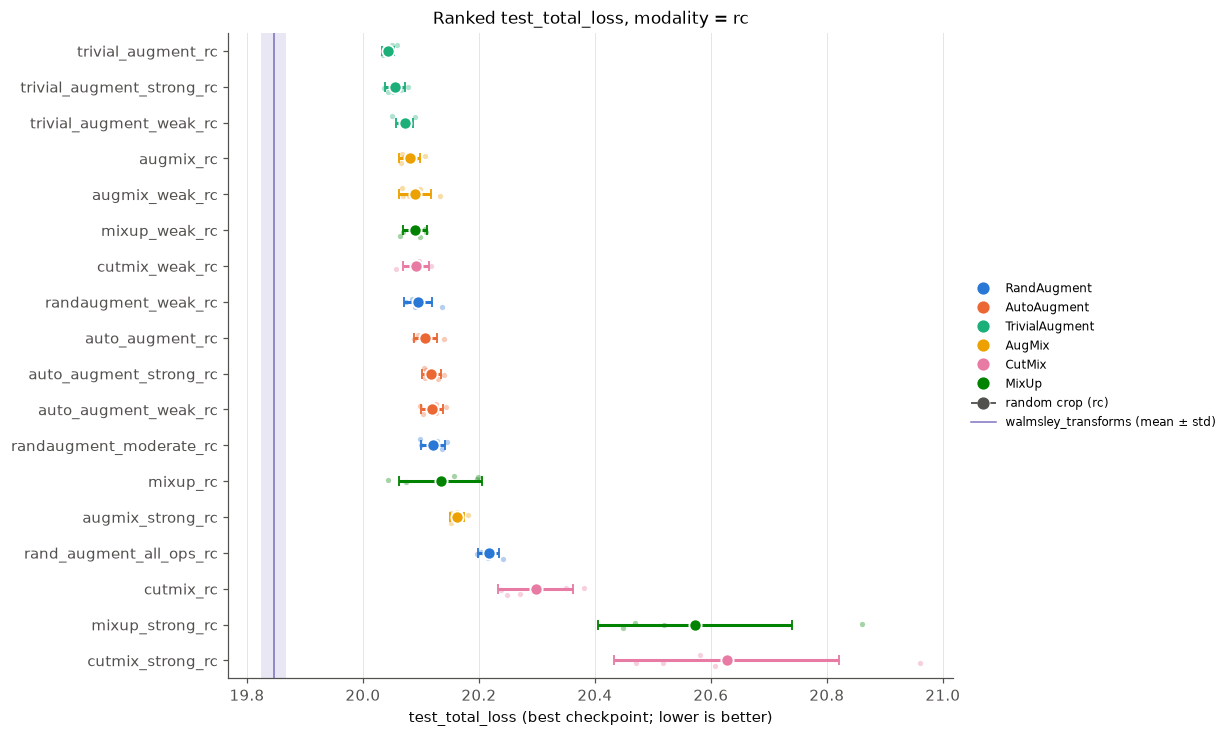

In [10]:
def in_view(exp, modality=MODALITY):
    mod = META[exp]["modality"]
    return mod in (["deterministic"] + MODALITIES if modality == "all" else [modality])


VIEW_EXPS = sorted([e for e in agg_df.index if in_view(e)], key=lambda e: mean(e))
VIEW_ANCHORS = [anchor_of(m) for m in (MODALITIES if MODALITY == "all" else [MODALITY]) if anchor_of(m)]
display(Markdown(f"**View `{MODALITY}`**: {len(VIEW_EXPS)} experiments. Reference: `{REFERENCE}`"
                 f"{'' if has(REFERENCE) else ' (MISSING)'}. Modality anchor(s): "
                 f"{', '.join(f'`{a}`' for a in VIEW_ANCHORS) or 'none found yet'}."))
if MODALITY in ("rc",) and not anchor_of("rc"):
    print("note: the rc anchor `baseline_rc` (to_float -> random_crop, no policy) has not been run yet")

fig, ax = plt.subplots(figsize=(8.5, 0.34 * len(VIEW_EXPS) + 1.5))
dot_interval(ax, VIEW_EXPS, anchors=VIEW_ANCHORS)
present_fams = [f for f in POLICY_FAMILIES + PHOTO_FAMILIES if any(META[e]["family"] == f for e in VIEW_EXPS)]
fam_handles = [Line2D([], [], marker="o", ls="", color=FAMILY_COLORS[f], ms=7, label=FAMILY_LABEL[f],
                      mfc="white" if f.endswith("_photo") else FAMILY_COLORS[f]) for f in present_fams]
view_mods = sorted({META[e]["modality"] for e in VIEW_EXPS}, key=(["deterministic"] + MODALITIES + ["unknown"]).index)
ax.legend(handles=fam_handles + [MOD_HANDLES[m] for m in view_mods if m in MOD_HANDLES] +
          ax.get_legend_handles_labels()[0], fontsize=8, loc="center left", bbox_to_anchor=(1.01, 0.5))
ax.set_title(f"Ranked {LOSS}, modality = {MODALITY}")
save(fig, "C_ranked_total_loss")
plt.show()

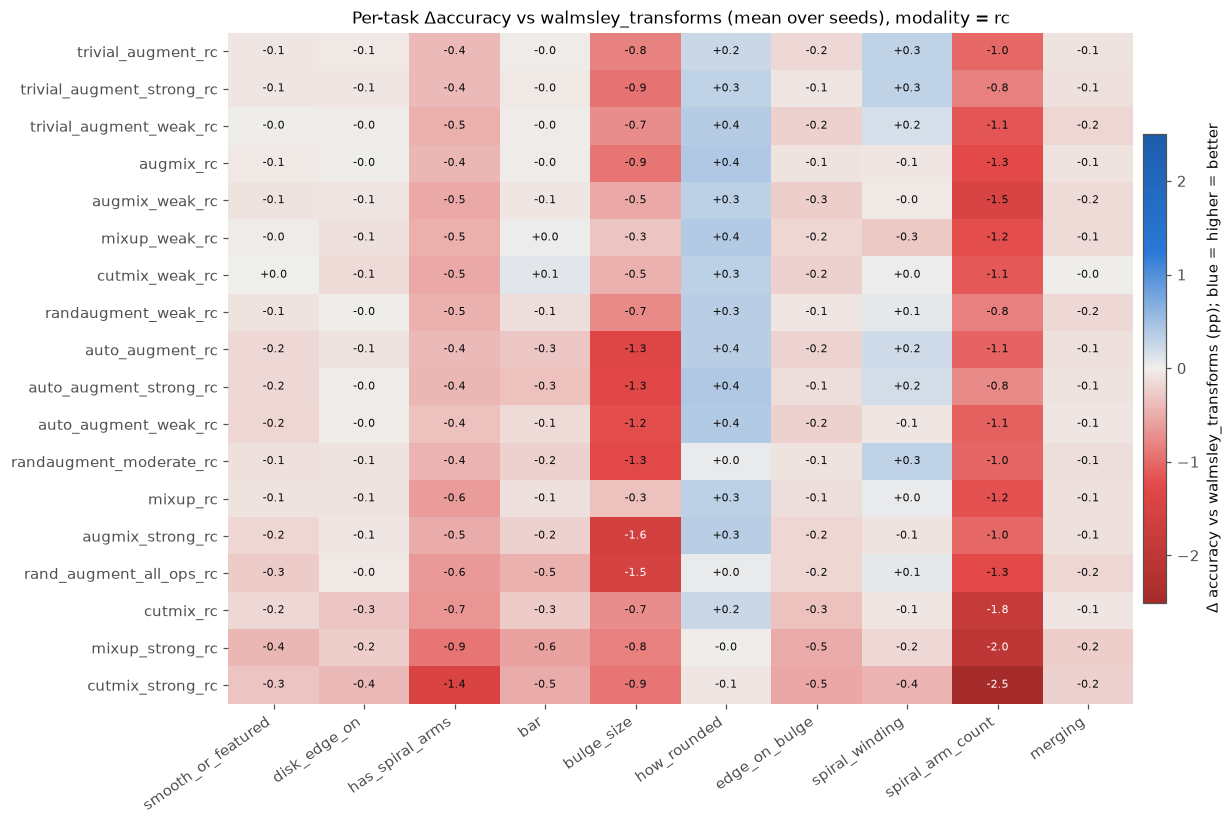

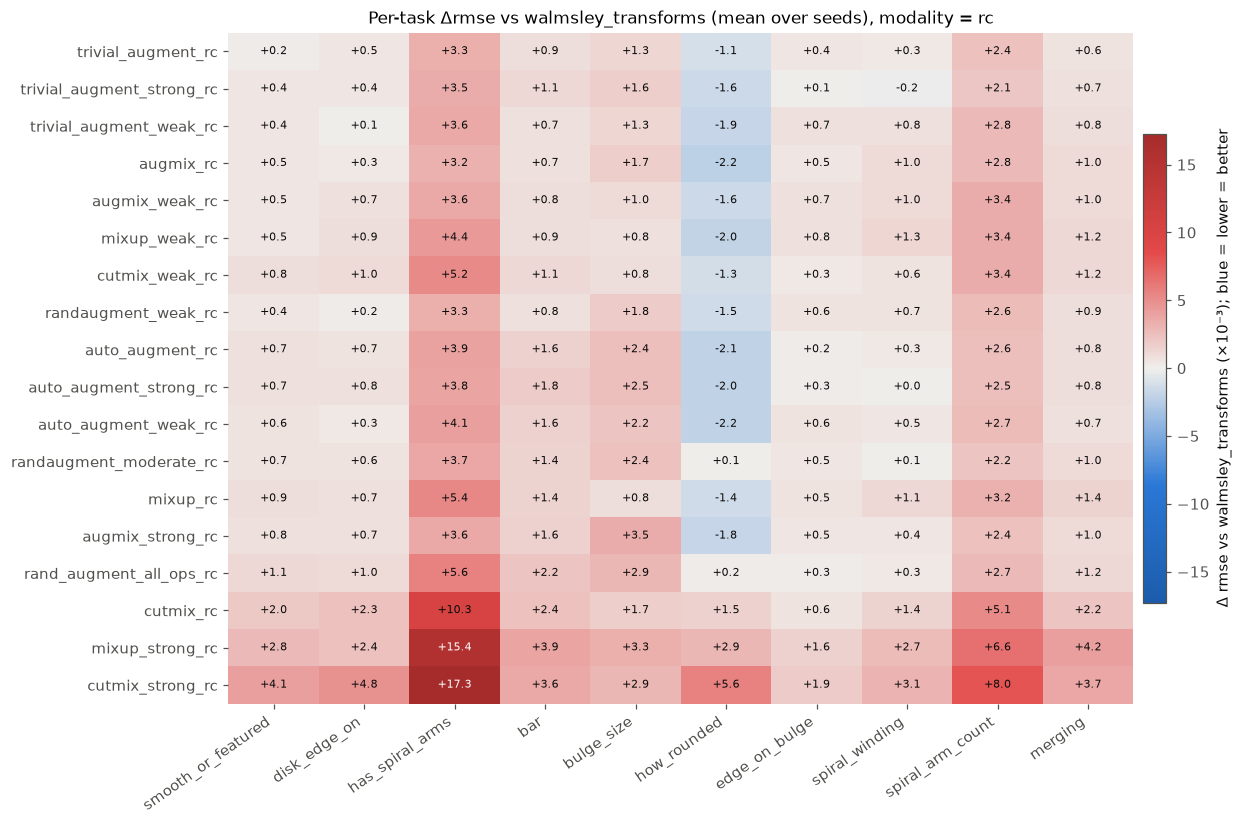

In [11]:
def delta_heatmap(exps, kind="accuracy", ref=REFERENCE, name=None):
    """Rows = experiments, columns = tasks; cell = mean metric - reference mean metric. Blue = better than ref."""
    if not has(ref):
        print(f"reference {ref!r} missing; heatmap skipped")
        return None
    exps = [e for e in exps if e != ref]
    cols = [f"{EVAL_SPLIT}_{t}_{kind}_mean" for t in TASKS]
    D = agg_df.loc[exps, cols].to_numpy() - agg_df.loc[ref, cols].to_numpy()
    scale, unit = (100, "pp") if kind == "accuracy" else (1000, "×10⁻³")
    D = D * scale
    vmax = float(np.nanmax(np.abs(D))) or 1.0
    cmap = DIVERGING if kind == "accuracy" else DIVERGING.reversed()     # lower RMSE is better -> blue
    fig, ax = plt.subplots(figsize=(11, 0.34 * len(exps) + 1.8))
    im = ax.imshow(D, cmap=cmap, norm=TwoSlopeNorm(0, -vmax, vmax), aspect="auto")
    for i in range(D.shape[0]):
        for j in range(D.shape[1]):
            ax.text(j, i, f"{D[i, j]:+.1f}", ha="center", va="center", fontsize=7,
                    color="white" if abs(D[i, j]) > 0.6 * vmax else INK)
    ax.set_xticks(range(len(TASKS)), TASKS, rotation=35, ha="right")
    ax.set_yticks(range(len(exps)), [label_of(e) for e in exps])
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    better = "higher" if kind == "accuracy" else "lower"
    fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01,
                 label=f"Δ {kind} vs {ref} ({unit}); blue = {better} = better")
    ax.set_title(f"Per-task Δ{kind} vs {ref} (mean over seeds), modality = {MODALITY}")
    if name:
        save(fig, name)
    plt.show()
    return pd.DataFrame(D, index=exps, columns=TASKS)


heat_exps = [e for e in VIEW_EXPS if e != REFERENCE]
delta_acc_df = delta_heatmap(heat_exps, "accuracy", name="C_delta_accuracy_heatmap")
delta_rmse_df = delta_heatmap(heat_exps, "rmse", name="C_delta_rmse_heatmap")

## D. Strength / dose-response (for the selected modality)

One line per family across weak → moderate → strong. The shaded band is `REFERENCE` (mean ± std). With `MODALITY = "all"`, one panel is drawn per modality that has a grid. Only `rc` has the full grid so far.

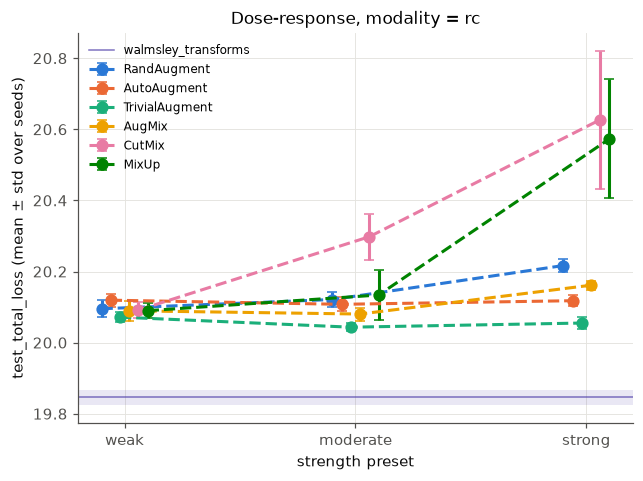

,modality,family,weak,moderate,strong,strong_minus_weak,se,welch_p,moderate_minus_weak,best_strength
0,rc,randaugment,20.0953,20.1213,20.2168,0.1215,0.0134,0.0000,0.0260,weak
1,rc,autoaugment,20.1194,20.1078,20.1179,-0.0015,0.0109,0.8933,-0.0116,moderate
2,rc,trivialaugment,20.0717,20.0434,20.0551,-0.0166,0.0099,0.1310,-0.0283,moderate
3,rc,augmix,20.0896,20.0804,20.1614,0.0718,0.0134,0.0023,-0.0092,moderate
4,rc,cutmix,20.0918,20.2979,20.6271,0.5353,0.0873,0.0033,0.2061,weak
5,rc,mixup,20.0899,20.1339,20.5730,0.4832,0.0755,0.0027,0.0440,weak


In [12]:
def strength_rows(modality):
    rows = []
    for f in POLICY_FAMILIES + PHOTO_FAMILIES:
        pts = {s: find(f, s, modality) for s in STRENGTHS}
        pts = {s: e for s, e in pts.items() if e}
        if len(pts) >= 2:
            rows.append((f, pts))
    return rows


d_modalities = MODALITIES if MODALITY == "all" else [MODALITY]
grids = {m: strength_rows(m) for m in d_modalities}
grids = {m: r for m, r in grids.items() if r}
slope_rows = []
if not grids:
    print(f"no strength grid (>=2 strengths of one family) in modality {MODALITY!r} yet")
else:
    fig, axes = plt.subplots(1, len(grids), figsize=(6.5 * len(grids), 4.6), squeeze=False, sharey=True)
    for ax, (mod, rows) in zip(axes[0], grids.items()):
        if has(REFERENCE):
            m, s = mean(REFERENCE), std(REFERENCE)
            ax.axhspan(m - s, m + s, color=REF_COLOR, alpha=0.12, lw=0)
            ax.axhline(m, color=REF_COLOR, lw=1, alpha=0.7, label=f"{REFERENCE}")
        if anchor_of(mod) and anchor_of(mod) != REFERENCE:
            ax.axhline(mean(anchor_of(mod)), color=color_of(anchor_of(mod)), ls="--", lw=1.2,
                       label=f"anchor: {anchor_of(mod)}")
        for k, (f, pts) in enumerate(rows):
            xs = np.array([STRENGTHS.index(s) for s in pts]) + (k - (len(rows) - 1) / 2) * 0.04
            ys = [mean(e) for e in pts.values()]
            es = [std(e) for e in pts.values()]
            c = FAMILY_COLORS[f]
            ax.errorbar(xs, ys, yerr=es, color=c, ls=MOD_LINESTYLE[mod], marker=MOD_MARKER[mod], ms=7, capsize=3,
                        mfc="white" if f.endswith("_photo") else c, mec=c, label=FAMILY_LABEL[f])
        ax.set_xticks(range(3), STRENGTHS)
        ax.set_xlim(-0.2, 2.2)
        ax.set_title(f"Dose-response, modality = {mod}")
        ax.set_xlabel("strength preset")
        ax.legend(fontsize=8, loc="upper left")
        for f, pts in rows:
            a, b = pts.get("weak"), pts.get("strong")
            r = {"modality": mod, "family": f, **{s: mean(pts[s]) if s in pts else np.nan for s in STRENGTHS}}
            if a and b:
                r |= {"strong_minus_weak": mean(b) - mean(a),
                      "se": math.sqrt(std(a) ** 2 / len(vals(a)) + std(b) ** 2 / len(vals(b))),
                      "welch_p": welch(vals(b), vals(a))["p"]}
            if pts.get("moderate") and a:
                r["moderate_minus_weak"] = mean(pts["moderate"]) - mean(a)
            r["best_strength"] = min(pts, key=lambda s: mean(pts[s]))
            slope_rows.append(r)
    axes[0][0].set_ylabel(f"{LOSS} (mean ± std over seeds)")
    save(fig, "D_strength_dose_response")
    plt.show()
slopes_df = pd.DataFrame(slope_rows)
if len(slopes_df):
    display(slopes_df.round(4))

## E. Cross-modality comparison (always all modalities)

All comparisons in this section use each family's **default strength** (the preset with no strength suffix; `rand_augment_all_ops` counts as the RandAugment default).

**Default-strength test_total_loss, family × modality**

,RandomResizedCrop (rrc),random crop (rc),Walmsley transforms (wt)
RandAugment,23.303 ± 0.202 (n=5),20.217 ± 0.018 (n=5),20.222 ± 0.015 (n=5)
AutoAugment,23.281 ± 0.118 (n=5),20.108 ± 0.020 (n=5),20.024 ± 0.010 (n=5)
TrivialAugment,22.880 ± 0.128 (n=5),20.043 ± 0.011 (n=5),19.927 ± 0.016 (n=5)
AugMix,23.017 ± 0.165 (n=5),20.080 ± 0.018 (n=5),19.876 ± 0.007 (n=5)
CutMix,22.790 ± 0.110 (n=5),20.298 ± 0.064 (n=5),20.295 ± 0.260 (n=5)
MixUp,22.721 ± 0.160 (n=5),20.134 ± 0.071 (n=5),19.923 ± 0.032 (n=5)


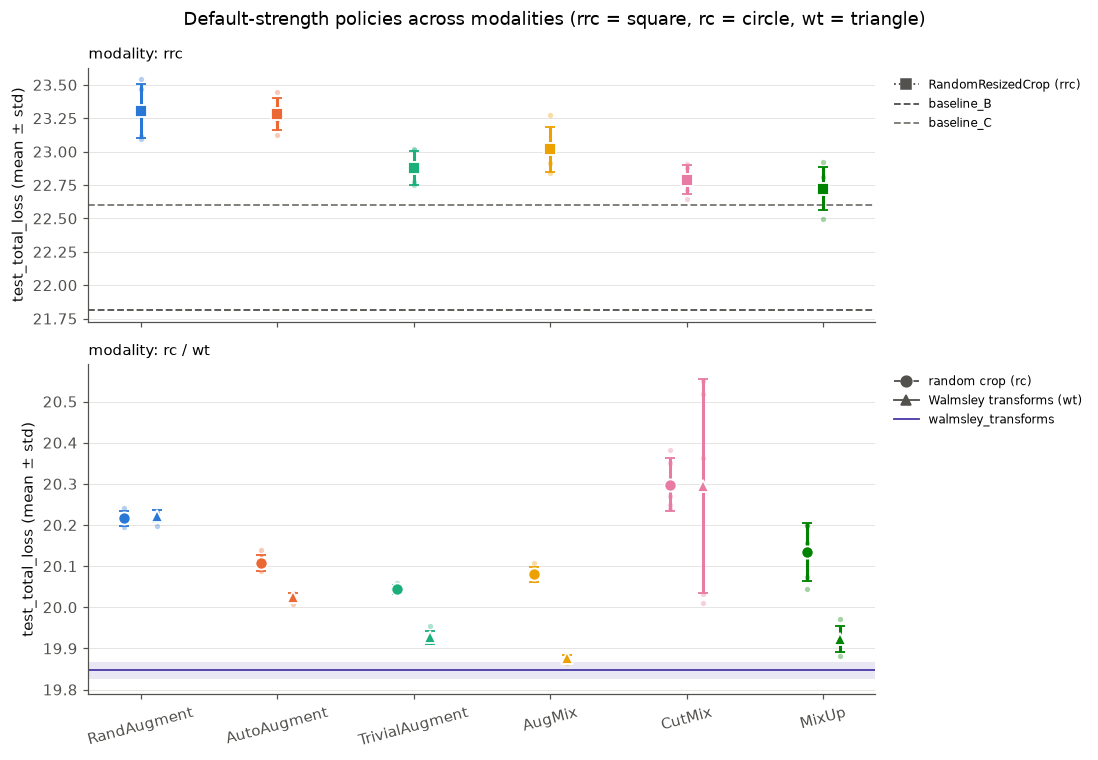

In [13]:
default_exp = {(f, m): find(f, DEFAULT_STRENGTH[f], m) for f in POLICY_FAMILIES + PHOTO_FAMILIES for m in MODALITIES}
fams_present = [f for f in POLICY_FAMILIES + PHOTO_FAMILIES if any(default_exp[(f, m)] for m in MODALITIES)]

pivot = pd.DataFrame({MODALITY_LABEL[m]: {FAMILY_LABEL[f]: (f"{mean(e):.3f} ± {std(e):.3f} (n={len(vals(e))})"
                                                            if (e := default_exp[(f, m)]) else "—")
                                          for f in fams_present} for m in MODALITIES})
display(Markdown(f"**Default-strength {LOSS}, family × modality**"))
display(pivot)

# rrc sits ~3 loss points above rc/wt, so it gets its own panel (same x, independent y ranges)
offs = {"rrc": 0.0, "rc": -0.12, "wt": 0.12}
panels = [("rrc", ["rrc"], ["baseline_B", anchor_of("rrc")]), ("rc / wt", ["rc", "wt"], [REFERENCE])]
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True, gridspec_kw={"height_ratios": [1, 1.3]})
for ax, (title, mods, refs) in zip(axes, panels):
    for ref in refs:
        if has(ref):
            if ref == REFERENCE:
                ax.axhspan(mean(ref) - std(ref), mean(ref) + std(ref), color=REF_COLOR, alpha=0.12, lw=0)
            ax.axhline(mean(ref), color=color_of(ref), ls="-" if ref == REFERENCE else "--", lw=1.2, label=ref)
    for i, f in enumerate(fams_present):
        for m in mods:
            e = default_exp[(f, m)]
            if not e:
                continue
            c = FAMILY_COLORS[f]
            ax.scatter(np.full(len(vals(e)), i + offs[m]), vals(e), s=12, color=c, alpha=0.35, lw=0)
            ax.errorbar(i + offs[m], mean(e), yerr=std(e), fmt=MOD_MARKER[m], color=c, ms=8, capsize=3,
                        mfc="white" if f.endswith("_photo") else c, mec=c if f.endswith("_photo") else "white",
                        mew=1.2)
    ax.grid(axis="x", visible=False)
    ax.set_ylabel(f"{LOSS} (mean ± std)")
    ax.set_title(f"modality: {title}", loc="left", fontsize=10)
    ax.legend(handles=[MOD_HANDLES[m] for m in mods] + ax.get_legend_handles_labels()[0], fontsize=8,
              loc="upper left", bbox_to_anchor=(1.01, 1))
axes[-1].set_xticks(range(len(fams_present)), [FAMILY_LABEL[f] for f in fams_present], rotation=15)
fig.suptitle("Default-strength policies across modalities (rrc = square, rc = circle, wt = triangle)")
fig.tight_layout()
save(fig, "E_family_by_modality")
plt.show()

In [14]:
def modality_effects(m_from, m_to):
    rows = []
    for f in fams_present:
        a, b = default_exp[(f, m_to)], default_exp[(f, m_from)]
        if a and b:
            rows.append({"family": f} | effect_row(a, b))
    df = pd.DataFrame(rows)
    if len(df):
        df["p_holm"] = holm(df["p"])
    return df


EFFECTS = {}
for m_from, m_to, what in [("rrc", "rc", "crop confound: RandomResizedCrop -> fixed-size random crop"),
                           ("rc", "wt", "adding flips + rotation under the policy (rc -> wt)")]:
    EFFECTS[(m_from, m_to)] = modality_effects(m_from, m_to)
    display(Markdown(f"**Δ({m_from} → {m_to}) per family**: {what}. Negative = lower loss in `{m_to}`."))
    display(EFFECTS[(m_from, m_to)].round(4) if len(EFFECTS[(m_from, m_to)]) else "no pairs available")

# crop-only effect with the anchors, when available
for m_from, m_to in [("rrc", "rc"), ("deterministic", "rrc")]:
    a, b = anchor_of(m_to), anchor_of(m_from)
    if a and b:
        r = effect_row(a, b)
        print(f"anchor effect {b} -> {a}: Δ = {r['delta']:+.4f} (95% CI {r['ci95_lo']:+.4f}..{r['ci95_hi']:+.4f}, "
              f"Welch p = {r['p']:.2g})")

**Δ(rrc → rc) per family**: crop confound: RandomResizedCrop -> fixed-size random crop. Negative = lower loss in `rc`.

,family,from,to,delta,se,welch_t,welch_df,p,ci95_lo,ci95_hi,p_holm
0,randaugment,rand_augment_all_ops,rand_augment_all_ops_rc,-3.0864,0.0906,-34.0612,4.0644,0.0,-3.2475,-2.9283,0.0
1,autoaugment,auto_augment,auto_augment_rc,-3.1733,0.0535,-59.3524,4.2341,0.0,-3.2667,-3.0813,0.0
2,trivialaugment,trivial_augment,trivial_augment_rc,-2.8365,0.0576,-49.2570,4.0548,0.0,-2.9374,-2.7359,0.0
3,augmix,augmix,augmix_rc,-2.9363,0.0744,-39.4460,4.0966,0.0,-3.0769,-2.8161,0.0
4,cutmix,cutmix,cutmix_rc,-2.4924,0.0569,-43.8370,6.4618,0.0,-2.5883,-2.3896,0.0
5,mixup,mixup,mixup_rc,-2.5873,0.0785,-32.9630,5.5164,0.0,-2.7216,-2.4462,0.0


**Δ(rc → wt) per family**: adding flips + rotation under the policy (rc -> wt). Negative = lower loss in `wt`.

,family,from,to,delta,se,welch_t,welch_df,p,ci95_lo,ci95_hi,p_holm
0,randaugment,rand_augment_all_ops_rc,rand_augment_all_ops_wt,0.0056,0.0105,0.5324,7.7276,0.6094,-0.0135,0.0231,1.0000
1,autoaugment,auto_augment_rc,auto_augment_wt,-0.0835,0.0101,-8.2626,5.9168,0.0002,-0.1025,-0.0674,0.0007
2,trivialaugment,trivial_augment_rc,trivial_augment_wt,-0.1163,0.0087,-13.3769,6.8812,0.0000,-0.1303,-0.1005,0.0000
3,augmix,augmix_rc,augmix_wt,-0.2042,0.0087,-23.5041,5.1099,0.0000,-0.2205,-0.1899,0.0000
4,cutmix,cutmix_rc,cutmix_wt,-0.0034,0.1197,-0.0280,4.4890,0.9788,-0.2157,0.2001,1.0000
5,mixup,mixup_rc,mixup_wt,-0.2113,0.0349,-6.0550,5.5499,0.0012,-0.2687,-0.1487,0.0037


anchor effect baseline_B -> baseline_C: Δ = +0.7835 (95% CI +0.6286..+0.9483, Welch p = 0.00066)


,P(geometric op per image)
randaugment,0.604
randaugment_photo,0.000
autoaugment,0.164
autoaugment_photo,0.000
trivialaugment,0.357
trivialaugment_photo,0.000
augmix,0.000
cutmix,0.000
mixup,0.000


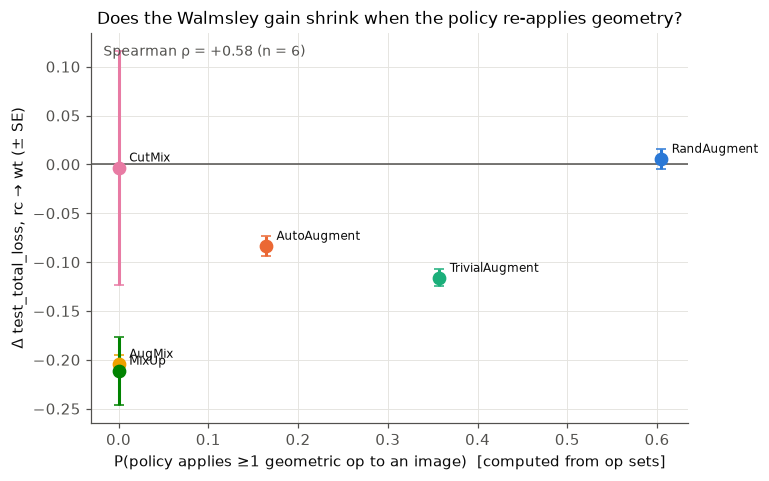

,family,exposure,delta,se,p,p_holm
0,randaugment,0.6044,0.0056,0.0105,0.6094,1.0000
1,autoaugment,0.1640,-0.0835,0.0101,0.0002,0.0007
2,trivialaugment,0.3571,-0.1163,0.0087,0.0000,0.0000
3,augmix,0.0000,-0.2042,0.0087,0.0000,0.0000
4,cutmix,0.0000,-0.0034,0.1197,0.9788,1.0000
5,mixup,0.0000,-0.2113,0.0349,0.0012,0.0037


In [15]:
# ---- geometric-op exposure, computed from the op sets in the optastra source
def geometric_exposure():
    """P(at least one geometric op is applied to an image) per family, from the registered configs."""
    try:
        from optastra.transforms.ops import GEOMETRIC_OPS, ALL_OP_NAMES, PHOTOMETRIC_OP_NAMES
        from optastra.transforms.randaugment import RandAugmentConfig
        from optastra.transforms.trivialaugment import TrivialAugmentConfig
        from optastra.transforms.augmix import AugMixConfig
        from optastra.transforms.autoaugment import AutoAugmentConfig
    except ImportError as err:
        warnings.warn(f"cannot import optastra transforms ({err}); geometric exposure unavailable")
        return {}
    geo = set(GEOMETRIC_OPS)

    def randaugment(ops, n):     # n distinct ops drawn uniformly from `ops`
        k = sum(o in geo for o in ops)
        return 1 - math.comb(len(ops) - k, n) / math.comb(len(ops), n)

    def trivial(ops):            # one op drawn uniformly
        return sum(o in geo for o in ops) / len(ops)

    def autoaugment(policy):     # one sub-policy drawn uniformly, each op applied with its own probability
        return float(np.mean([1 - np.prod([1 - p for op, p, _ in sp if op in geo]) for sp in policy]))

    augmix_ops = AugMixConfig().ops
    if any(o in geo for o in augmix_ops):
        warnings.warn("AugMix op set contains geometric ops; its exposure formula here assumes none")
    photo_policy = [[(op, p, m) for op, p, m in sp if op not in geo] for sp in AutoAugmentConfig().policy]
    return {
        "randaugment": randaugment(ALL_OP_NAMES, RandAugmentConfig().num_ops),
        "randaugment_photo": randaugment(PHOTOMETRIC_OP_NAMES, RandAugmentConfig().num_ops),
        "autoaugment": autoaugment(AutoAugmentConfig().policy),
        "autoaugment_photo": autoaugment(photo_policy),
        "trivialaugment": trivial(TrivialAugmentConfig().ops),
        "trivialaugment_photo": trivial(PHOTOMETRIC_OP_NAMES),
        "augmix": 0.0 if not any(o in geo for o in augmix_ops) else np.nan,
        "cutmix": 0.0,           # batch transform: pastes patches, no geometric warp
        "mixup": 0.0,            # batch transform: pixel blend
    }


EXPOSURE = geometric_exposure()
display(pd.Series(EXPOSURE, name="P(geometric op per image)").round(3).to_frame())

rw = EFFECTS[("rc", "wt")]
if len(rw) and EXPOSURE:
    rw = rw.assign(exposure=rw["family"].map(EXPOSURE))
    fig, ax = plt.subplots(figsize=(7, 4.6))
    ax.axhline(0, color=INK2, lw=1)
    for _, r in rw.iterrows():
        c = FAMILY_COLORS[r["family"]]
        ax.errorbar(r["exposure"], r["delta"], yerr=r["se"], fmt="o", color=c, ms=8, capsize=3,
                    mfc="white" if r["family"].endswith("_photo") else c, mec=c)
        ax.annotate(FAMILY_LABEL[r["family"]], (r["exposure"], r["delta"]), xytext=(7, 4),
                    textcoords="offset points", fontsize=8, color=INK)
    ax.set_xlabel("P(policy applies ≥1 geometric op to an image)  [computed from op sets]")
    ax.set_ylabel(f"Δ {LOSS}, rc → wt (± SE)")
    ax.set_title("Does the Walmsley gain shrink when the policy re-applies geometry?")
    if len(rw) >= 3:
        rho = rw["exposure"].rank().corr(rw["delta"].rank())
        ax.text(0.02, 0.97, f"Spearman ρ = {rho:+.2f} (n = {len(rw)})", transform=ax.transAxes, va="top",
                fontsize=9, color=INK2)
    save(fig, "E_wt_gain_vs_geometric_exposure")
    plt.show()
    display(rw[["family", "exposure", "delta", "se", "p", "p_holm"]].round(4))

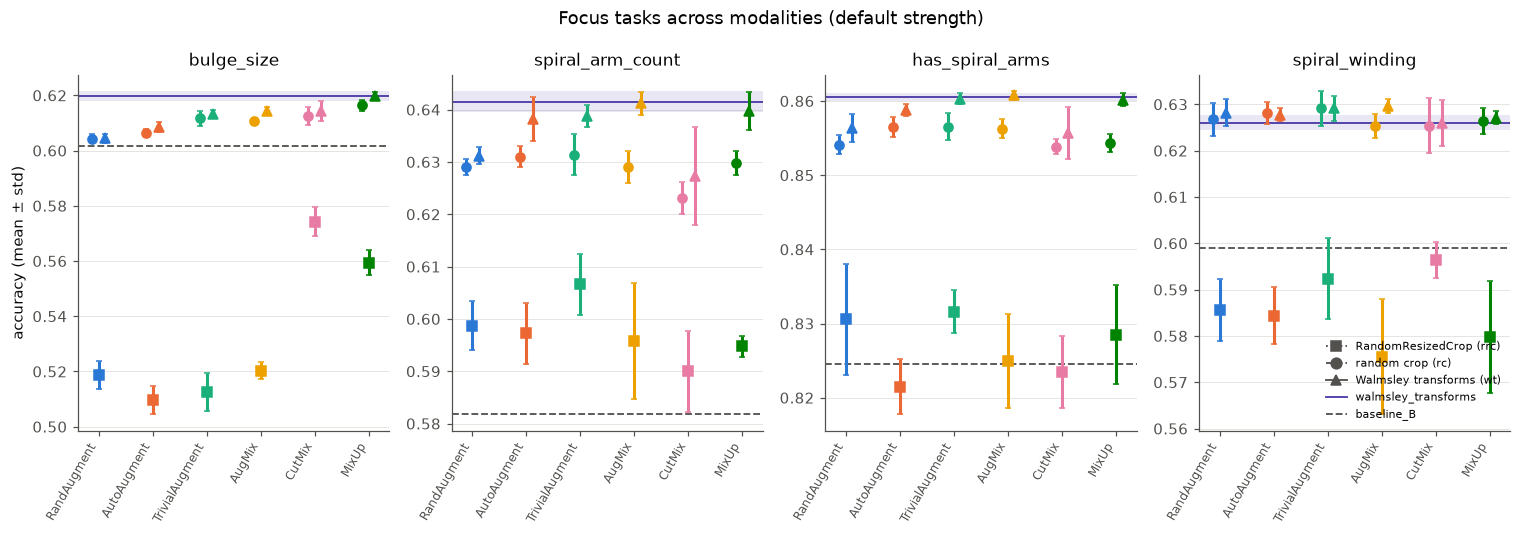

In [16]:
# ---- per-task focus across modalities (default strength) + references
FOCUS_TASKS = ["bulge_size", "spiral_arm_count", "has_spiral_arms", "spiral_winding"]
fig, axes = plt.subplots(1, len(FOCUS_TASKS), figsize=(4.2 * len(FOCUS_TASKS), 4.2), sharex=True)
for ax, t in zip(axes, FOCUS_TASKS):
    col = f"{EVAL_SPLIT}_{t}_accuracy"
    for ref, ls in [(REFERENCE, "-"), ("baseline_B", "--")]:
        if has(ref):
            if ref == REFERENCE:
                ax.axhspan(mean(ref, col) - std(ref, col), mean(ref, col) + std(ref, col), color=REF_COLOR,
                           alpha=0.12, lw=0)
            ax.axhline(mean(ref, col), color=color_of(ref), ls=ls, lw=1.2, label=ref)
    for i, f in enumerate(fams_present):
        for m in MODALITIES:
            if (e := default_exp[(f, m)]):
                c = FAMILY_COLORS[f]
                ax.errorbar(i + offs[m], mean(e, col), yerr=std(e, col), fmt=MOD_MARKER[m], color=c, ms=6,
                            capsize=2, mfc="white" if f.endswith("_photo") else c, mec=c)
    ax.set_xticks(range(len(fams_present)), [FAMILY_LABEL[f] for f in fams_present], rotation=60, ha="right",
                  fontsize=8)
    ax.grid(axis="x", visible=False)
    ax.set_title(t)
axes[0].set_ylabel("accuracy (mean ± std)")
axes[-1].legend(handles=[MOD_HANDLES[m] for m in MODALITIES] + axes[-1].get_legend_handles_labels()[0],
                fontsize=7, loc="lower right")
fig.suptitle("Focus tasks across modalities (default strength)", y=1.02)
save(fig, "E_focus_tasks")
plt.show()

## F. Training dynamics and stability

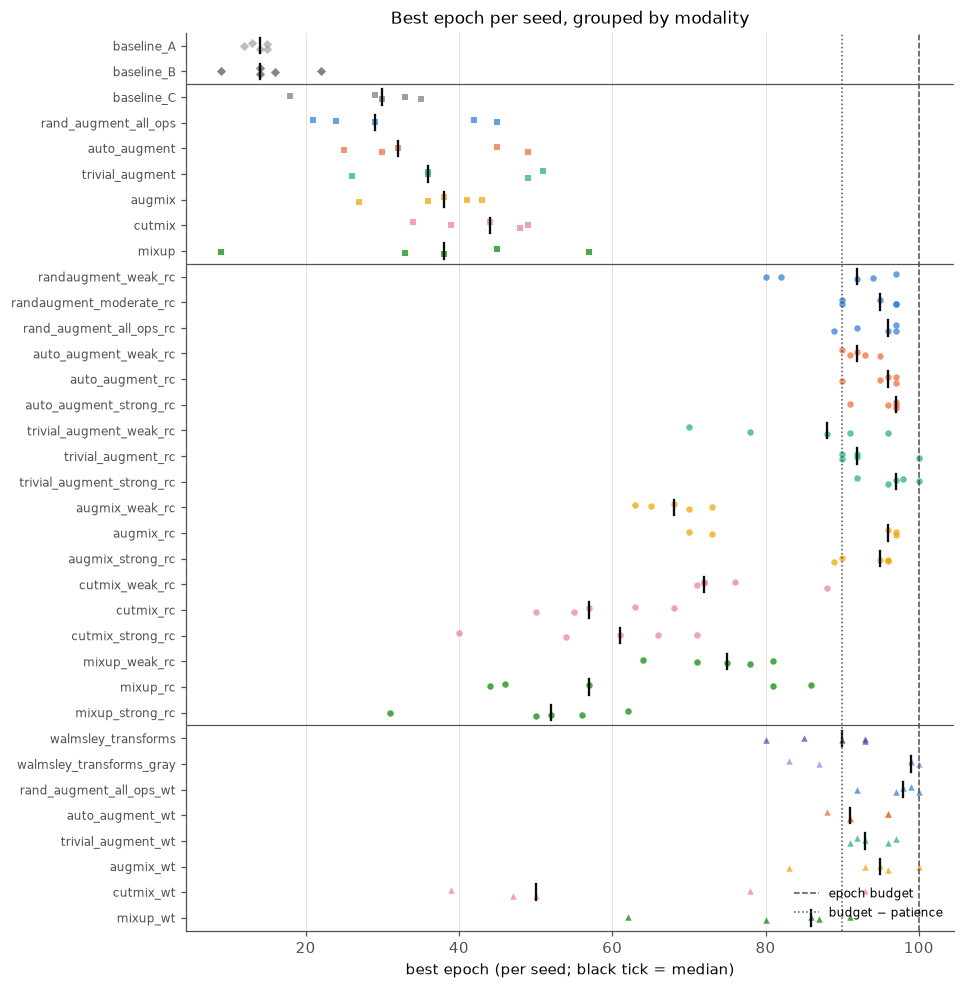

runs whose best epoch is within the last 10 epochs of the budget: 64 -> ['augmix_rc', 'augmix_strong_rc', 'augmix_wt', 'auto_augment_rc', 'auto_augment_strong_rc', 'auto_augment_weak_rc', 'auto_augment_wt', 'cutmix_wt', 'mixup_wt', 'rand_augment_all_ops_rc', 'rand_augment_all_ops_wt', 'randaugment_moderate_rc', 'randaugment_weak_rc', 'trivial_augment_rc', 'trivial_augment_strong_rc', 'trivial_augment_weak_rc', 'trivial_augment_wt', 'walmsley_transforms', 'walmsley_transforms_gray']


In [17]:
order = sorted(agg_df.index, key=lambda e: (mod_order(e), fam_order(e), strength_order(e), e))
fig, ax = plt.subplots(figsize=(9, 0.26 * len(order) + 1.5))
rng = np.random.default_rng(1)
for i, e in enumerate(order):
    be = per_run_df.loc[per_run_df["experiment"] == e, "best_epoch"].to_numpy()
    ax.scatter(be, i + rng.uniform(-0.15, 0.15, len(be)), s=18, color=color_of(e), alpha=0.7,
               marker=MOD_MARKER.get(META[e]["modality"], "X"), lw=0)
    ax.plot([np.median(be)] * 2, [i - 0.3, i + 0.3], color=INK, lw=1.5)
prev = None
for i, e in enumerate(order):
    if prev is not None and META[e]["modality"] != META[prev]["modality"]:
        ax.axhline(i - 0.5, color=INK2, lw=0.8)
    prev = e
ax.axvline(MAX_ITER / ITERS_PER_EPOCH, color=INK2, ls="--", lw=1, label="epoch budget")
ax.axvline(MAX_ITER / ITERS_PER_EPOCH - PATIENCE_EPOCHS, color=INK2, ls=":", lw=1, label="budget − patience")
ax.set_yticks(range(len(order)), [label_of(e) for e in order], fontsize=8)
ax.set_ylim(len(order) - 0.5, -0.5)
ax.grid(axis="y", visible=False)
ax.set_xlabel("best epoch (per seed; black tick = median)")
ax.legend(fontsize=8, loc="lower right")
ax.set_title("Best epoch per seed, grouped by modality")
save(fig, "F_best_epoch")
plt.show()
late = per_run_df[per_run_df["best_epoch"] > MAX_ITER / ITERS_PER_EPOCH - PATIENCE_EPOCHS]
print(f"runs whose best epoch is within the last {PATIENCE_EPOCHS} epochs of the budget: {len(late)}"
      + (f" -> {sorted(set(late['experiment']))}" if len(late) else ""))

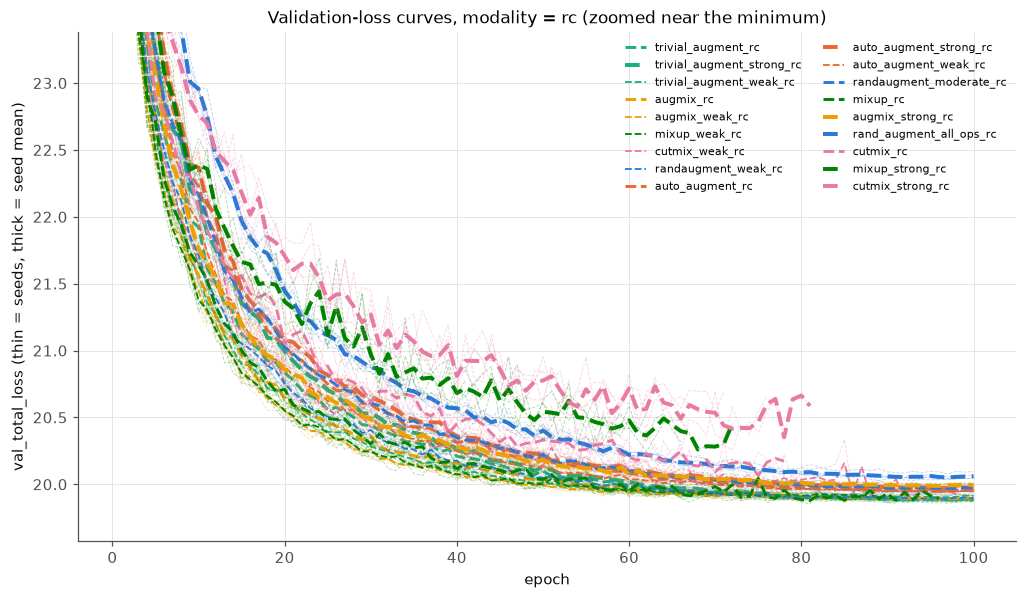

In [18]:
curve_exps = [e for e in VIEW_EXPS if CURVE_FAMILIES is None or META[e]["family"] in CURVE_FAMILIES
              or color_key(META[e]) in CURVE_FAMILIES]
fig, ax = plt.subplots(figsize=(11, 6))
lo = np.inf
for e in curve_exps:
    seeds = [s for s in EXPECTED_SEEDS if (e, s) in curves] if STRICT_SEEDS else \
        sorted({s for (x, s) in curves if x == e}, key=int)
    c, ls = color_of(e), MOD_LINESTYLE.get(META[e]["modality"], "-")
    lw = {"weak": 1.2, "moderate": 1.9, "strong": 2.6}.get(META[e]["strength"], 1.9)
    for s in seeds:
        d = curves[(e, s)]
        ax.plot(d["iter"] / ITERS_PER_EPOCH, d["val_total_loss"], color=c, ls=ls, lw=0.6, alpha=0.3)
    mean_curve = pd.concat([curves[(e, s)].set_index("iter")["val_total_loss"] for s in seeds], axis=1).mean(axis=1)
    ax.plot(mean_curve.index / ITERS_PER_EPOCH, mean_curve.values, color=c, ls=ls, lw=lw, label=e)
    lo = min(lo, mean_curve.min())
ax.set_ylim(lo - 0.3, lo + 3.5)
ax.set_xlabel("epoch")
ax.set_ylabel("val_total_loss (thin = seeds, thick = seed mean)")
ax.set_title(f"Validation-loss curves, modality = {MODALITY}"
             + (f", families = {CURVE_FAMILIES}" if CURVE_FAMILIES else "") + " (zoomed near the minimum)")
ax.legend(fontsize=7, ncol=2, loc="upper right")
save(fig, "F_val_loss_curves")
plt.show()

**Median seed std of test_total_loss per modality**

,median std
modality,
deterministic,0.0446
rc,0.0204
rrc,0.1604
wt,0.0165


flagged (std > 3x modality median): ['cutmix_wt', 'cutmix_strong_rc', 'mixup_strong_rc', 'mixup_rc', 'cutmix_rc']
for comparison, std > 3x global median (0.0669): ['cutmix_wt', 'rand_augment_all_ops', 'baseline_C', 'cutmix_strong_rc', 'mixup_strong_rc', 'augmix', 'mixup', 'trivial_augment', 'auto_augment', 'cutmix', 'mixup_rc']


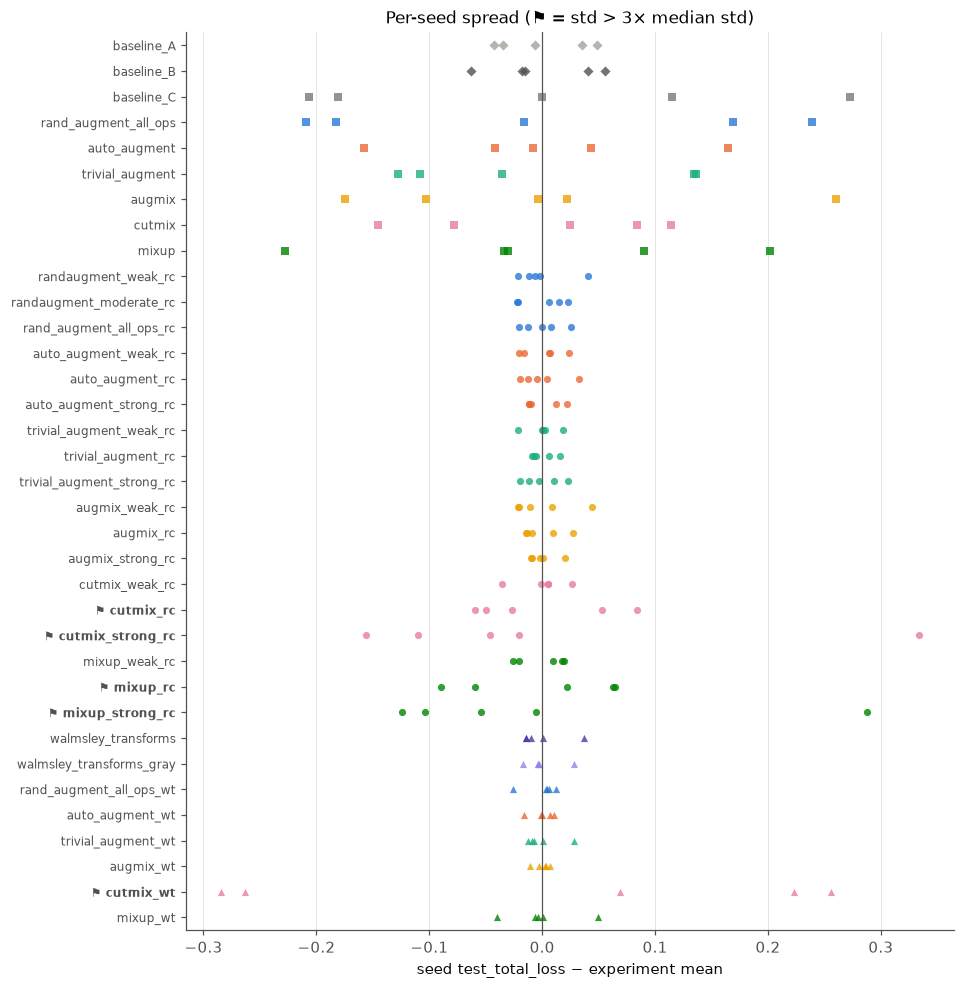

**Per-seed test_total_loss of flagged experiments** (one bad seed, or bimodal?)

seed,42,123,456,789,101112,std
experiment,,,,,,
cutmix_wt,20.5501,20.0103,20.5176,20.3632,20.0314,0.2597
cutmix_strong_rc,20.6064,20.5168,20.5808,20.4707,20.9607,0.1939
mixup_strong_rc,20.5185,20.8611,20.5675,20.4689,20.4492,0.1675
mixup_rc,20.1562,20.1988,20.0743,20.1964,20.0439,0.0712
cutmix_rc,20.2479,20.2382,20.2710,20.3815,20.3507,0.0643


In [19]:
# ---- seed-level stability: flag experiments whose std is > 3x the median std
# rrc runs are uniformly noisier than rc/wt runs, so a single global median flags every rrc run.
# STD_FLAG_SCOPE = "modality" compares each experiment with the median std of its own modality.
stds = agg_df[f"{LOSS}_std"].dropna()
median_std = stds.median()
modality_median = stds.groupby(agg_df.loc[stds.index, "modality"]).median()
display(Markdown(f"**Median seed std of {LOSS} per modality**"))
display(modality_median.round(4).to_frame("median std"))
if STD_FLAG_SCOPE == "modality":
    threshold = agg_df.loc[stds.index, "modality"].map(modality_median) * 3
else:
    threshold = pd.Series(3 * median_std, index=stds.index)
FLAGGED = sorted(stds.index[stds > threshold], key=lambda e: -stds[e])
FLAGGED_GLOBAL = sorted(stds.index[stds > 3 * median_std], key=lambda e: -stds[e])
print(f"flagged (std > 3x {STD_FLAG_SCOPE} median): {FLAGGED}")
print(f"for comparison, std > 3x global median ({3 * median_std:.4f}): {FLAGGED_GLOBAL}")

order = sorted(agg_df.index, key=lambda e: (mod_order(e), fam_order(e), strength_order(e), e))
fig, ax = plt.subplots(figsize=(9, 0.26 * len(order) + 1.5))
for i, e in enumerate(order):
    v = vals(e)
    ax.scatter(v - v.mean(), np.full(len(v), i), s=22, color=color_of(e), alpha=0.8,
               marker=MOD_MARKER.get(META[e]["modality"], "X"), lw=0)
ax.axvline(0, color=INK2, lw=0.8)
ax.set_yticks(range(len(order)), [("⚑ " if e in FLAGGED else "") + label_of(e) for e in order], fontsize=8)
for tick, e in zip(ax.get_yticklabels(), order):
    if e in FLAGGED:
        tick.set_fontweight("bold")
ax.set_ylim(len(order) - 0.5, -0.5)
ax.grid(axis="y", visible=False)
ax.set_xlabel(f"seed {LOSS} − experiment mean")
ax.set_title("Per-seed spread (⚑ = std > 3× median std)")
save(fig, "F_seed_spread")
plt.show()

seed_table = per_run_df.pivot_table(index="experiment", columns="seed", values=LOSS)
seed_table = seed_table[[s for s in EXPECTED_SEEDS if s in seed_table.columns]]
seed_table["std"] = seed_table.std(axis=1)
display(Markdown(f"**Per-seed {LOSS} of flagged experiments** (one bad seed, or bimodal?)"))
display(seed_table.loc[FLAGGED].round(4) if FLAGGED else "none flagged")

## G. Statistics

For each experiment in the view we compare it with `REFERENCE` and with its modality anchor, and report:

- Δmean (experiment − comparison; negative = lower loss);
- the Welch t statistic, its degrees of freedom and p-value;
- Holm-adjusted p within each table;
- a bootstrap 95% CI of Δ (`N_BOOT` resamples of seeds within each group);
- a label: *better* / *worse* / *n.s.* at Holm-adjusted `ALPHA`.

With n = 5 seeds per group, the percentile bootstrap is somewhat anti-conservative, so read it alongside the Welch test.

**Paired-by-seed test** (off by default, `PAIRED_BY_SEED`). Pairing would assume that the same seed gives the same initialisation and data order in both experiments. `train.py` seeds `random` and `torch` identically. But the augmentation policies draw from the RNG a different number of times, so the data-order and augmentation streams diverge after the first batch, and `cudnn.benchmark = True` adds nondeterminism. The pairing assumption is therefore weak, and the unpaired Welch test is the one of record.

In [20]:
if SOURCE == "log" and LOG_PRECISION == "final":
    warnings.warn("SOURCE='log' with LOG_PRECISION='final': val_total_loss is rounded to 2 decimals, which is the "
                  "same scale as the seed std. Set LOG_PRECISION='high' for significance tests.")
elif SOURCE == "log" and (per_run_df["loss_decimals"] < 3).any():
    warnings.warn("some runs only have the 2-decimal 'Final eval metrics' line; their tests are unreliable")


def compare_table(exps, target):
    rows = []
    for e in exps:
        t = target(e)
        if not t or not has(t) or t == e:
            continue
        r = {"experiment": e, "modality": META[e]["modality"], "vs": t, "n": len(vals(e)), "n_vs": len(vals(t))}
        r |= {k: v for k, v in effect_row(e, t).items() if k not in ("from", "to")}
        if PAIRED_BY_SEED:
            pa = per_run_df[per_run_df["experiment"] == e].set_index("seed")[LOSS]
            pb = per_run_df[per_run_df["experiment"] == t].set_index("seed")[LOSS]
            common = pa.index.intersection(pb.index)
            tp, pp = paired_t(pa[common], pb[common])
            r |= {"paired_t": tp, "paired_p": pp, "n_pairs": len(common)}
        rows.append(r)
    df = pd.DataFrame(rows)
    if len(df):
        df["p_holm"] = holm(df["p"])
        df["label"] = np.where(df["p_holm"] < ALPHA, np.where(df["delta"] < 0, "better", "worse"), "n.s.")
        df = df.sort_values("delta").reset_index(drop=True)
    return df


stats_vs_ref = compare_table(VIEW_EXPS, lambda e: REFERENCE)
stats_vs_anchor = compare_table(VIEW_EXPS, lambda e: anchor_of(META[e]["modality"]))
fmt = {"delta": 4, "se": 4, "welch_t": 2, "welch_df": 1, "p": 4, "p_holm": 4, "ci95_lo": 4, "ci95_hi": 4}
display(Markdown(f"**vs `{REFERENCE}`** (Holm over {len(stats_vs_ref)} comparisons)"))
display(stats_vs_ref.round(fmt) if len(stats_vs_ref) else "reference missing")
display(Markdown("**vs the modality anchor** (`baseline_C` for rrc, `baseline_rc` for rc, `walmsley_transforms` "
                 "for wt, `baseline_B` for deterministic)"))
display(stats_vs_anchor.round(fmt) if len(stats_vs_anchor) else "no anchor available for this view")

**vs `walmsley_transforms`** (Holm over 18 comparisons)

,experiment,modality,vs,n,n_vs,delta,se,welch_t,welch_df,p,ci95_lo,ci95_hi,p_holm,label
0,trivial_augment_rc,rc,walmsley_transforms,5,5,0.1971,0.0108,18.33,5.8,0.0000,0.1766,0.2138,0.0000,worse
1,trivial_augment_strong_rc,rc,walmsley_transforms,5,5,0.2088,0.0122,17.05,7.6,0.0000,0.1859,0.2289,0.0000,worse
2,trivial_augment_weak_rc,rc,walmsley_transforms,5,5,0.2254,0.0116,19.50,6.9,0.0000,0.2032,0.2437,0.0000,worse
3,augmix_rc,rc,walmsley_transforms,5,5,0.2341,0.0126,18.55,7.8,0.0000,0.2110,0.2552,0.0000,worse
4,augmix_weak_rc,rc,walmsley_transforms,5,5,0.2433,0.0156,15.57,7.6,0.0000,0.2167,0.2705,0.0000,worse
5,mixup_weak_rc,rc,walmsley_transforms,5,5,0.2436,0.0136,17.92,8.0,0.0000,0.2178,0.2651,0.0000,worse
6,cutmix_weak_rc,rc,walmsley_transforms,5,5,0.2455,0.0139,17.68,8.0,0.0000,0.2196,0.2677,0.0000,worse
7,randaugment_weak_rc,rc,walmsley_transforms,5,5,0.2489,0.0144,17.34,7.9,0.0000,0.2238,0.2738,0.0000,worse
8,auto_augment_rc,rc,walmsley_transforms,5,5,0.2614,0.0132,19.79,8.0,0.0000,0.2374,0.2840,0.0000,worse
9,auto_augment_strong_rc,rc,walmsley_transforms,5,5,0.2716,0.0120,22.69,7.3,0.0000,0.2493,0.2910,0.0000,worse


**vs the modality anchor** (`baseline_C` for rrc, `baseline_rc` for rc, `walmsley_transforms` for wt, `baseline_B` for deterministic)

'no anchor available for this view'

## H. How much astronomical information can we destroy?

Each augmentation is placed on one axis, **how much of the original image it destroys**, and plotted against what training on it achieves.

**What is measured.** For an original image x (uint8, 3×424×424) and one augmented training view y, *bits destroyed* is the length of a lossless code for x when the decoder already has y. This is an upper bound on K(x | y), estimated by `info_destroyed.py`:

- **Geometry is recovered exactly by replay.** Every random draw in the pipeline comes from a seedable generator. Re-running the pipeline with the same seed on a coordinate map shows where every output pixel came from, through flips, rotations with reflection padding, crops, RandomResizedCrop, affine ops and CutMix pastes. Photometric ops consume the same draws but pass the coordinates through unchanged.
- **Aligned pixels** are coded from y. Each image's predictor is the cheapest of three: a look-up table E[x | y], which inverts any per-pixel map (brightness, contrast, equalize, solarize, posterize…); a least-squares filter on y's 3×3 neighbourhood, which undoes interpolation as far as a linear filter can; or a spatial predictor.
- **Discarded pixels** (cropped away, zero-filled, pasted over) are coded from scratch with the JPEG-LS median-edge predictor.
- **Geometric transforms count as 0 bits (`INFO_EXCLUDE`).** Flips, rotations, crops, RandomResizedCrop, resizing, the Walmsley pipeline and the policies' Rotate/Shear/Translate only move pixels, or drop mostly-sky borders, so they are information-preserving in principle. A lossless pixel coder would still charge them for interpolation and for the cropped border. They are therefore removed before measuring. Inside RandAugment, TrivialAugment and AutoAugment they become no-ops that keep their random draws, so the policy still picks its ops and magnitudes as in training. The rest of the pipeline runs on the full, uncropped original: photometric ops, grayscale, CutMix pastes and MixUp blends. **Every bit destroyed on this plot is therefore destroyed by a non-geometric operation.** Edit the list to change what counts.
- **Two x-axes.** Left: the share of all bits of the frame. Right: the share of the bits inside the **galaxy**, taken as the source mask connected to the image centre. The ceiling (100%) is what independent noise would destroy.

`INFO_N_IMAGES` validation images × `INFO_N_DRAWS` draws are measured per experiment. x error bars are standard errors over images; y error bars are seed std.

**RandomResizedCrop caveat.** `transforms/geometric.py` currently registers `random_resized_crop_gz_default` with scale (0.7, 0.8), ratio (0.9, 1.1). That file was modified on 13 Sep, after every `rrc` run had started. The rrc points therefore use `RRC_SCALE` / `RRC_RATIO` from the config, which default to the ImageNet values (0.08–1.0, 3/4–4/3) that handoff §3.2 describes. **Confirm this.** If the runs actually used (0.7, 0.8), set the config and set `INFO_RECOMPUTE = True`.

In [21]:
# ---- estimator + data; the section degrades to the cache (or is skipped) when either is unavailable
INFO_CACHE = TABLE_DIR / "info_destroyed_per_view.csv"
INFO_SETTINGS = {"n_images": INFO_N_IMAGES, "n_draws": INFO_N_DRAWS, "batch": INFO_BATCH,
                 "rrc_scale": str(tuple(float(v) for v in RRC_SCALE)),
                 "rrc_ratio": str(tuple(round(float(v), 4) for v in RRC_RATIO)),
                 "exclude": ",".join(sorted(INFO_EXCLUDE))}
try:
    import info_destroyed as ID
    from data.dataset import DECaLSDataset
    INFO_OK = DATA_DIR.exists()
    if not INFO_OK:
        warnings.warn(f"DATA_DIR {DATA_DIR} not found: section H can only use the cache")
except Exception as err:                      # optastra / torch missing, or the estimator fails to import
    ID, INFO_OK = None, False
    warnings.warn(f"info_destroyed unavailable ({type(err).__name__}: {err}); section H can only use the cache")

INFO_IMAGES = INFO_MASKS = INFO_IDX = None
if INFO_OK:
    _ds = DECaLSDataset(DATA_DIR / "decals_split_val.parquet", DATA_DIR)
    INFO_IDX = np.random.default_rng(0).choice(len(_ds), INFO_N_IMAGES, replace=False)
    INFO_IMAGES = [_ds[int(i)].image for i in INFO_IDX]
    INFO_MASKS = [ID.source_mask(im.numpy()) for im in INFO_IMAGES]
    print(f"{len(INFO_IMAGES)} validation images; galaxy mask covers "
          f"{100 * np.mean([m.mean() for m in INFO_MASKS]):.1f}% of the frame on average")

    # validation cases from handoff section 8, on the first image
    x0 = INFO_IMAGES[0].numpy()
    H0, W0 = x0.shape[1:]
    grid0 = np.stack(list(np.meshgrid(np.arange(H0), np.arange(W0), indexing="ij")) + [np.ones((H0, W0))]).astype(float)

    def _frac(y, coords, own=None):
        d, c = ID.bits_destroyed(x0, y, coords, own)
        return d.sum() / c.sum(), d, c

    def _replayed(steps):
        y, co, own = ID.augment_batch(ID.PipelineSpec(steps), [INFO_IMAGES[0]], [1], 0)
        return _frac(y[0].numpy(), co[0].numpy(), own[0].numpy())[0]

    from optastra.transforms.geometric import RandomHFlip, RandomFlipConfig, RandomRotation, RandomRotationConfig

    def _h(v):
        _, n = np.unique(v, return_counts=True)
        q = n / n.sum()
        return -(q * np.log2(q)).sum()

    post_exact = sum(x0[ch].size * (_h(x0[ch]) - _h(x0[ch] >> 4)) for ch in range(3))
    _, d_post, c_all = _frac(((x0 >> 4) << 4) / 255.0, grid0)
    crop_frac, _, _ = _frac(x0[:, 100:324, 100:324] / 255.0, grid0[:, 100:324, 100:324])
    outside = np.ones((H0, W0), bool)
    outside[100:324, 100:324] = False
    checks = [
        ("identity", _frac(x0 / 255.0, grid0)[0], "0", lambda v: v < 1e-6),
        ("horizontal flip (replayed)", _replayed([RandomHFlip(RandomFlipConfig(p=1.0))]), "0", lambda v: v < 1e-6),
        ("rotation by 90° (replayed)", _replayed([RandomRotation(RandomRotationConfig(degrees=(90.0, 90.0)))]), "0",
         lambda v: v < 1e-3),
        ("independent uniform noise", _frac(np.random.default_rng(1).random(x0.shape), grid0)[0], "1", lambda v: v > 0.99),
        ("center crop 224", crop_frac, f"{c_all[:, outside].sum() / c_all.sum():.4f} (bits outside window)",
         lambda v: abs(v - c_all[:, outside].sum() / c_all.sum()) < 0.01),
        ("posterize to 4 bits", d_post.sum() / c_all.sum(), f"≤ {post_exact / c_all.sum():.4f} (order-0 H(X)−H(Q(X)))",
         lambda v: v <= post_exact / c_all.sum() * 1.02),
    ]

    def _pipeline_frac(name):
        spec = ID.build_pipeline(name, META[name], RRC_SCALE, RRC_RATIO, exclude=INFO_EXCLUDE)
        y, co, own = ID.augment_batch(spec, [INFO_IMAGES[0]], [3], 0, exclude=INFO_EXCLUDE)
        return _frac(y[0].numpy(), co[0].numpy(), own[0].numpy())[0]

    # with INFO_EXCLUDE applied, geometric pipelines must cost exactly nothing
    for name in ["walmsley_transforms", "baseline_C", "baseline_A"]:
        if name in META:
            checks.append((f"{name} with INFO_EXCLUDE", _pipeline_frac(name), "0", lambda v: v < 1e-6))
    display(pd.DataFrame([{"case": n, "estimate": round(v, 4), "expected": e, "status": "PASS" if ok(v) else "FAIL"}
                          for n, v, e, ok in checks]))

32 validation images; galaxy mask covers 5.3% of the frame on average


,case,estimate,expected,status
0,identity,0.0000,0,PASS
1,horizontal flip (replayed),0.0000,0,PASS
2,rotation by 90° (replayed),0.0000,0,PASS
3,independent uniform noise,1.0000,1,PASS
4,center crop 224,0.7254,0.7256 (bits outside window),PASS
5,posterize to 4 bits,0.8487,≤ 1.1792 (order-0 H(X)−H(Q(X))),PASS
6,walmsley_transforms with INFO_EXCLUDE,0.0000,0,PASS
7,baseline_C with INFO_EXCLUDE,0.0000,0,PASS
8,baseline_A with INFO_EXCLUDE,0.0000,0,PASS


In [22]:
# ---- bits destroyed per experiment (cached; only experiments missing from the cache are computed)
import time

cache = pd.DataFrame()
if INFO_CACHE.exists() and not INFO_RECOMPUTE:
    cache = pd.read_csv(INFO_CACHE)
    same = np.ones(len(cache), bool)
    for k, v in INFO_SETTINGS.items():
        same &= (cache[k].astype(str) == str(v)) if k in cache else False     # older caches lack newer keys
    cache = cache[same]
todo = [e for e in agg_df.index if e not in set(cache["experiment"] if len(cache) else [])]
new_rows, unsupported = [], []
if todo and INFO_OK:
    print(f"computing bits destroyed for {len(todo)} experiments ({INFO_N_IMAGES} images × {INFO_N_DRAWS} draws)")
    for e in todo:
        spec = ID.build_pipeline(e, META[e], RRC_SCALE, RRC_RATIO, exclude=INFO_EXCLUDE)
        if spec is None:
            unsupported.append(e)
            continue
        t0 = time.time()
        for d in range(INFO_N_DRAWS):
            for b0 in range(0, INFO_N_IMAGES, INFO_BATCH):
                ks = list(range(b0, min(b0 + INFO_BATCH, INFO_N_IMAGES)))
                y, co, own = ID.augment_batch(spec, [INFO_IMAGES[k] for k in ks],
                                              [10_000 * d + k for k in ks], 7919 * d + b0, exclude=INFO_EXCLUDE)
                for n, k in enumerate(ks):
                    r = ID.measure(INFO_IMAGES[k].numpy(), y[n].numpy(), co[n].numpy(), own[n].numpy(), INFO_MASKS[k])
                    new_rows.append({"experiment": e, "image": int(INFO_IDX[k]), "draw": d, **r, **INFO_SETTINGS})
        print(f"  {e:32s} {time.time() - t0:5.1f} s")
elif todo:
    print(f"no estimator/data available; {len(todo)} experiments have no cached bits-destroyed values: {todo}")
if unsupported:
    print(f"no pipeline reconstruction for: {unsupported}")
info_views = pd.concat([cache, pd.DataFrame(new_rows)], ignore_index=True)
if new_rows:
    info_views.to_csv(INFO_CACHE, index=False)

INFO_COLS = ["frac_total", "frac_source"]
if len(info_views):
    per_image = info_views.groupby(["experiment", "image"])[INFO_COLS + ["bits_total", "bits_source"]].mean()
    g = per_image.groupby("experiment")
    info_df = pd.concat([g.mean().add_suffix("_mean"), (g.std() / np.sqrt(g.size().to_numpy()[:, None]))
                         .add_suffix("_se")], axis=1)
    info_df = info_df.join(agg_df[["family", "strength", "modality", "is_anchor", "n_seeds", f"{LOSS}_mean",
                                   f"{LOSS}_std", "mean_task_accuracy_mean", "mean_task_accuracy_std"]],
                           how="inner")
    print(f"bits destroyed available for {len(info_df)} experiments; an image carries "
          f"{info_df['bits_total_mean'].mean() / 1e6:.2f} Mbit on average, its galaxy "
          f"{info_df['bits_source_mean'].mean() / 1e3:.0f} kbit")
    display((info_df[["modality", "family", "strength", "frac_total_mean", "frac_source_mean",
                      f"{LOSS}_mean", "mean_task_accuracy_mean"]]
             .sort_values("frac_source_mean")).round(4))
else:
    info_df = pd.DataFrame()

bits destroyed available for 35 experiments; an image carries 2.34 Mbit on average, its galaxy 110 kbit


,modality,family,strength,frac_total_mean,frac_source_mean,test_total_loss_mean,mean_task_accuracy_mean
experiment,,,,,,,
baseline_A,deterministic,baseline_resize,NaN,0.0000,0.0000,22.6612,0.7520
baseline_C,rrc,anchor,NaN,0.0000,0.0000,22.5971,0.7514
baseline_B,deterministic,baseline_centercrop,NaN,0.0000,0.0000,21.8136,0.7606
walmsley_transforms,wt,anchor,NaN,0.0000,0.0000,19.8463,0.7807
augmix_weak_rc,rc,augmix,weak,0.0189,0.0868,20.0896,0.7778
cutmix_weak_rc,rc,cutmix,weak,0.0824,0.0911,20.0918,0.7786
mixup_weak_rc,rc,mixup,weak,0.0938,0.0938,20.0899,0.7783
augmix_rc,rc,augmix,moderate,0.0866,0.2014,20.0804,0.7781
augmix_wt,wt,augmix,moderate,0.0866,0.2014,19.8762,0.7805


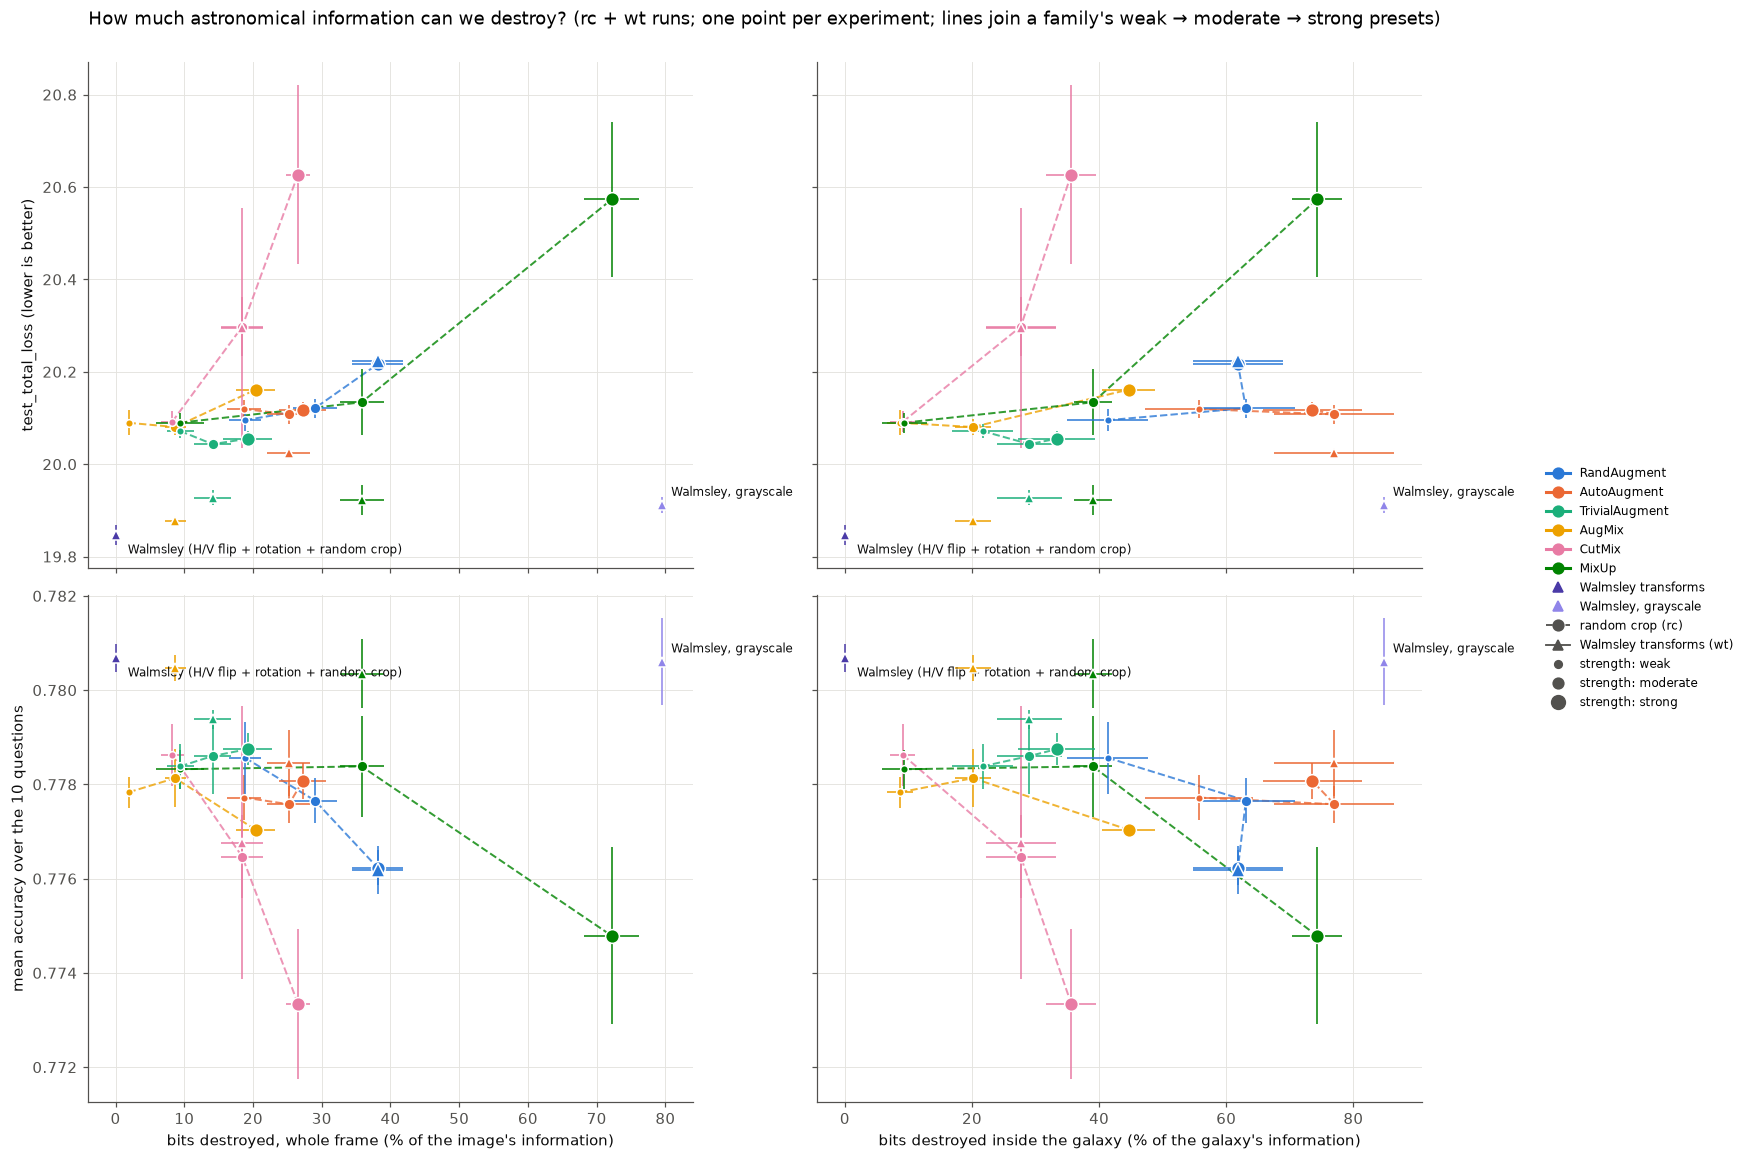

In [23]:
# ---- the answer figure: information destroyed vs what the model learns
if info_df.empty:
    print("no bits-destroyed values yet; section H figure skipped")
else:
    plot_df = info_df[info_df["modality"].isin(INFO_PLOT_MODALITIES)]
    X_AXES = [("frac_total", "bits destroyed, whole frame (% of the image's information)"),
              ("frac_source", "bits destroyed inside the galaxy (% of the galaxy's information)")]
    Y_AXES = [(LOSS, f"{LOSS} (lower is better)"),
              ("mean_task_accuracy", "mean accuracy over the 10 questions")]
    ANCHOR_LABELS = {"baseline_A": "resize", "baseline_B": "center crop", "baseline_C": "RRC only",
                     "baseline_rc": "random crop only", "walmsley_transforms": "Walmsley (H/V flip + rotation + random crop)",
                     "walmsley_transforms_gray": "Walmsley, grayscale"}
    SIZE = {"weak": 5, "moderate": 7, "strong": 9, None: 8}
    LABEL_OFFSET = {"baseline_A": (8, -12), "baseline_C": (8, 6), "walmsley_transforms_gray": (6, 6),
                    "walmsley_transforms": (8, -12)}
    fig, axes = plt.subplots(2, 2, figsize=(14, 10.5), sharex="col", sharey="row")
    for row, (ycol, ylab) in enumerate(Y_AXES):
        for col, (xcol, xlab) in enumerate(X_AXES):
            ax = axes[row, col]
            for (f, m), grp in plot_df.groupby(["family", "modality"]):
                if f in POLICY_FAMILIES + PHOTO_FAMILIES and len(grp) >= 2:
                    grp = grp.assign(_o=grp["strength"].map(STRENGTHS.index)).sort_values("_o")
                    ax.plot(100 * grp[f"{xcol}_mean"], grp[f"{ycol}_mean"], color=FAMILY_COLORS[f],
                            ls=MOD_LINESTYLE[m], lw=1.3, alpha=0.8, zorder=2)
            for e, r in plot_df.iterrows():
                c, hollow = color_of(e), r["family"].endswith("_photo")
                ax.errorbar(100 * r[f"{xcol}_mean"], r[f"{ycol}_mean"], xerr=100 * r[f"{xcol}_se"],
                            yerr=r[f"{ycol}_std"], fmt=MOD_MARKER.get(r["modality"], "X"), color=c,
                            ms=SIZE.get(r["strength"], 7), mfc="white" if hollow else c,
                            mec=c if hollow else "white", mew=1, elinewidth=1, capsize=0, zorder=3)
                if e in ANCHOR_LABELS:
                    ax.annotate(ANCHOR_LABELS[e], (100 * r[f"{xcol}_mean"], r[f"{ycol}_mean"]),
                                xytext=LABEL_OFFSET.get(e, (6, 5)),
                                textcoords="offset points", fontsize=8, color=INK)
            if row == 1:
                ax.set_xlabel(xlab)
            if col == 0:
                ax.set_ylabel(ylab)
    fam_present = [f for f in POLICY_FAMILIES + PHOTO_FAMILIES if f in set(plot_df["family"])]
    handles = [Line2D([], [], marker="o", ls="-", color=FAMILY_COLORS[f], ms=7, label=FAMILY_LABEL[f],
                      mfc="white" if f.endswith("_photo") else FAMILY_COLORS[f]) for f in fam_present]
    handles += [Line2D([], [], marker=mk, ls="", color=FAMILY_COLORS[k], ms=7, label=lab) for k, lab, mk in
                [(k, lab, mk) for k, lab, mk in [("baseline_centercrop", "baselines (deterministic)", "D"),
                                                 ("anchor_rrc", "RRC-only anchor", "s"),
                                                 ("walmsley", "Walmsley transforms", "^"),
                                                 ("walmsley_gray", "Walmsley, grayscale", "^")]
                 if k in {color_key(META[e]) for e in plot_df.index}]]
    handles += [MOD_HANDLES[m] for m in ["deterministic"] + MODALITIES if m in set(plot_df["modality"])]
    handles += [Line2D([], [], marker="o", ls="", color=INK2, ms=SIZE[s], label=f"strength: {s}") for s in STRENGTHS]
    fig.legend(handles=handles, loc="center left", bbox_to_anchor=(1.0, 0.5), fontsize=8)
    fig.suptitle(f"How much astronomical information can we destroy? ({' + '.join(INFO_PLOT_MODALITIES)} runs; "
                 "one point per experiment; lines join a "
                 "family's weak → moderate → strong presets)", y=1.0)
    fig.tight_layout()
    save(fig, "H_information_destroyed_vs_performance")
    plt.show()

In [24]:
# ---- reading the figure: does performance track how much is destroyed?
def _spearman(df, xcol, ycol):
    return df[xcol].rank().corr(df[ycol].rank()) if len(df) >= 3 else np.nan


if not info_df.empty:
    policies = info_df[info_df["family"].isin(POLICY_FAMILIES + PHOTO_FAMILIES)]
    subsets = {"all experiments": info_df, "policy runs only": policies,
               "policy runs, rc": policies[policies["modality"] == "rc"],
               "policy runs, wt": policies[policies["modality"] == "wt"]}
    corr = pd.DataFrame({name: {f"ρ({x}, {LOSS})": _spearman(df, f"{x}_mean", f"{LOSS}_mean")
                                for x in INFO_COLS} | {"n": len(df)} for name, df in subsets.items()}).T
    display(Markdown(f"**Spearman rank correlation between information destroyed and {LOSS}** "
                     "(positive = destroying more is worse)"))
    display(corr.round(2))

    dose = []
    for (f, m), grp in policies.groupby(["family", "modality"]):
        if {"weak", "strong"} <= set(grp["strength"]):
            w, s = grp[grp["strength"] == "weak"].iloc[0], grp[grp["strength"] == "strong"].iloc[0]
            dose.append({"family": f, "modality": m,
                         "Δ frac_source (strong − weak)": s["frac_source_mean"] - w["frac_source_mean"],
                         "Δ loss (strong − weak)": s[f"{LOSS}_mean"] - w[f"{LOSS}_mean"]})
    dose_df = pd.DataFrame(dose)
    if len(dose_df):
        dose_df["same direction"] = (np.sign(dose_df["Δ frac_source (strong − weak)"])
                                     == np.sign(dose_df["Δ loss (strong − weak)"]))
        display(Markdown("**Within a family: more destruction ↔ worse?** (weak → strong)"))
        display(dose_df.round(4))
    for e in ["baseline_B", "baseline_C", "walmsley_transforms", "walmsley_transforms_gray"]:
        if e in info_df.index:
            r = info_df.loc[e]
            print(f"{e:26s} destroys {100 * r['frac_total_mean']:5.1f}% of the frame, "
                  f"{100 * r['frac_source_mean']:5.1f}% of the galaxy -> {LOSS} {r[LOSS + '_mean']:.3f}")
else:
    corr, dose_df = pd.DataFrame(), pd.DataFrame()

**Spearman rank correlation between information destroyed and test_total_loss** (positive = destroying more is worse)

,"ρ(frac_total, test_total_loss)","ρ(frac_source, test_total_loss)",n
all experiments,0.10,0.03,35.0
policy runs only,0.35,0.24,30.0
"policy runs, rc",0.68,0.53,18.0
"policy runs, wt",0.43,0.31,6.0


**Within a family: more destruction ↔ worse?** (weak → strong)

,family,modality,Δ frac_source (strong − weak),Δ loss (strong − weak),same direction
0,augmix,rc,0.3595,0.0718,True
1,autoaugment,rc,0.1786,-0.0015,False
2,cutmix,rc,0.2648,0.5353,True
3,mixup,rc,0.6490,0.4832,True
4,randaugment,rc,0.2052,0.1215,True
5,trivialaugment,rc,0.1165,-0.0166,False


baseline_B                 destroys   0.0% of the frame,   0.0% of the galaxy -> test_total_loss 21.814
baseline_C                 destroys   0.0% of the frame,   0.0% of the galaxy -> test_total_loss 22.597
walmsley_transforms        destroys   0.0% of the frame,   0.0% of the galaxy -> test_total_loss 19.846
walmsley_transforms_gray   destroys  79.5% of the frame,  84.8% of the galaxy -> test_total_loss 19.912


**Answer (test split; runs as of 10 Oct 2026; 32 images × 2 draws per experiment; geometric transforms excluded).** A galaxy image carries ≈2.3 Mbit, of which the galaxy itself (≈5% of the frame) holds ≈110 kbit. Reading the right-hand panels, which show the share of the galaxy's own information destroyed:

1. **Geometry is free by definition, and it still decides most of the result [C14].** Center crop, RRC-only and Walmsley all sit at 0 bits, yet span 19.85 to 22.60 in test loss. Every policy destroys *exactly* the same bits in `rrc`, `rc` and `wt`, because only its non-geometric ops are measured. Even so, its `rrc` run is 2.5–3.2 loss points worse. RandomResizedCrop's damage is therefore not destroyed information. It is the crop distribution: large, random changes of apparent scale in training, while evaluation uses a center crop. Walmsley's gain likewise comes from injecting the right symmetries, not from destroying anything.
2. **Within a mechanism, destroying more is worse wherever strength matters at all [C12].** Along each family's weak → strong line in `rc`, the destroyed share of the galaxy grows (by +12 to +65 percentage points). For the four families whose loss changes significantly with strength (RandAugment, AugMix, CutMix, MixUp), the loss rises. AutoAugment and TrivialAugment are flat (changes of 0.002 and 0.017, not significant). Across the `rc` policy runs, Spearman ρ(bits destroyed, loss) ≈ +0.53.
3. **How much can we destroy? Most of it, if it's the right part [C13].** Grayscale removes ≈85% of the galaxy's bits and costs only +0.065 test loss over colour Walmsley. Most of those bits are the independent pixel noise of the three colour channels, plus the colour itself. The weak photometric and mixing presets destroy 9–22% and land within 0.08 of the best `rc` run. The same amount destroyed by the wrong mechanism is expensive: strong CutMix (≈36%) costs +0.54, because it pastes another galaxy's structure into the image, and strong MixUp (≈74%) costs +0.48.

So, in bits of the original image and with geometry counted as free: up to **≈85% of a galaxy's (pixel-level) information can be destroyed at almost no cost (colour)**. Tens of percent destroyed by pasting or heavy blending costs ≈0.5 loss points. Across all experiments the rank correlation between bits destroyed and loss is ≈0. The *amount* destroyed orders augmentations only within one mechanism; *which* information is destroyed matters more. The x-axis that should put every point on one curve is task-relevant information destroyed, i.e. I(Y; label) from probes (handoff §8, tiers 2–3).

## I. Conclusions

The prose below describes the full-data runs on the **test split** (`EVAL_SPLIT = "test"`), as of **10 Oct 2026**: 35 experiments × 5 seeds, strict seeds (the extra `rand_augment_all_ops` seeds 4200 and 12300 are dropped). Each run's checkpoint is the best by validation loss, evaluated once on the test set. All 175 re-evaluations reproduced their logged validation loss. Every claim has an ID, and the claim-check cell after it recomputes the supporting numbers from the loaded runs. **If a claim shows FAIL or N/A after new runs land, the prose for that claim is stale.**

**[C1] Center crop beats resize for deterministic preprocessing.** `baseline_B` scores 21.81 test loss and `baseline_A` 22.66 (Δ −0.85, p ≈ 3e-9). Resizing throws away native pixel scale; cropping the mostly-sky border does not.

**[C2] RandomResizedCrop was the dominant source of harm.** Replacing it with a fixed-size random crop improves every policy family at default strength by 2.49 (CutMix) to 3.17 loss points. RandAugment's `bulge_size` accuracy recovers from 0.519 to 0.604, so the earlier "photometric ops destroy bulge information" reading was a crop artefact. (The rrc runs trained on rescaled crops but were evaluated on unscaled center crops; see section H.)

**[C3] Symmetry augmentations deliver most of the attainable gain.** `walmsley_transforms` (19.846) beats every `rc` policy at every strength. The best `rc` run is `trivial_augment_rc` at 20.043 (Δ +0.20, p ≈ 2e-6).

**[C4] More strength does not help.** Within `rc`, strong is worse than weak for:

| family | strong − weak | p |
|---|---|---|
| RandAugment | +0.12 | 3e-5 |
| AugMix | +0.07 | 0.002 |
| CutMix | +0.54 | 0.003 |
| MixUp | +0.48 | 0.003 |

AutoAugment (−0.002, p 0.89) and TrivialAugment (−0.017, p 0.13) are flat. All weak presets sit within 0.05 of each other (20.07–20.12). Note that RandAugment weak is N=2, M=2 in the code.

**[C5] Policies on top of Walmsley transforms do not beat Walmsley.** No `wt` policy has a lower mean test loss than `walmsley_transforms`. AugMix, which is photometric-only, comes closest at 19.876 (+0.030). That gap is narrowly significant (Welch p 0.033; Holm p 0.036 over 6 `wt` policies), so AugMix on top of Walmsley is slightly **worse**, not a tie.

**[C6] Colour carries some task information.** Grayscale Walmsley is worse than colour Walmsley (19.912 vs 19.846, Δ +0.065, t ≈ 5, p ≈ 8e-4). Walmsley et al. grayscaled to avoid colour shortcuts, not for accuracy.

**[C7] Strong mixing is unstable.** Seed noise depends strongly on the crop.

| modality | median seed std (test loss) |
|---|---|
| `rrc` | ≈0.16 |
| `rc` | ≈0.020 |
| `wt` | ≈0.016 |

So instability is judged against the experiment's own modality. On that basis only CutMix/MixUp runs are flagged: `cutmix_wt` (0.260), `cutmix_strong_rc` (0.194), `mixup_strong_rc` (0.167), `mixup_rc` (0.071) and `cutmix_rc` (0.064). `cutmix_wt` looks bimodal rather than having one bad seed.

**[C8] Early-stopping patience does not truncate improving runs.** Every `rrc` and deterministic run was stopped by patience well before the budget. (`baseline_A`'s logs predate the "Early stopping triggered" message, but each of its runs ends exactly `PATIENCE_EPOCHS` after its best eval.) `rrc` policies peak later than the baselines (median best epoch ≈ 38, max 57, vs ≈ 14).

**[C9] RandomResizedCrop alone already costs performance, and the rrc policies add nothing on top.** `baseline_C` (RRC, no policy) scores 22.60, which is +0.78 worse than center crop (p ≈ 7e-4). Every `rrc` policy (22.72–23.30) is *worse* than RRC alone. The whole rrc block is dominated by the crop.

**[C10] Geometric compounding: partly supported.** The prediction was that the Walmsley gain Δ(rc → wt) shrinks as the policy re-applies geometry itself.
- `mixup_wt` (exposure 0) gains −0.211, the same as AugMix (−0.204, exposure 0), as predicted.
- RandAugment all-ops (exposure 0.60) gains nothing (+0.005).
- CutMix (exposure 0) gains nothing, with high variance.

The rank correlation between exposure and the gain is ρ ≈ +0.58 (n = 6). A photometric-only RandAugment `_wt` run (`rand_augment_wt`) is still the cleanest test.

**[C11] The 100-epoch cosine budget binds for `rc`/`wt`.** About half of the `rc`/`wt` runs (64/130) reach their best checkpoint in the last 10 epochs of the warmup-cosine schedule and run to `MAX_ITER` without early stopping. The median `rc`/`wt` best epoch is 90, while rrc runs and baselines stop at epoch ≈ 20–70. Because the LR anneals to 0 at `MAX_ITER`, a late minimum is partly built into the schedule. It still means a longer schedule might lower every `rc`/`wt` number, Walmsley included; the ranking is only guaranteed at this budget. (The training-set-size sweep in section K uses early stopping with a constant LR instead.)

**[C12] Within a family, destroying more of the galaxy's information is worse wherever strength matters** (section H). In `rc`, every family whose weak → strong change in test loss is significant (RandAugment, AugMix, CutMix, MixUp) gets worse as the destroyed share of the galaxy grows. AutoAugment and TrivialAugment are flat. Spearman ρ(bits destroyed in the galaxy, loss) over the `rc` policy runs is positive (≈ +0.53).

**[C13] Most of a galaxy's (pixel-level) information can be destroyed almost for free, if it is colour** (section H). With geometry excluded, `walmsley_transforms_gray` destroys ≈85% of the galaxy's bits, yet it is within 0.15 (here +0.065) of the best experiment, `walmsley_transforms`, which destroys 0.

**[C14] Geometry is free in bits but decides the loss** (section H). Each policy destroys the same bits in every modality (only non-geometric ops are measured), yet its `rrc` run is ≥ 2 loss points worse than its `rc` run. RRC's harm is the crop distribution, not destroyed information.

In [25]:
CLAIMS = []


def claim(cid, text):
    def deco(fn):
        CLAIMS.append((cid, text, fn))
        return fn
    return deco


def need(*exps):
    missing = [e for e in exps if not has(e)]
    if missing:
        raise LookupError(f"missing: {', '.join(missing)}")


@claim("C1", "baseline_B (center crop) mean < baseline_A (resize) mean")
def _c1():
    need("baseline_A", "baseline_B")
    w = welch(vals("baseline_B"), vals("baseline_A"))
    return mean("baseline_B") < mean("baseline_A"), \
        f"B {mean('baseline_B'):.4f} vs A {mean('baseline_A'):.4f}; Δ {w['d']:+.4f}, p {w['p']:.2g}"


@claim("C2", "every family improves rrc -> rc by > 1.0 at default strength, and RandAugment bulge_size recovers")
def _c2():
    df = EFFECTS[("rrc", "rc")]
    if not len(df):
        raise LookupError("no rrc/rc pairs")
    ra_rrc, ra_rc = default_exp[("randaugment", "rrc")], default_exp[("randaugment", "rc")]
    need(ra_rrc, ra_rc)
    bulge = mean(ra_rc, f"{EVAL_SPLIT}_bulge_size_accuracy") - mean(ra_rrc, f"{EVAL_SPLIT}_bulge_size_accuracy")
    ok = bool((df["delta"] < -1.0).all()) and len(df) == len(POLICY_FAMILIES) and bulge > 0.05
    return ok, (f"Δ(rrc→rc) {df['delta'].max():+.3f} .. {df['delta'].min():+.3f} over {len(df)} families; "
                f"RandAugment bulge_size acc {mean(ra_rrc, EVAL_SPLIT + '_bulge_size_accuracy'):.3f} → "
                f"{mean(ra_rc, EVAL_SPLIT + '_bulge_size_accuracy'):.3f}")


@claim("C3", "min over all rc experiments of mean loss > walmsley_transforms mean")
def _c3():
    need(REFERENCE)
    rc = [e for e in agg_df.index if META[e]["modality"] == "rc" and not META[e]["is_anchor"]]
    if not rc:
        raise LookupError("no rc experiments")
    best = min(rc, key=mean)
    w = welch(vals(best), vals(REFERENCE))
    return mean(best) > mean(REFERENCE), \
        f"best rc = {best} {mean(best):.4f} vs {REFERENCE} {mean(REFERENCE):.4f} (Δ {w['d']:+.4f}, p {w['p']:.2g})"


@claim("C4", "rc: strong > weak for RandAugment, AugMix, CutMix, MixUp; all weak presets within 0.1 of each other")
def _c4():
    parts, ok, weak = [], True, []
    for f in ["randaugment", "augmix", "cutmix", "mixup", "autoaugment", "trivialaugment"]:
        w_e, s_e = find(f, "weak", "rc"), find(f, "strong", "rc")
        need(w_e, s_e)
        d = mean(s_e) - mean(w_e)
        weak.append(mean(w_e))
        if f in ("randaugment", "augmix", "cutmix", "mixup"):
            ok &= d > 0
        parts.append(f"{FAMILY_LABEL[f]} {d:+.3f} (p {welch(vals(s_e), vals(w_e))['p']:.2g})")
    spread = max(weak) - min(weak)
    ok &= spread < 0.1
    return ok, "strong − weak: " + "; ".join(parts) + f"; weak spread {spread:.3f}"


@claim("C5", "no wt policy has a lower mean than walmsley_transforms (closest reported with Holm p)")
def _c5():
    need(REFERENCE)
    wt = [e for e in agg_df.index if META[e]["modality"] == "wt" and META[e]["family"] in POLICY_FAMILIES + PHOTO_FAMILIES]
    if not wt:
        raise LookupError("no wt policy runs")
    tab = compare_table(wt, lambda e: REFERENCE)
    best = tab.iloc[0]
    return bool((tab["delta"] > 0).all()), \
        (f"closest: {best['experiment']} Δ {best['delta']:+.4f} (Welch p {best['p']:.2g}, Holm p {best['p_holm']:.2g} "
         f"over {len(tab)} wt policies → {best['label']})")


@claim("C6", "walmsley_transforms_gray mean > walmsley_transforms mean, Welch p < ALPHA")
def _c6():
    need("walmsley_transforms", "walmsley_transforms_gray")
    w = welch(vals("walmsley_transforms_gray"), vals("walmsley_transforms"))
    return w["d"] > 0 and w["p"] < ALPHA, f"gray − colour Δ {w['d']:+.4f} (t {w['t']:.1f}, p {w['p']:.2g})"


@claim("C7", "every experiment flagged unstable (std > 3x its modality's median std) is a CutMix/MixUp variant; >=1 flagged")
def _c7():
    fams = {META[e]["family"] for e in FLAGGED}
    return bool(FLAGGED) and fams <= {"cutmix", "mixup"}, \
        (f"flagged ({STD_FLAG_SCOPE}): {', '.join(f'{e} ({stds[e]:.3f})' for e in FLAGGED) or 'none'}; "
         f"median std per modality: " + ", ".join(f"{m} {v:.3f}" for m, v in modality_median.items()))


@claim("C8", "patience does not truncate improving runs: rrc policies peak later than the baselines, "
             "and every rrc/deterministic run early-stopped >= PATIENCE epochs before the budget")
def _c8():
    base = per_run_df[per_run_df["family"].isin(["baseline_resize", "baseline_centercrop"])]["best_epoch"]
    rrc_pol = per_run_df[(per_run_df["modality"] == "rrc") & per_run_df["family"].isin(POLICY_FAMILIES)]
    early_mods = per_run_df[per_run_df["modality"].isin(["rrc", "deterministic"])]
    limit = MAX_ITER / ITERS_PER_EPOCH - PATIENCE_EPOCHS
    # older logs (baseline_A) predate the "Early stopping triggered" message: also count a run that ended
    # before the budget, >= PATIENCE epochs after its best eval, as stopped by patience
    by_patience = early_mods["early_stopped"] | ((early_mods["last_iter"] < MAX_ITER - 1) &
                                                 (early_mods["last_epoch"] - early_mods["best_epoch"] >= PATIENCE_EPOCHS))
    ok = rrc_pol["best_epoch"].median() > base.median() and bool(by_patience.all()) \
        and bool((early_mods["best_epoch"] <= limit).all())
    return ok, (f"median best epoch: baselines {base.median():.0f}, rrc policies {rrc_pol['best_epoch'].median():.0f} "
                f"(max {rrc_pol['best_epoch'].max()}); rrc/deterministic runs stopped by patience: "
                f"{int(by_patience.sum())}/{len(early_mods)} ({int(early_mods['early_stopped'].sum())} with the log message)")


@claim("C9", "baseline_C (RRC only) is worse than baseline_B (Welch p < ALPHA), and no rrc policy beats baseline_C")
def _c9():
    need("baseline_B", "baseline_C")
    w = welch(vals("baseline_C"), vals("baseline_B"))
    rrc_pol = [e for e in agg_df.index if META[e]["modality"] == "rrc" and META[e]["family"] in POLICY_FAMILIES]
    best = min(rrc_pol, key=mean)
    return w["d"] > 0 and w["p"] < ALPHA and mean(best) > mean("baseline_C"), \
        (f"C − B Δ {w['d']:+.4f} (p {w['p']:.2g}); baseline_C {mean('baseline_C'):.4f}; "
         f"best rrc policy {best} {mean(best):.4f}")


@claim("C10", "zero-exposure prediction: mixup_wt's Δ(rc→wt) is within 2 SE of augmix's (Spearman ρ reported)")
def _c10():
    df = EFFECTS[("rc", "wt")]
    if not EXPOSURE or len(df) < 3:
        raise LookupError("need exposure and >= 3 rc/wt pairs")
    if not {"mixup", "augmix"} <= set(df["family"]):
        raise LookupError("mixup_wt or augmix_wt missing")
    d = df.set_index("family")
    rho = df["family"].map(EXPOSURE).rank().corr(df["delta"].rank())
    gap = d.at["mixup", "delta"] - d.at["augmix", "delta"]
    se = math.hypot(d.at["mixup", "se"], d.at["augmix", "se"])
    outliers = [f for f in d.index if EXPOSURE.get(f) == 0 and d.at[f, "p_holm"] >= ALPHA]
    return abs(gap) < 2 * se, (f"Δ(rc→wt) mixup {d.at['mixup', 'delta']:+.3f} vs augmix {d.at['augmix', 'delta']:+.3f} "
                               f"(gap {gap:+.3f} ± {se:.3f}); Spearman ρ(exposure, Δ) = {rho:+.2f} (n = {len(df)}); "
                               f"zero-exposure families without a significant gain: {outliers or 'none'}")


@claim("C11", "the 100-epoch cosine budget binds for rc/wt: >= 40% of rc/wt runs have their best epoch in the last "
              "PATIENCE epochs, and the median rc/wt best epoch is >= 80")
def _c11():
    rcwt = per_run_df[per_run_df["modality"].isin(["rc", "wt"])]
    if rcwt.empty:
        raise LookupError("no rc/wt runs")
    limit = MAX_ITER / ITERS_PER_EPOCH - PATIENCE_EPOCHS
    late = rcwt["best_epoch"] > limit
    return late.mean() >= 0.4 and rcwt["best_epoch"].median() >= 80, \
        (f"{int(late.sum())}/{len(rcwt)} rc/wt runs peak after epoch {limit:.0f}; "
                                f"median best epoch {rcwt['best_epoch'].median():.0f}; "
                                f"{int((~rcwt['early_stopped']).sum())} ran to MAX_ITER without early stopping")


@claim("C12", "rc: every family whose weak→strong loss change is significant (Welch p < ALPHA) moves in the same "
              "direction as the galaxy bits destroyed (>= 3 such families), and Spearman ρ(frac_source, loss) > 0")
def _c12():
    if info_df.empty or not len(dose_df):
        raise LookupError("no bits-destroyed results")
    rc_dose = dose_df[dose_df["modality"] == "rc"].copy()
    rc_dose["p_loss"] = [welch(vals(find(f, "strong", "rc")), vals(find(f, "weak", "rc")))["p"] for f in rc_dose["family"]]
    sig = rc_dose[rc_dose["p_loss"] < ALPHA]
    rho = corr.loc["policy runs, rc", f"ρ(frac_source, {LOSS})"]
    ok = len(sig) >= 3 and bool(sig["same direction"].all()) and rho > 0
    flat = rc_dose.loc[rc_dose["p_loss"] >= ALPHA, "family"].tolist()
    return ok, (f"significant strength effect: {', '.join(sig['family'])} -> same direction "
                f"{int(sig['same direction'].sum())}/{len(sig)}; flat (n.s.): {', '.join(flat) or 'none'}; "
                f"ρ = {rho:+.2f} over {int(corr.loc['policy runs, rc', 'n'])} rc policy runs")


@claim("C13", "walmsley_transforms_gray destroys > 50% of the galaxy's bits (geometry excluded) yet is within 0.15 of the "
              "lowest-loss experiment, walmsley_transforms (0 bits)")
def _c13():
    if info_df.empty or not {"walmsley_transforms", "walmsley_transforms_gray"} <= set(info_df.index):
        raise LookupError("bits destroyed missing for walmsley_transforms(_gray)")
    w, g = info_df.loc["walmsley_transforms"], info_df.loc["walmsley_transforms_gray"]
    best = agg_df[f"{LOSS}_mean"].idxmin()
    gap = g[f"{LOSS}_mean"] - w[f"{LOSS}_mean"]
    ok = g["frac_source_mean"] > 0.5 and w["frac_source_mean"] < 1e-6 and best == "walmsley_transforms" and gap < 0.15
    return ok, (f"galaxy bits destroyed: gray {100 * g['frac_source_mean']:.1f}%, colour "
                f"{100 * w['frac_source_mean']:.1f}%; loss gap {gap:+.3f}; lowest-loss experiment: {best}")


@claim("C14", "each policy destroys the same bits in rrc and rc (|Δ| < 1 pp) while its rrc run is >= 2 loss points worse")
def _c14():
    rows = []
    for f in POLICY_FAMILIES:
        a, b = default_exp[(f, "rrc")], default_exp[(f, "rc")]
        if a in info_df.index and b in info_df.index:
            rows.append((f, info_df.at[a, "frac_source_mean"] - info_df.at[b, "frac_source_mean"],
                         info_df.at[a, f"{LOSS}_mean"] - info_df.at[b, f"{LOSS}_mean"]))
    if not rows:
        raise LookupError("no rrc/rc pairs with bits destroyed")
    ok = all(abs(db) < 0.01 and dl >= 2.0 for _, db, dl in rows)
    return ok, (f"max |Δ bits| {100 * max(abs(db) for _, db, _ in rows):.2f} pp; Δ loss (rrc − rc) "
                f"{min(dl for *_, dl in rows):+.2f} .. {max(dl for *_, dl in rows):+.2f} over {len(rows)} families")


check_rows = []
for cid, text, fn in CLAIMS:
    try:
        ok, evidence = fn()
        status = "PASS" if ok else "FAIL"
    except LookupError as err:
        status, evidence = "N/A", str(err)
    check_rows.append({"claim": cid, "status": status, "check": text, "evidence": evidence})
claims_df = pd.DataFrame(check_rows)

# every [Cn] tag in the section-H markdown must have a check, and vice versa
_nb_path = Path("augmentation_results.ipynb")
if _nb_path.exists():
    _md = "".join("".join(c["source"]) for c in json.loads(_nb_path.read_text())["cells"]
                  if c["cell_type"] == "markdown" and "## I. Conclusions" in "".join(c["source"]))
    _prose_ids, _check_ids = set(re.findall(r"\*\*\[(C\d+)\]", _md)), {cid for cid, _, _ in CLAIMS}
    if _prose_ids != _check_ids:
        warnings.warn(f"claim IDs out of sync: prose only {sorted(_prose_ids - _check_ids)}, "
                      f"checks only {sorted(_check_ids - _prose_ids)}")
    else:
        print(f"claim IDs in sync: {len(_check_ids)} conclusions, {len(_check_ids)} checks")
with pd.option_context("display.max_colwidth", 200):
    display(claims_df.style.map(lambda s: {"PASS": "color: #008300; font-weight: bold",
                                           "FAIL": "color: #a52c2b; font-weight: bold",
                                           "N/A": "color: #52514e"}.get(s, ""), subset=["status"])
            .hide(axis="index"))
print(" | ".join(f"{r['claim']}: {r['status']}" for r in check_rows))

claim IDs in sync: 14 conclusions, 14 checks


claim,status,check,evidence
C1,PASS,baseline_B (center crop) mean < baseline_A (resize) mean,"B 21.8136 vs A 22.6612; Δ -0.8476, p 2.5e-09"
C2,PASS,"every family improves rrc -> rc by > 1.0 at default strength, and RandAugment bulge_size recovers",Δ(rrc→rc) -2.492 .. -3.173 over 6 families; RandAugment bulge_size acc 0.519 → 0.604
C3,PASS,min over all rc experiments of mean loss > walmsley_transforms mean,"best rc = trivial_augment_rc 20.0434 vs walmsley_transforms 19.8463 (Δ +0.1971, p 2.2e-06)"
C4,PASS,"rc: strong > weak for RandAugment, AugMix, CutMix, MixUp; all weak presets within 0.1 of each other",strong − weak: RandAugment +0.122 (p 2.6e-05); AugMix +0.072 (p 0.0023); CutMix +0.535 (p 0.0033); MixUp +0.483 (p 0.0027); AutoAugment -0.002 (p 0.89); TrivialAugment -0.017 (p 0.13); weak spread 0.048
C5,PASS,no wt policy has a lower mean than walmsley_transforms (closest reported with Holm p),"closest: augmix_wt Δ +0.0299 (Welch p 0.033, Holm p 0.036 over 6 wt policies → worse)"
C6,PASS,"walmsley_transforms_gray mean > walmsley_transforms mean, Welch p < ALPHA","gray − colour Δ +0.0652 (t 5.4, p 0.00084)"
C7,PASS,every experiment flagged unstable (std > 3x its modality's median std) is a CutMix/MixUp variant; >=1 flagged,"flagged (modality): cutmix_wt (0.260), cutmix_strong_rc (0.194), mixup_strong_rc (0.167), mixup_rc (0.071), cutmix_rc (0.064); median std per modality: deterministic 0.045, rc 0.020, rrc 0.160, wt 0.016"
C8,PASS,"patience does not truncate improving runs: rrc policies peak later than the baselines, and every rrc/deterministic run early-stopped >= PATIENCE epochs before the budget","median best epoch: baselines 14, rrc policies 38 (max 57); rrc/deterministic runs stopped by patience: 45/45 (40 with the log message)"
C9,PASS,"baseline_C (RRC only) is worse than baseline_B (Welch p < ALPHA), and no rrc policy beats baseline_C",C − B Δ +0.7835 (p 0.00066); baseline_C 22.5971; best rrc policy mixup 22.7212
C10,PASS,zero-exposure prediction: mixup_wt's Δ(rc→wt) is within 2 SE of augmix's (Spearman ρ reported),"Δ(rc→wt) mixup -0.211 vs augmix -0.204 (gap -0.007 ± 0.036); Spearman ρ(exposure, Δ) = +0.58 (n = 6); zero-exposure families without a significant gain: ['cutmix']"


C1: PASS | C2: PASS | C3: PASS | C4: PASS | C5: PASS | C6: PASS | C7: PASS | C8: PASS | C9: PASS | C10: PASS | C11: PASS | C12: PASS | C13: PASS | C14: PASS


## J. Export

Every table is written as CSV (the data) and as a LaTeX `tabular` that compiles as-is (special characters escaped, missing values as `--`). Two tables are formatted for the paper instead of being raw dumps; the full data stays in the CSV:
- `aggregated.tex`: the full-data results;
- `sweep_summary.tex`: the training-set-size sweep, written in section K.

Both are complete `table*` environments for a two-column page; they need `\usepackage{booktabs}`.

In [26]:
_TEX = {"\\": r"\textbackslash{}", "&": r"\&", "%": r"\%", "$": r"\$", "#": r"\#", "_": r"\_",
        "{": r"\{", "}": r"\}", "~": r"\textasciitilde{}", "^": r"\textasciicircum{}"}


_TEX_UNICODE = {"—": "--", "–": "--", "−": "-", "±": r"$\pm$", "Δ": r"$\Delta$", "ρ": r"$\rho$", "σ": r"$\sigma$",
                "→": r"$\rightarrow$", "≥": r"$\geq$", "≤": r"$\leq$", "×": r"$\times$", "⊂": r"$\subset$",
                "↓": r"$\downarrow$", "↑": r"$\uparrow$", "°": r"$^\circ$", "λ": r"$\lambda$", "α": r"$\alpha$",
                "…": r"\ldots{}", "·": r"$\cdot$", "∩": r"$\cap$"}


def tex_escape(s):
    """Escape LaTeX special characters, and map the non-ASCII symbols used in these tables to LaTeX."""
    out = "".join(_TEX.get(ch, ch) for ch in str(s))
    for k, v in _TEX_UNICODE.items():
        out = out.replace(k, v)
    return "".join(ch if ord(ch) < 128 else "?" for ch in out)       # anything left over would break pdflatex


def raw_tex(df, path):
    """Compilable booktabs `tabular` dump of a data table (for reference, not formatted for the paper)."""
    cols = list(df.columns)
    align = "".join("r" if pd.api.types.is_numeric_dtype(df[c]) else "l" for c in cols)

    def cell(v):
        if isinstance(v, (bool, np.bool_)):
            return "yes" if v else "no"
        if v is None or (not isinstance(v, str) and pd.isna(v)):
            return "--"
        if isinstance(v, (float, np.floating)):
            return f"{v:.4f}"
        return tex_escape(v)

    lines = [f"\\begin{{tabular}}{{{align}}}", r"\toprule", " & ".join(tex_escape(c) for c in cols) + r" \\", r"\midrule"]
    lines += [" & ".join(cell(v) for v in row) + r" \\" for row in df.itertuples(index=False)]
    lines += [r"\bottomrule", r"\end{tabular}"]
    path.write_text("\n".join(lines) + "\n")


def export(df, name, index=False, tex=True):
    df = df.reset_index() if index else df
    df.to_csv(TABLE_DIR / f"{name}.csv", index=False)
    if tex:
        raw_tex(df, TABLE_DIR / f"{name}.tex")
    return name


# ---- paper-formatted tables
PAPER_NAMES = {"baseline_A": "Resize (no augmentation)", "baseline_B": "No augmentation (centre crop)",
               "baseline_C": "Random resized crop", "baseline_rc": "Random crop",
               "walmsley_transforms": "H/V flip + rotation + random crop",
               "walmsley_transforms_gray": "H/V flip + rotation + random crop, greyscale"}
PAPER_INCLUDE_RRC = False          # the RandomResizedCrop block of the full-data table
Q_SHORT = {"smooth_or_featured": "Smooth", "disk_edge_on": "Edge-on", "has_spiral_arms": "Spiral", "bar": "Bar",
           "bulge_size": "Bulge", "how_rounded": "Round", "edge_on_bulge": "EO bulge", "spiral_winding": "Winding",
           "spiral_arm_count": "Arms", "merging": "Merger"}


def paper_name(e):
    if e in PAPER_NAMES:
        return PAPER_NAMES[e]
    m = parse_experiment(e)
    name = FAMILY_LABEL.get(m["family"], m["family"])
    if m["strength"] and m["strength"] != DEFAULT_STRENGTH.get(m["family"]):
        name += f" ({m['strength']})"
    return name


def paper_groups(available, include_rrc=False, standard_only=True):
    """Row blocks for the paper tables: no policy; policy after H/V flip + rotation + random crop; policy after random
    crop. With `standard_only`, each policy appears only at its standard strength (moderate; strong for RandAugment)."""
    def policies(mod):
        exps = [e for e in available if META.get(e, parse_experiment(e))["modality"] == mod
                and parse_experiment(e)["family"] in POLICY_FAMILIES
                and (not standard_only
                     or parse_experiment(e)["strength"] == DEFAULT_STRENGTH[parse_experiment(e)["family"]])]
        return sorted(exps, key=lambda e: (POLICY_FAMILIES.index(parse_experiment(e)["family"]),
                                           STRENGTHS.index(parse_experiment(e)["strength"])))
    base = [e for e in ["baseline_A", "baseline_B", "baseline_rc", "walmsley_transforms", "walmsley_transforms_gray"]
            if e in available]
    groups = [("No policy", base), ("Policy after H/V flip + rotation + random crop", policies("wt")),
              ("Policy after random crop", policies("rc"))]
    if include_rrc:
        groups.append(("Policy after random resized crop",
                       [e for e in ["baseline_C"] if e in available] + policies("rrc")))
    return [(t, rows) for t, rows in groups if rows]


def write_full_data_table(path):
    """Full-data test accuracies: mean over the ten questions and per question (per cent, mean over five seeds)."""
    acc_cols = ["mean_task_accuracy_mean"] + [f"{EVAL_SPLIT}_{t}_accuracy_mean" for t in TASKS]
    groups = paper_groups(set(agg_df.index), PAPER_INCLUDE_RRC)
    shown = [e for _, rows in groups for e in rows]
    best = {c: agg_df.loc[shown, c].max() for c in acc_cols}
    ncol = 1 + len(acc_cols)
    lines = [r"\begin{table*}", r"\centering", r"\footnotesize", r"\setlength{\tabcolsep}{3pt}",
             r"\caption{Test accuracy with the full training set: accuracy of the most-voted answer, in per cent, as the "
             r"mean over the ten Galaxy Zoo questions and per question (mean over five seeds). Policies are at their "
             r"standard strength (the effect of strength is shown in Fig.~\ref{fig:strength}). The best value in each "
             r"column is in bold.}",
             r"\label{tab:full_data}",
             f"\\begin{{tabular}}{{l{'r' * (ncol - 1)}}}", r"\toprule",
             f" & \\multicolumn{{{ncol - 1}}}{{c}}{{Test accuracy (\\%)}} \\\\",
             f"\\cmidrule(lr){{2-{ncol}}}",
             "Augmentation & Mean & " + " & ".join(Q_SHORT[t] for t in TASKS) + r" \\",
             r"\midrule"]
    for gi, (title, rows) in enumerate(groups):
        if gi:
            lines.append(r"\midrule")
        lines.append(f"\\multicolumn{{{ncol}}}{{l}}{{\\textit{{{title}}}}} \\\\")
        for e in rows:
            label = r"\qquad + greyscale" if e == "walmsley_transforms_gray" else f"\\quad {tex_escape(paper_name(e))}"
            cells = [label]
            for c in acc_cols:
                v = 100 * agg_df.at[e, c]
                cells.append(f"\\textbf{{{v:.1f}}}" if np.isclose(agg_df.at[e, c], best[c]) else f"{v:.1f}")
            lines.append(" & ".join(cells) + r" \\")
    lines += [r"\bottomrule", r"\end{tabular}", r"\end{table*}"]
    path.write_text("\n".join(lines) + "\n")


written = [
    export(per_run_df.drop(columns=["run_dir"]), "per_run"),
    export(agg_df.reset_index(), "aggregated", tex=False),
    export(inventory_df, "inventory"),
    export(stats_vs_ref, f"stats_vs_reference_{MODALITY}"),
    export(stats_vs_anchor, f"stats_vs_anchor_{MODALITY}"),
    export(slopes_df, f"strength_slopes_{MODALITY}"),
    export(EFFECTS[("rrc", "rc")], "effect_rrc_to_rc"),
    export(EFFECTS[("rc", "wt")].assign(exposure=lambda d: d["family"].map(EXPOSURE)) if len(EFFECTS[("rc", "wt")])
           else EFFECTS[("rc", "wt")], "effect_rc_to_wt"),
    export(seed_table.reset_index(), "per_seed_total_loss"),
    export(claims_df, "claim_check"),
]
if not info_df.empty:
    written += [export(info_df.reset_index(names="experiment"), "information_destroyed"),
                export(corr.reset_index(names="subset"), "information_destroyed_correlation")]
    if len(dose_df):
        written += [export(dose_df, "information_destroyed_dose")]
if delta_acc_df is not None:
    written += [export(delta_acc_df.round(3).reset_index(names="experiment"), f"delta_accuracy_pp_{MODALITY}")]
write_full_data_table(TABLE_DIR / "aggregated.tex")
print(f"tables ({TABLE_DIR}/, .csv + .tex): {', '.join(written)}; aggregated.tex is the paper table")
print(f"figures ({FIG_VIEW_DIR}/, .png + .pdf): {', '.join(dict.fromkeys(SAVED_FIGURES))}")

tables (results/tables/, .csv + .tex): per_run, aggregated, inventory, stats_vs_reference_rc, stats_vs_anchor_rc, strength_slopes_rc, effect_rrc_to_rc, effect_rc_to_wt, per_seed_total_loss, claim_check, information_destroyed, information_destroyed_correlation, information_destroyed_dose, delta_accuracy_pp_rc; aggregated.tex is the paper table
figures (results/figures/rc/, .png + .pdf): B_baselines, C_ranked_total_loss, C_delta_accuracy_heatmap, C_delta_rmse_heatmap, D_strength_dose_response, E_family_by_modality, E_wt_gain_vs_geometric_exposure, E_focus_tasks, F_best_epoch, F_val_loss_curves, F_seed_spread, H_information_destroyed_vs_performance


## K. Training-set-size sweep

Does the ranking of augmentations change when labels are scarce? The same experiments are trained on fixed, nested random subsets of the training split (1%, 5%, 20%, 50%). Every run is evaluated on the **full test split** at its best checkpoint.

**Protocol of the sweep runs** (`train.py`): AdamW at lr 1e-4, constant after a 100-step warmup; early stopping with patience 10 evaluations on a fixed 5,000-image validation subset; bf16.

**Runs are discovered automatically** from `SWEEP_ROOT/frac_<f>/<experiment>_<seed>/DONE.json`. Runs without `DONE.json` count as running. Re-run the notebook as runs finish.

**The 100% point** (`SWEEP_FULL_DATA`) comes from the original full-data runs: their best checkpoint, re-evaluated on the test split by `evaluate.py` (`TEST.json`). Those runs used the earlier protocol (100-epoch cosine schedule, selection on the full validation set), so the 100% point is drawn **hollow** and is not strictly the same protocol as the other fractions. `baseline_rc` has no full-data run.

In [27]:
# ---- discover the sweep runs (+ the full-data test evaluations)
SW_TASK_ACC = [f"test_{t}_accuracy" for t in TASKS]
SW_FULL_LABEL = "full data (original runs)"
sw_rows, sw_running = [], []
for frac_dir in (sorted(SWEEP_ROOT.glob("frac_*")) if SWEEP_ROOT.exists() else []):
    try:
        frac = float(frac_dir.name.split("_", 1)[1])
    except ValueError:
        continue
    for run_dir in sorted(p for p in frac_dir.iterdir() if p.is_dir()):
        m = RUN_DIR_RE.match(run_dir.name)
        if not m:
            continue
        if not (run_dir / "DONE.json").exists():
            sw_running.append({"experiment": m["experiment"], "seed": m["seed"], "fraction": frac})
            continue
        done = json.loads((run_dir / "DONE.json").read_text())
        if "test" not in done:
            continue
        cfg = json.loads((run_dir / "config.json").read_text()) if (run_dir / "config.json").exists() else {}
        sw_rows.append({"experiment": m["experiment"], "seed": m["seed"], "fraction": frac,
                        "n_train": cfg.get("train_size"), "source": "sweep",
                        "stopped_early": done.get("stopped_early"), "best_iter": done.get("best_iter"),
                        "train_hours": done.get("train_seconds", np.nan) / 3600,
                        **{f"test_{k}": v for k, v in done["test"].items()}})

SW_EXPS = sorted({r["experiment"] for r in sw_rows} | {r["experiment"] for r in sw_running})
n_full_train = next((r["n_train"] / r["fraction"] for r in sw_rows if r["n_train"]), np.nan)
if SWEEP_FULL_DATA:
    for e in SW_EXPS:
        for run_dir in sorted(RUNS_ROOT.glob(f"{e}_*")):
            m = RUN_DIR_RE.match(run_dir.name)
            if not m or m["experiment"] != e or not (run_dir / "TEST.json").exists():
                continue
            if STRICT_SEEDS and m["seed"] not in EXPECTED_SEEDS:
                continue
            rec = json.loads((run_dir / "TEST.json").read_text())
            if "test" not in rec:
                continue
            sw_rows.append({"experiment": e, "seed": m["seed"], "fraction": 1.0, "n_train": round(n_full_train),
                            "source": SW_FULL_LABEL, "best_iter": rec.get("iter"),
                            **{f"test_{k}": v for k, v in rec["test"].items()}})

sweep_df = pd.DataFrame(sw_rows)
if sweep_df.empty:
    print(f"no finished sweep runs under {SWEEP_ROOT} yet")
else:
    sweep_df["mean_task_accuracy"] = sweep_df[SW_TASK_ACC].mean(axis=1)
    for col in ("family", "modality"):
        sweep_df[col] = sweep_df["experiment"].map(lambda e: parse_experiment(e)[col])
    SW_FRACS = sorted(sweep_df["fraction"].unique())

    # progress: finished seeds per experiment and fraction (+ running)
    done_n = sweep_df.groupby(["experiment", "fraction"])["seed"].nunique()
    run_n = pd.DataFrame(sw_running).groupby(["experiment", "fraction"])["seed"].nunique() if sw_running else pd.Series(dtype=int)
    all_fracs = sorted(set(SW_FRACS) | {r["fraction"] for r in sw_running})
    progress = pd.DataFrame(index=SW_EXPS, columns=[f"{f:.0%}" for f in all_fracs], dtype=object)
    for e in SW_EXPS:
        for f in all_fracs:
            d, r = int(done_n.get((e, f), 0)), int(run_n.get((e, f), 0))
            progress.loc[e, f"{f:.0%}"] = (f"{d}" if d else "·") + (f" (+{r} running)" if r else "")
    print(f"{(sweep_df['source'] == 'sweep').sum()} finished sweep runs, {len(sw_running)} running; "
          f"{(sweep_df['source'] != 'sweep').sum()} full-data test evaluations")
    display(Markdown("**Finished seeds per experiment and training fraction** (out of "
                     f"{len(EXPECTED_SEEDS)}; 100% = original full-data runs)"))
    display(progress)
    not_early = sweep_df[(sweep_df["source"] == "sweep") & (sweep_df["stopped_early"] == False)]  # noqa: E712
    if len(not_early):
        warnings.warn(f"{len(not_early)} sweep runs hit the iteration cap instead of early stopping")

183 finished sweep runs, 8 running; 70 full-data test evaluations


**Finished seeds per experiment and training fraction** (out of 5; 100% = original full-data runs)

,1%,5%,20%,100%
augmix_rc,5,5,·,5
augmix_wt,5,5,5,5
auto_augment_rc,5,5,·,5
auto_augment_wt,5,5,3 (+2 running),5
baseline_B,5,5,5,5
baseline_rc,5,5,5,·
cutmix_rc,5,5,·,5
cutmix_wt,5,5,· (+1 running),5
mixup_rc,5,5,·,5
mixup_wt,5,5,5,5


In [28]:
# ---- aggregate over seeds; plotting helpers
SW_METRICS = ["test_total_loss", "mean_task_accuracy"] + SW_TASK_ACC
SW_WT = ["walmsley_transforms"] + [f"{f}_wt" for f in ["augmix", "trivial_augment", "mixup", "auto_augment",
                                                         "rand_augment_all_ops", "cutmix"]]
SW_RC = ["baseline_rc"] + [f"{f}_rc" for f in ["augmix", "trivial_augment", "mixup", "auto_augment",
                                                "rand_augment_all_ops", "cutmix"]]
SW_LABEL = {"walmsley_transforms": "Walmsley (H/V flip + rotation + random crop)", "baseline_B": "no aug (center crop)",
            "baseline_rc": "random crop only"}


def sw_label(e):
    meta = parse_experiment(e)
    return SW_LABEL.get(e, f"{FAMILY_LABEL.get(meta['family'], meta['family'])} ({meta['modality']})")


def sw_style(e):
    meta = parse_experiment(e)
    color = FAMILY_COLORS.get(color_key(meta), "#000000")
    return dict(color=color, ls=MOD_LINESTYLE.get(meta["modality"], "-"), marker=MOD_MARKER.get(meta["modality"], "o"))


if not sweep_df.empty:
    g = sweep_df.groupby(["experiment", "fraction"])
    sweep_agg = g[SW_METRICS].agg(["mean", "std", "count"])
    sweep_agg.columns = [f"{m}_{s}" for m, s in sweep_agg.columns]
    sweep_agg["n_train"] = g["n_train"].first()
    sweep_agg["source"] = g["source"].first()
    sweep_agg = sweep_agg.reset_index()


def sw_plot_lines(ax, exps, metric, scale=1.0, ref=None):
    """One line per experiment across training fractions: mean +- seed std; 100% (old protocol) hollow."""
    for e in exps:
        d = sweep_agg[sweep_agg["experiment"] == e].sort_values("fraction")
        if d.empty:
            continue
        st = sw_style(e)
        lw, alpha = (1.4, 0.75) if e == ref else (2, 1)
        ax.plot(d["fraction"], scale * d[f"{metric}_mean"], color=st["color"], ls=st["ls"], lw=lw, alpha=alpha,
                label=sw_label(e) + (" [reference]" if e == ref else ""))
        for _, r in d.iterrows():
            hollow = r["source"] != "sweep"
            ax.errorbar(r["fraction"], scale * r[f"{metric}_mean"], yerr=scale * (r[f"{metric}_std"] if r[f"{metric}_count"] > 1 else 0),
                        fmt=st["marker"], color=st["color"], ms=6, capsize=2, alpha=alpha,
                        mfc="white" if hollow else st["color"], mec=st["color"], mew=1.3)


def sw_xaxis(ax):
    fr = sorted(sweep_agg["fraction"].unique())
    ax.set_xscale("log")
    ax.set_xticks(fr)
    ns = sweep_agg.groupby("fraction")["n_train"].first()
    ax.set_xticklabels([f"{f:.0%}\n({ns[f] / 1000:.0f}k)" if ns[f] >= 1000 else f"{f:.0%}\n({ns[f]:.0f})" for f in fr])
    ax.minorticks_off()
    ax.set_xlabel("training set (fraction of GZD5 train split, images)")

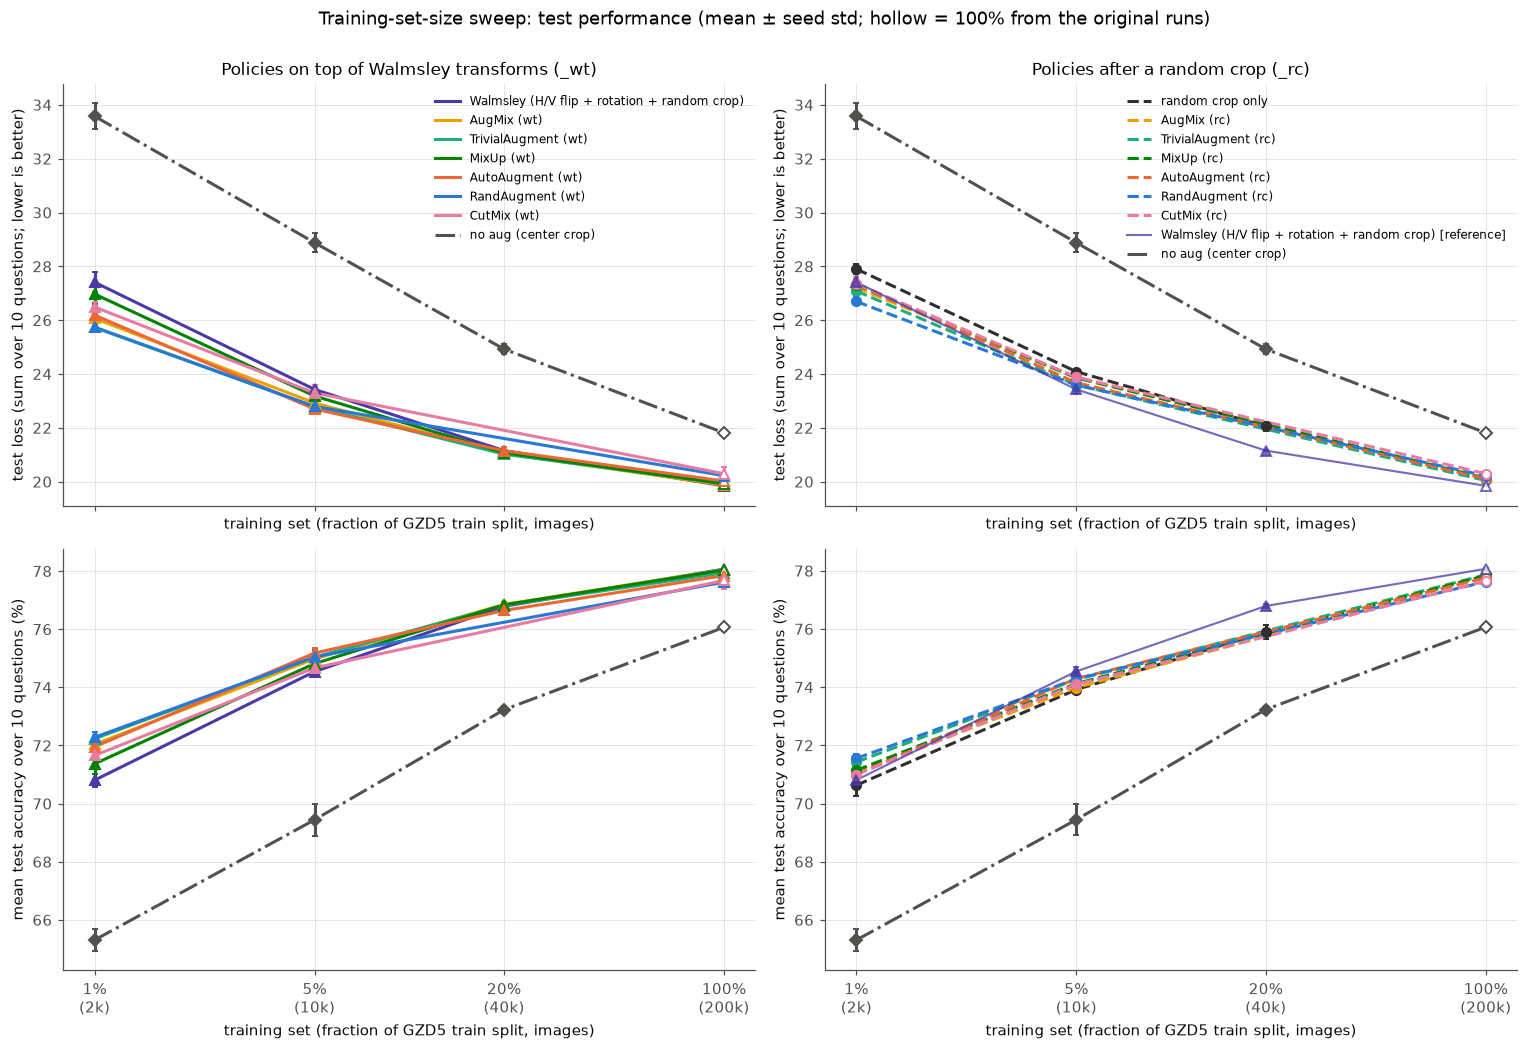

In [29]:
# ---- K.1 overall: test loss and mean accuracy vs training-set size
if not sweep_df.empty:
    fig, axes = plt.subplots(2, 2, figsize=(14, 9.5), sharex=True)
    groups = [("Policies on top of Walmsley transforms (_wt)", SW_WT + ["baseline_B"], None),
              ("Policies after a random crop (_rc)", SW_RC + ["walmsley_transforms", "baseline_B"], "walmsley_transforms")]
    for col, (title, exps, ref) in enumerate(groups):
        for row, (metric, ylabel, scale) in enumerate([("test_total_loss", "test loss (sum over 10 questions; lower is better)", 1),
                                                       ("mean_task_accuracy", "mean test accuracy over 10 questions (%)", 100)]):
            ax = axes[row, col]
            sw_plot_lines(ax, exps, metric, scale=scale, ref=ref)
            if row == 0:
                ax.set_title(title)
            ax.set_ylabel(ylabel)
            sw_xaxis(ax)
        axes[0, col].legend(fontsize=8, loc="upper right")
    fig.suptitle("Training-set-size sweep: test performance (mean ± seed std; hollow = 100% from the original runs)", y=1.0)
    fig.tight_layout()
    save(fig, "K_sweep_overall")
    plt.show()

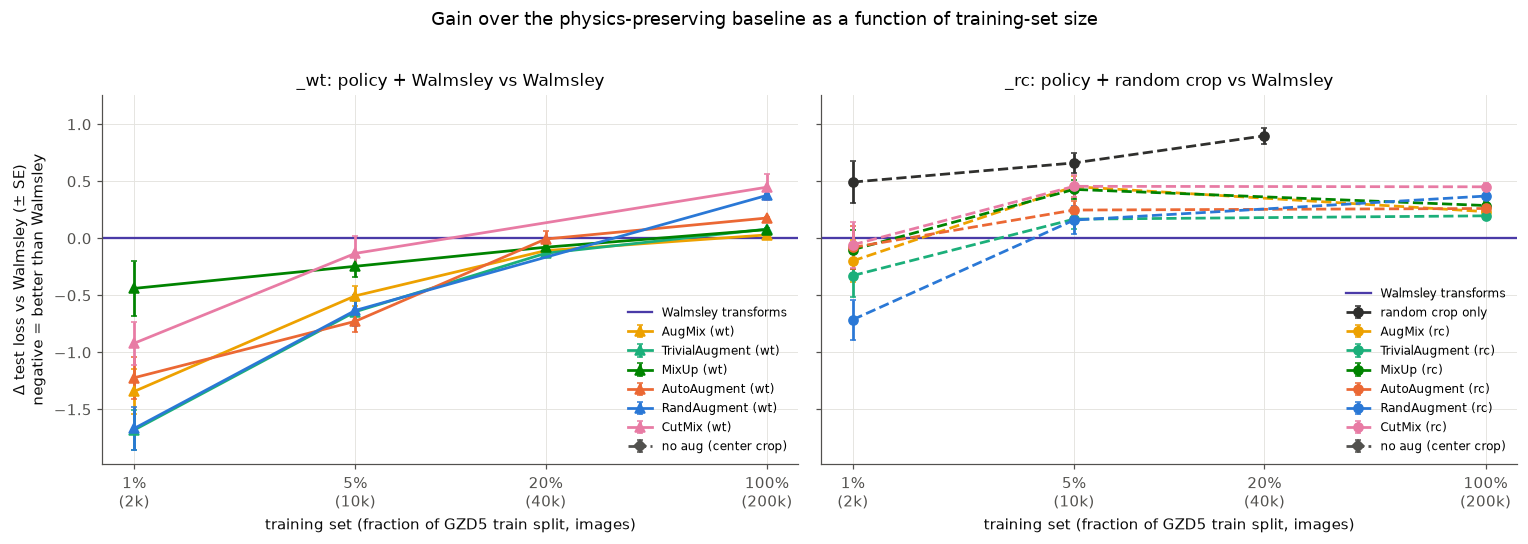

**Δ test loss vs `walmsley_transforms`, per fraction** (Welch; Holm within each fraction)

,fraction,experiment,n,n_ref,delta,se,p,p_holm,label
0,0.01,augmix_rc,5,5,-0.198,0.186,0.3302,1.0000,n.s.
1,0.01,augmix_wt,5,5,-1.343,0.194,0.0004,0.0044,better
2,0.01,auto_augment_rc,5,5,-0.080,0.190,0.6900,1.0000,n.s.
3,0.01,auto_augment_wt,5,5,-1.223,0.183,0.0009,0.0089,better
4,0.01,baseline_B,5,5,6.169,0.274,0.0000,0.0000,worse
5,0.01,baseline_rc,5,5,0.493,0.186,0.0405,0.2837,n.s.
6,0.01,cutmix_rc,5,5,-0.057,0.202,0.7864,1.0000,n.s.
7,0.01,cutmix_wt,5,5,-0.921,0.190,0.0029,0.0262,better
8,0.01,mixup_rc,5,5,-0.100,0.170,0.5878,1.0000,n.s.
9,0.01,mixup_wt,5,5,-0.439,0.239,0.1039,0.6236,n.s.


In [30]:
# ---- K.2 relative to Walmsley: does a policy beat the physics-preserving symmetries at this data size?
def sw_delta_table(metric="test_total_loss"):
    rows = []
    for f in sorted(sweep_df["fraction"].unique()):
        ref = sweep_df[(sweep_df["experiment"] == "walmsley_transforms") & (sweep_df["fraction"] == f)][metric].to_numpy()
        for e in SW_EXPS:
            if e == "walmsley_transforms":
                continue
            v = sweep_df[(sweep_df["experiment"] == e) & (sweep_df["fraction"] == f)][metric].to_numpy()
            if len(v) == 0 or len(ref) == 0:
                continue
            w = welch(v, ref)
            rows.append({"fraction": f, "experiment": e, "n": len(v), "n_ref": len(ref), "delta": w["d"],
                         "se": w["se"], "p": w["p"]})
    df = pd.DataFrame(rows)
    if len(df):
        df["p_holm"] = np.nan
        for f, idx in df.groupby("fraction").groups.items():
            df.loc[idx, "p_holm"] = holm(df.loc[idx, "p"])
        better = df["delta"] < 0 if metric == "test_total_loss" else df["delta"] > 0
        df["label"] = np.where(df["p_holm"] < ALPHA, np.where(better, "better", "worse"), "n.s.")
    return df


if not sweep_df.empty and "walmsley_transforms" in SW_EXPS:
    sweep_vs_walmsley = sw_delta_table("test_total_loss")
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
    for ax, (title, exps) in zip(axes, [("_wt: policy + Walmsley vs Walmsley", SW_WT[1:] + ["baseline_B"]),
                                        ("_rc: policy + random crop vs Walmsley", SW_RC + ["baseline_B"])]):
        ax.axhline(0, color=REF_COLOR, lw=1.5, label="Walmsley transforms")
        for e in exps:
            d = sweep_vs_walmsley[sweep_vs_walmsley["experiment"] == e].sort_values("fraction")
            if d.empty:
                continue
            st = sw_style(e)
            ax.errorbar(d["fraction"], d["delta"], yerr=d["se"].fillna(0), color=st["color"], ls=st["ls"],
                        marker=st["marker"], ms=6, capsize=2, lw=1.8, label=sw_label(e))
        ax.set_title(title)
        sw_xaxis(ax)
        ax.legend(fontsize=8)
    axes[0].set_ylabel("Δ test loss vs Walmsley (± SE)\nnegative = better than Walmsley")
    lo, hi = sweep_vs_walmsley["delta"].quantile([0.0, 0.9])     # keep the no-augmentation outlier from flattening the plot
    for ax in axes:
        ax.set_ylim(min(lo, 0) - 0.3, max(hi, 0) + 0.5)
    fig.suptitle("Gain over the physics-preserving baseline as a function of training-set size", y=1.02)
    fig.tight_layout()
    save(fig, "K_sweep_delta_vs_walmsley")
    plt.show()
    display(Markdown("**Δ test loss vs `walmsley_transforms`, per fraction** (Welch; Holm within each fraction)"))
    display(sweep_vs_walmsley.round({"delta": 3, "se": 3, "p": 4, "p_holm": 4}))

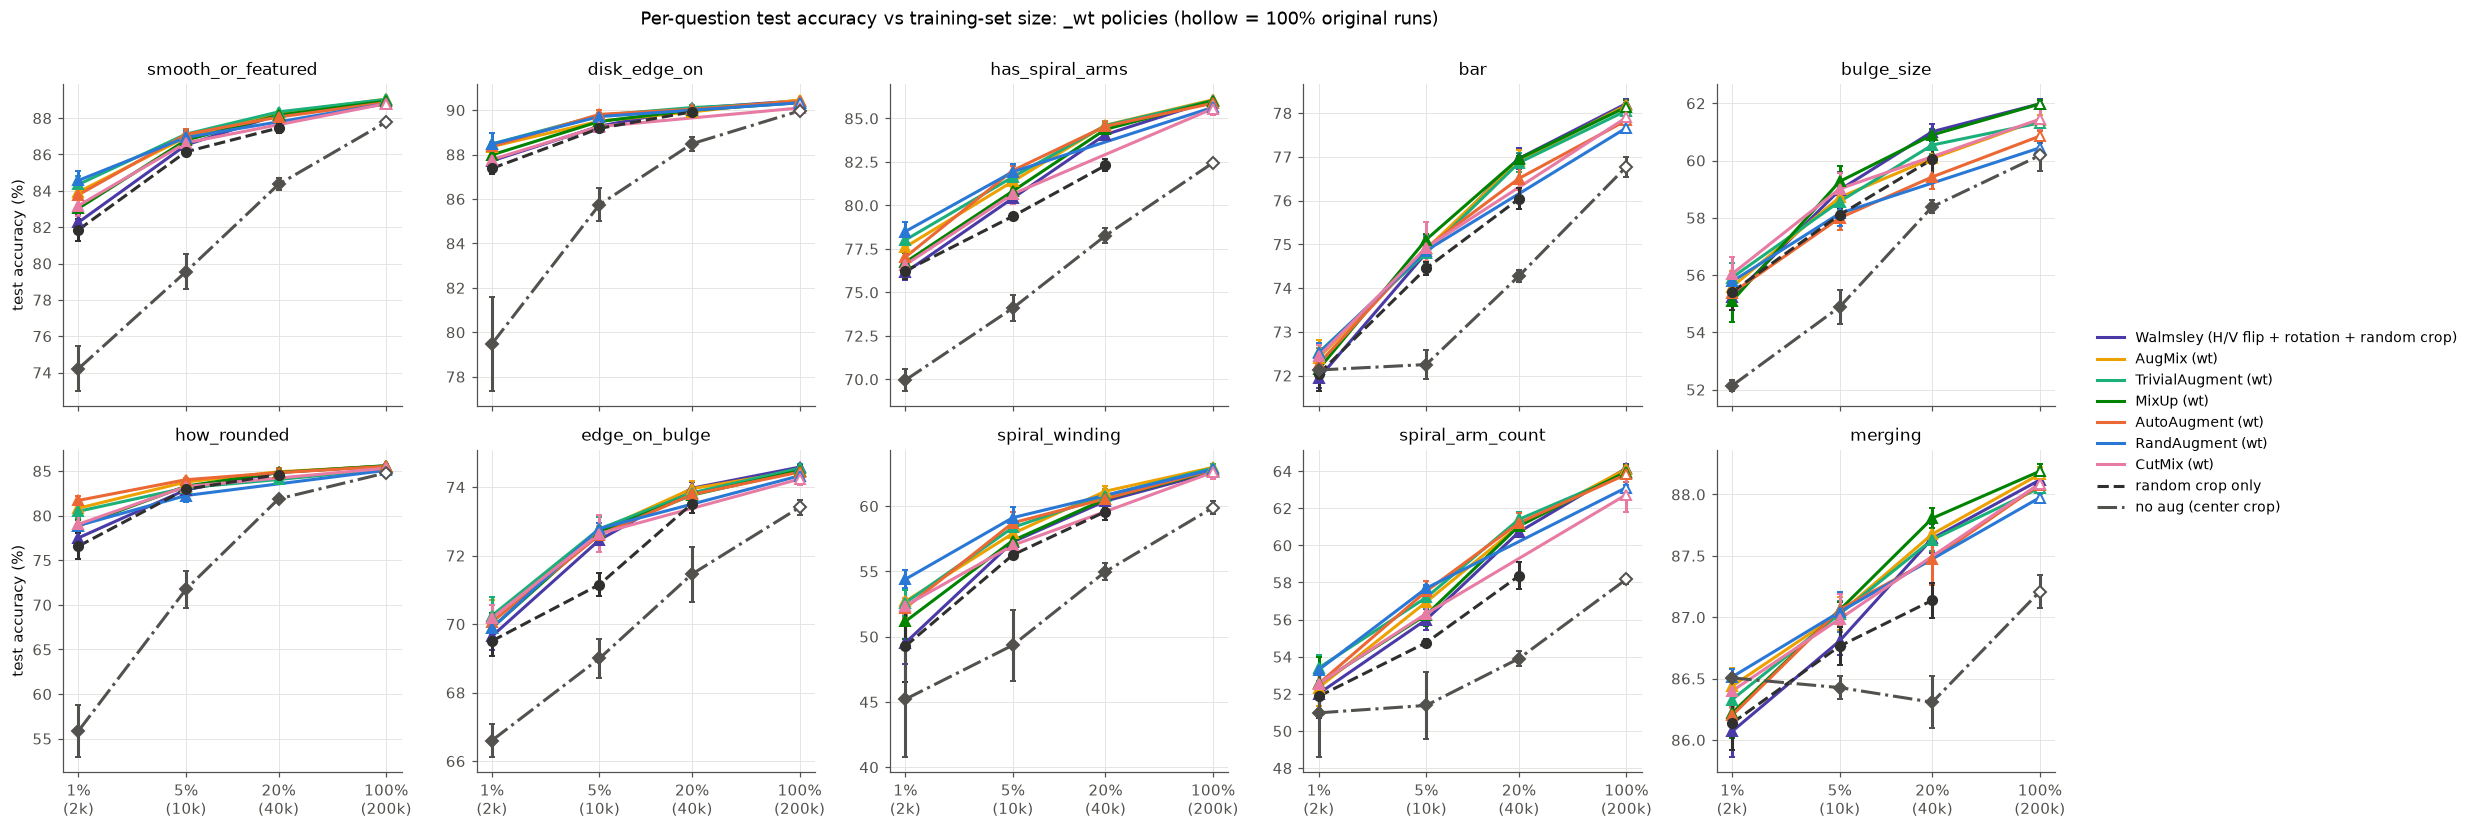

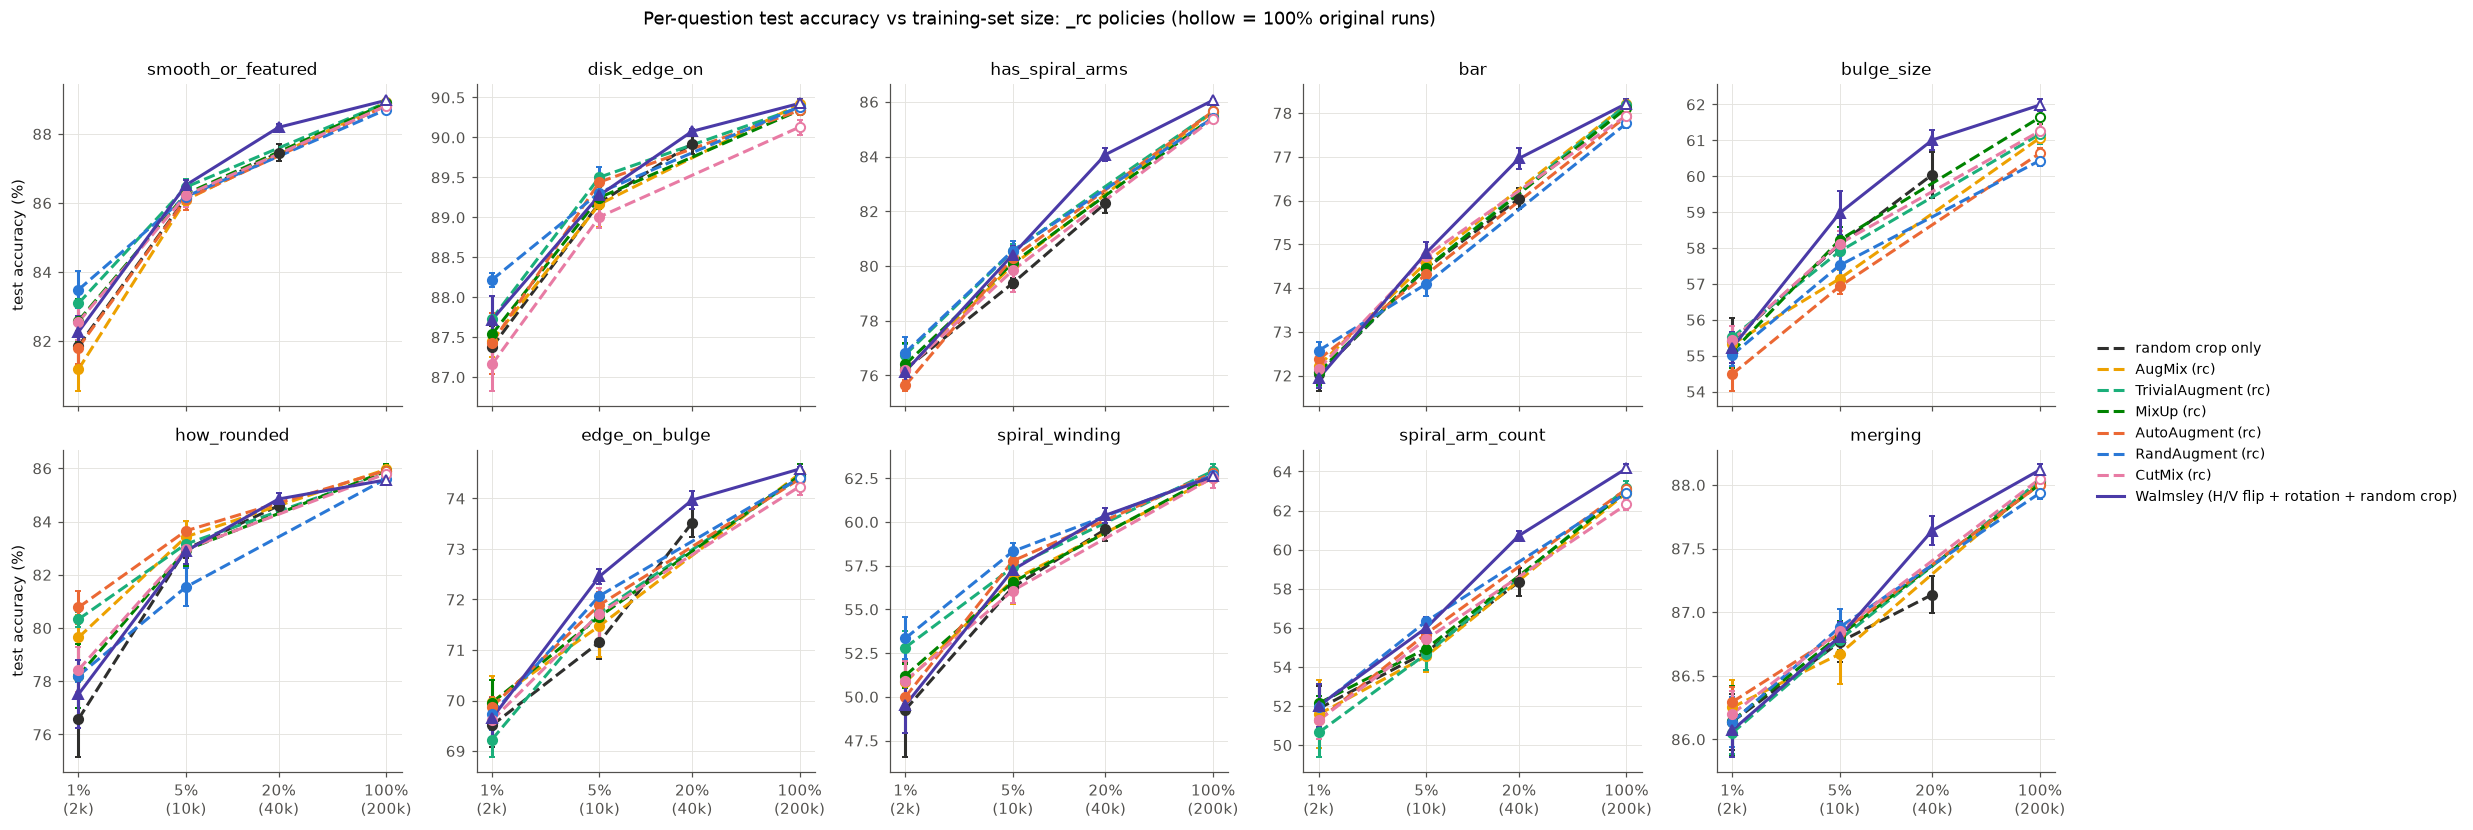

In [31]:
# ---- K.3 per question: test accuracy vs training-set size
if not sweep_df.empty:
    for title, exps, name in [("_wt policies", SW_WT + ["baseline_rc", "baseline_B"], "K_sweep_per_question_wt"),
                              ("_rc policies", SW_RC + ["walmsley_transforms"], "K_sweep_per_question_rc")]:
        fig, axes = plt.subplots(2, 5, figsize=(19, 7.5), sharex=True)
        for ax, t in zip(axes.flat, TASKS):
            sw_plot_lines(ax, exps, f"test_{t}_accuracy", scale=100)
            ax.set_title(t)
            sw_xaxis(ax)
            ax.set_xlabel("")
        for ax in axes[:, 0]:
            ax.set_ylabel("test accuracy (%)")
        handles, labels = axes[0, 0].get_legend_handles_labels()
        fig.legend(handles, labels, loc="center left", bbox_to_anchor=(1.0, 0.5), fontsize=9)
        fig.suptitle(f"Per-question test accuracy vs training-set size: {title} (hollow = 100% original runs)", y=1.0)
        fig.tight_layout()
        save(fig, name)
        plt.show()

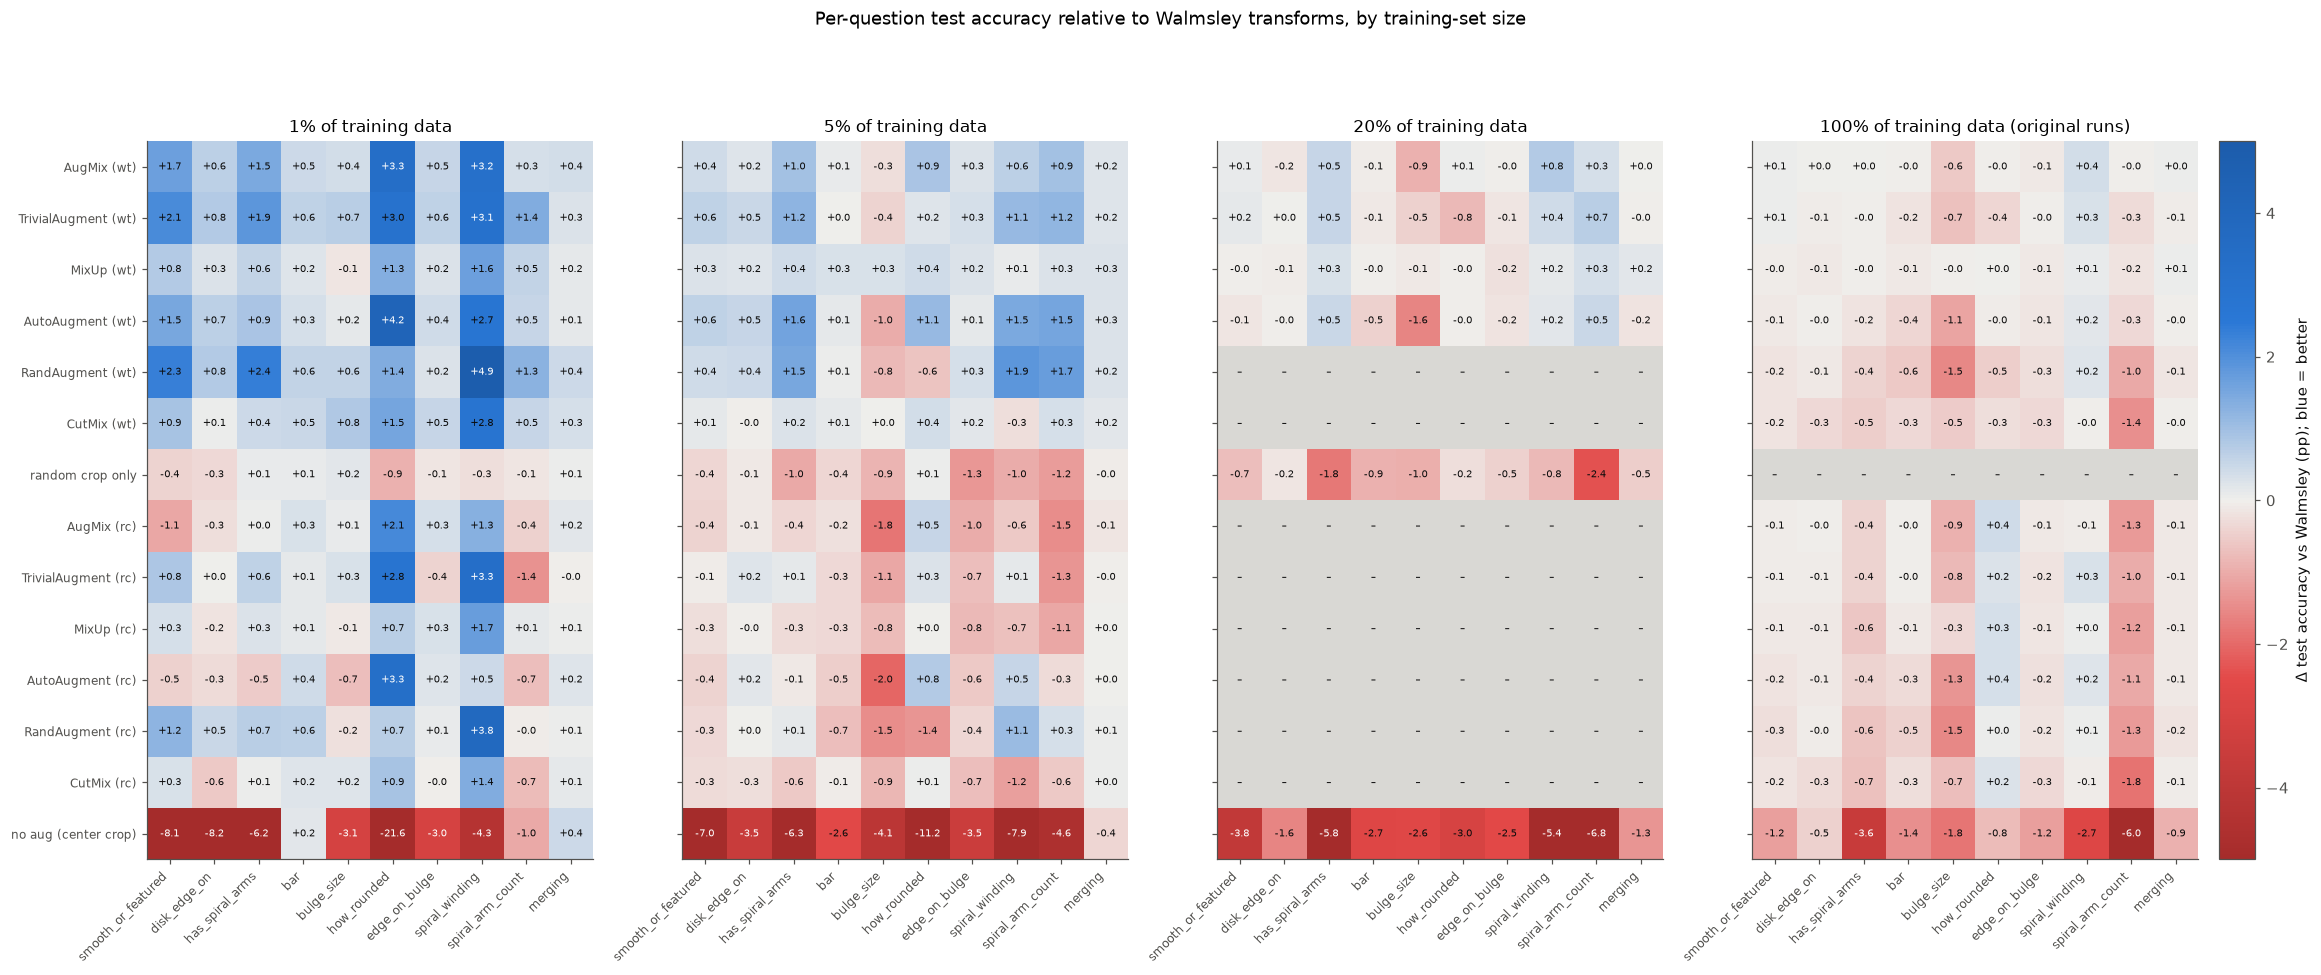

In [32]:
# ---- K.4 per question, relative to Walmsley: one heatmap per training fraction
if not sweep_df.empty and "walmsley_transforms" in SW_EXPS:
    fracs = sorted(sweep_agg["fraction"].unique())
    order = [e for e in SW_WT[1:] + SW_RC + ["baseline_B"] if e in SW_EXPS]
    order = [e for e in order if e in set(sweep_agg["experiment"])]
    mats = {}                                   # same rows in every panel; NaN where an experiment has no runs yet
    for f in fracs:
        a = sweep_agg[sweep_agg["fraction"] == f].set_index("experiment")
        if "walmsley_transforms" not in a.index:
            continue
        ref = a.loc["walmsley_transforms", [f"{c}_mean" for c in SW_TASK_ACC]].to_numpy(dtype=float)
        M = np.full((len(order), len(SW_TASK_ACC)), np.nan)
        for i, e in enumerate(order):
            if e in a.index:
                M[i] = 100 * (a.loc[e, [f"{c}_mean" for c in SW_TASK_ACC]].to_numpy(dtype=float) - ref)
        mats[f] = (order, M)
    if mats:
        vmax = max(np.nanmax(np.abs(m)) for _, m in mats.values()) or 1.0
        vmax = min(vmax, 5.0)                       # colour scale capped at ±5 pp; the cell labels give the values
        fig, axes = plt.subplots(1, len(mats), figsize=(6.2 * len(mats), 0.42 * len(order) + 2.6), squeeze=False)
        for ax, (f, (rows, M)) in zip(axes[0], mats.items()):
            cmap = DIVERGING.copy()
            cmap.set_bad("#d9d8d4")
            im = ax.imshow(np.ma.masked_invalid(M), cmap=cmap, norm=TwoSlopeNorm(0, -vmax, vmax), aspect="auto")
            for i in range(M.shape[0]):
                for j in range(M.shape[1]):
                    ax.text(j, i, "–" if np.isnan(M[i, j]) else f"{M[i, j]:+.1f}", ha="center", va="center",
                            fontsize=6.5, color="white" if abs(np.nan_to_num(M[i, j])) > 0.6 * vmax else INK)
            ax.set_xticks(range(len(TASKS)), TASKS, rotation=45, ha="right", fontsize=8)
            ax.set_yticks(range(len(rows)), [sw_label(e) for e in rows] if ax is axes[0, 0] else [""] * len(rows), fontsize=8)
            ax.grid(False)
            src = sweep_agg[sweep_agg["fraction"] == f]["source"].iloc[0]
            ax.set_title(f"{f:.0%} of training data" + (" (original runs)" if src != "sweep" else ""))
        fig.colorbar(im, ax=axes[0].tolist(), fraction=0.02, pad=0.01,
                     label="Δ test accuracy vs Walmsley (pp); blue = better")
        fig.suptitle("Per-question test accuracy relative to Walmsley transforms, by training-set size", y=1.02)
        save(fig, "K_sweep_question_heatmaps")
        plt.show()

In [33]:
# ---- K.5 summary table and export
if not sweep_df.empty:
    summary = sweep_agg.pivot_table(index="experiment", columns="fraction",
                                    values=["test_total_loss_mean", "mean_task_accuracy_mean"])
    summary.columns = [f"{'loss' if m.startswith('test_total') else 'acc'} {f:.0%}" for m, f in summary.columns]
    summary = summary[[c for c in summary.columns if c.startswith("loss")] + [c for c in summary.columns if c.startswith("acc")]]
    summary = summary.sort_values(summary.columns[0])
    display(Markdown("**Mean test loss and mean accuracy per experiment and training fraction**"))
    display(summary.round(3))
    hours = sweep_df[sweep_df["source"] == "sweep"].groupby("fraction")["train_hours"].median()
    print("median training time per run (h):", {f"{k:.0%}": round(v, 2) for k, v in hours.items()})
    written = [export(sweep_df, "sweep_per_run"), export(sweep_agg, "sweep_aggregated"),
               export(summary.reset_index(), "sweep_summary", tex=False)]
    if "sweep_vs_walmsley" in globals():
        written.append(export(sweep_vs_walmsley, "sweep_vs_walmsley"))

    # paper table: mean test accuracy (mean +- std over seeds) per experiment and training fraction
    fr = sorted(sweep_agg["fraction"].unique())
    a = sweep_agg.set_index(["experiment", "fraction"])
    groups = paper_groups(set(sweep_agg["experiment"]))
    shown = [e for _, rows in groups for e in rows]
    best_a = {f: a.loc[[(e, f) for e in shown if (e, f) in a.index], "mean_task_accuracy_mean"].max() for f in fr}
    old = [f for f in fr if (a.xs(f, level="fraction")["source"] != "sweep").any()]
    head = [f"{100 * f:g}\\%" + ("$^{a}$" if f in old else "") for f in fr]
    ncol = 1 + len(fr)
    lines = [r"\begin{table*}", r"\centering", r"\footnotesize", r"\setlength{\tabcolsep}{5pt}",
             r"\caption{Mean test accuracy over the ten Galaxy Zoo questions (accuracy of the most-voted answer, per cent; "
             r"mean $\pm$ standard deviation over five seeds) against the fraction of the training set used. The training "
             r"subsets are fixed and nested. Policies are at their standard strength. The best value in each column is in "
             r"bold. "
             + (r"$^{a}$Full-data runs, trained with the original 100-epoch cosine schedule. " if old else "")
             + r"Dashes mark runs that are not available.}",
             r"\label{tab:sweep}",
             f"\\begin{{tabular}}{{l{'c' * len(fr)}}}", r"\toprule",
             f" & \\multicolumn{{{len(fr)}}}{{c}}{{Fraction of the training set}} \\\\",
             f"\\cmidrule(lr){{2-{ncol}}}",
             "Augmentation & " + " & ".join(head) + r" \\", r"\midrule"]
    for gi, (title, rows) in enumerate(groups):
        if gi:
            lines.append(r"\midrule")
        lines.append(f"\\multicolumn{{{ncol}}}{{l}}{{\\textit{{{title}}}}} \\\\")
        for e in rows:
            cells = [f"\\quad {tex_escape(paper_name(e))}"]
            for f in fr:
                if (e, f) not in a.index:
                    cells.append("--")
                    continue
                m, s_ = 100 * a.at[(e, f), "mean_task_accuracy_mean"], 100 * a.at[(e, f), "mean_task_accuracy_std"]
                mm = f"\\mathbf{{{m:.2f}}}" if np.isclose(m / 100, best_a[f]) else f"{m:.2f}"
                cells.append(f"${mm} \\pm {s_:.2f}$" if np.isfinite(s_) else f"${mm}$")
            lines.append(" & ".join(cells) + r" \\")
    lines += [r"\bottomrule", r"\end{tabular}", r"\end{table*}"]
    (TABLE_DIR / "sweep_summary.tex").write_text("\n".join(lines) + "\n")
    print(f"tables ({TABLE_DIR}/): {', '.join(written)}; sweep_summary.tex is the paper table")

**Mean test loss and mean accuracy per experiment and training fraction**

,loss 1%,loss 5%,loss 20%,loss 100%,acc 1%,acc 5%,acc 20%,acc 100%
experiment,,,,,,,,
trivial_augment_wt,25.728,22.784,21.024,19.927,0.722,0.750,0.768,0.779
rand_augment_all_ops_wt,25.742,22.795,NaN,20.222,0.723,0.750,NaN,0.776
augmix_wt,26.067,22.923,21.047,19.876,0.720,0.750,0.769,0.780
auto_augment_wt,26.187,22.700,21.149,20.024,0.720,0.752,0.766,0.778
cutmix_wt,26.489,23.296,NaN,20.295,0.717,0.747,NaN,0.777
rand_augment_all_ops_rc,26.696,23.588,NaN,20.217,0.716,0.743,NaN,0.776
mixup_wt,26.970,23.182,21.077,19.923,0.714,0.748,0.768,0.780
trivial_augment_rc,27.083,23.596,NaN,20.043,0.714,0.743,NaN,0.779
augmix_rc,27.211,23.881,NaN,20.080,0.711,0.740,NaN,0.778


median training time per run (h): {'1%': 1.9, '5%': 4.78, '20%': 12.81}
tables (results/tables/): sweep_per_run, sweep_aggregated, sweep_summary, sweep_vs_walmsley; sweep_summary.tex is the paper table
